# 3.0-Second CRNN-GRU Model Training: 3.0-Second CRNN-GRU Model Training, Evaluation, and INT8 Quantization

This notebook conducts end-to-end training, evaluation, and full INT8 post-training quantization for the **3.0-second** temporal resolution Philippine eagle call classifier:
- **3.0s Recording Split**: Grouped by recording source, leak-free, augmented samples in train only
- **3.0s Leave-One-Site-Out (LOSO) - Davao del Sur**: Geographic generalization benchmark
- **3.0s Leave-One-Site-Out (LOSO) - Cotabato**: Geographic generalization benchmark
- **INT8 Post-Training Quantization**: Edge MCU optimization with representative calibration


## 1. Imports and Configuration


In [1]:
import os
import sys
import time
import json
import gc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import tensorflow as tf
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    precision_recall_curve, roc_curve, auc
)

# Suppress minor warnings and configure styling
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 150

# Reproducibility Seeds
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# Configure GPU Memory Growth to prevent OOM
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(f'Memory growth setting failed: {e}')

# Project Paths
def find_project_root():
    p = Path.cwd().resolve()
    while p != p.parent:
        if (p / "data").exists() and (p / "AGENTS.md").exists():
            return p
        p = p.parent
    return Path.cwd().resolve().parent.parent

PROJECT_ROOT = find_project_root()
EXPERIMENT_DIR = Path.cwd().resolve()
OUTPUTS_DIR = EXPERIMENT_DIR / "outputs"
MODELS_DIR = EXPERIMENT_DIR / "models"
DATA_DIR = PROJECT_ROOT / "data"
FEATURES_DIR = DATA_DIR / "features"



# 3.0s outputs are grouped per model: outputs/3-seconds/<model>/<partition>/
OUTPUTS_3S_DIR = OUTPUTS_DIR / "3-seconds"
SPLITS_DIR = OUTPUTS_3S_DIR / "splits"      # split distribution and leak check figures, shared by all models
SUMMARY_DIR = OUTPUTS_3S_DIR / "summary"    # tables and figures that compare models

for d in [SPLITS_DIR, SUMMARY_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# 5.0s and 3.0s Feature Paths
FEATURES_5S_DIR = FEATURES_DIR / "5-seconds" / "pcen-melSpectrogram"
META_5S_PATH = FEATURES_5S_DIR / "features_metadata.csv"
if not META_5S_PATH.exists():
    META_5S_PATH = FEATURES_DIR / "5-seconds" / "features_metadata.csv"

FEATURES_3S_DIR = FEATURES_DIR / "3-seconds" / "pcen-melSpectrogram"
META_3S_PATH = FEATURES_3S_DIR / "features_metadata.csv"
if not META_3S_PATH.exists():
    META_3S_PATH = FEATURES_DIR / "3-seconds" / "features_metadata.csv"

# Log-Mel features of the same 3.0s windows, used by the published baseline and the first ablation step
FEATURES_3S_LOGMEL_DIR = FEATURES_DIR / "3-seconds" / "melSpectrogram"

# Model Checkpoints Output Directories
MODELS_5S_STD = MODELS_DIR / "5-seconds" / "standard"
MODELS_5S_LOSO_DAVAO = MODELS_DIR / "5-seconds" / "loso-davao"
MODELS_5S_LOSO_COTABATO = MODELS_DIR / "5-seconds" / "loso-cotabato"

MODELS_3S_STD = MODELS_DIR / "3-seconds" / "standard"
MODELS_3S_LOSO_DAVAO = MODELS_DIR / "3-seconds" / "loso-davao"
MODELS_3S_LOSO_COTABATO = MODELS_DIR / "3-seconds" / "loso-cotabato"

for d in [MODELS_5S_STD, MODELS_5S_LOSO_DAVAO, MODELS_5S_LOSO_COTABATO,
          MODELS_3S_STD, MODELS_3S_LOSO_DAVAO, MODELS_3S_LOSO_COTABATO]:
    (d / "checkpoints").mkdir(parents=True, exist_ok=True)

# Training Hyperparameters
BATCH_SIZE = 32
EPOCHS = 50
PATIENCE = 10
LEARNING_RATE = 1e-3
SHAPE_5S = (128, 216, 1)
SHAPE_3S = (128, 130, 1)
NOTEBOOK_ID = "crnn-gru-training"

print("=" * 60)
print("EXPERIMENT ENVIRONMENT CONFIGURED")
print("=" * 60)
print(f"TensorFlow Version: {tf.__version__}")
print(f"Available GPUs:     {tf.config.list_physical_devices('GPU')}")
print(f"Project Root:       {PROJECT_ROOT}")
print(f"5.0s Features Path: {FEATURES_5S_DIR}")
print(f"3.0s Features Path: {FEATURES_3S_DIR}")
print("=" * 60)


I0000 00:00:1791900789.700841   59966 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791900789.738393   59966 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791900790.565363   59966 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


EXPERIMENT ENVIRONMENT CONFIGURED
TensorFlow Version: 2.21.0
Available GPUs:     [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Project Root:       /home/fumei/Documents/MachineLearning/EagleSoundClassification
5.0s Features Path: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/5-seconds/pcen-melSpectrogram
3.0s Features Path: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/pcen-melSpectrogram


## 2. Load 3.0-Second Dataset and Feature Arrays


### 2.1 Load 3.0-Second Feature Arrays (128, 130)


In [2]:
# Load 3.0-second features metadata and arrays (Guarded)
if META_3S_PATH.exists():
    df_meta_3s = pd.read_csv(META_3S_PATH)
    df_clean_3s = df_meta_3s[~df_meta_3s["has_ambiguous"]].reset_index(drop=True)
    num_samples_3s = len(df_clean_3s)

    X_all_3s = np.zeros((num_samples_3s, 128, 130, 1), dtype=np.float32)
    print(f"Loading {num_samples_3s} 3.0s PCEN Mel Spectrogram arrays into memory...")
    for i, row in enumerate(tqdm(df_clean_3s.itertuples(), total=num_samples_3s, desc="Loading 3s features")):
        arr_path = FEATURES_3S_DIR / row.feature_file
        arr = np.load(arr_path)
        t_frames = min(arr.shape[1], 130)
        X_all_3s[i, :, :t_frames, 0] = arr[:, :t_frames]

    y_all_3s = df_clean_3s["label"].values.astype(np.float32)
    groups_all_3s = df_clean_3s["source_audio"].values
    sites_all_3s = df_clean_3s["site"].values
    is_aug_all_3s = df_clean_3s["is_augmented"].values

    print(f"\n3.0s Feature tensor shape: {X_all_3s.shape} ({X_all_3s.nbytes / (1024**2):.1f} MB in RAM)")
    print(f"3.0s Label tensor shape:   {y_all_3s.shape} (Positives: {int(np.sum(y_all_3s == 1)):,}, Negatives: {int(np.sum(y_all_3s == 0)):,})")
    print(f"3.0s Augmented samples:    {int(np.sum(is_aug_all_3s)):,} / {len(is_aug_all_3s):,}")
else:
    print(f"Notice: 3.0s metadata not found at {META_3S_PATH}. 3.0s experiments will be skipped if features are absent.")


Loading 14421 3.0s PCEN Mel Spectrogram arrays into memory...


Loading 3s features:   0%|          | 0/14421 [00:00<?, ?it/s]


3.0s Feature tensor shape: (14421, 128, 130, 1) (915.4 MB in RAM)
3.0s Label tensor shape:   (14421,) (Positives: 6,674, Negatives: 7,747)
3.0s Augmented samples:    3,337 / 14,421


## 3. Model Architecture, INT8 Quantization, and Training Pipeline Utilities


In [3]:
def build_crnn_gru_model(input_shape, learning_rate=LEARNING_RATE, bn_momentum=0.99):
    """
    Streamlined CRNN-GRU architecture with dynamic sequence unrolling:
    - 3 Conv2D blocks ordered Conv -> BatchNorm -> ReLU -> MaxPool
      (BatchNorm sits right after the convolution so TFLite can fold it into the conv weights)
    - Spatial-to-temporal transformation (time dimension dynamically calculated)
    - Unrolled GRU layer (compatible with full TFLite INT8 post-training quantization)
    - Regularized Dense classification output
    """
    inputs = tf.keras.Input(shape=input_shape, batch_size=None, name="audio_input")

    # Conv Block 1 (Conv -> BN -> ReLU)
    x = tf.keras.layers.Conv2D(32, (3, 3), padding="same", use_bias=False, name="conv1")(inputs)
    x = tf.keras.layers.BatchNormalization(momentum=bn_momentum, name="bn1")(x)
    x = tf.keras.layers.ReLU(name="relu1")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), name="pool1")(x)

    # Conv Block 2 (Conv -> BN -> ReLU)
    x = tf.keras.layers.Conv2D(64, (3, 3), padding="same", use_bias=False, name="conv2")(x)
    x = tf.keras.layers.BatchNormalization(momentum=bn_momentum, name="bn2")(x)
    x = tf.keras.layers.ReLU(name="relu2")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), name="pool2")(x)

    # Conv Block 3 (Conv -> BN -> ReLU)
    x = tf.keras.layers.Conv2D(128, (3, 3), padding="same", use_bias=False, name="conv3")(x)
    x = tf.keras.layers.BatchNormalization(momentum=bn_momentum, name="bn3")(x)
    x = tf.keras.layers.ReLU(name="relu3")(x)
    x = tf.keras.layers.MaxPooling2D((4, 2), name="pool3")(x)

    # Dynamic time-step calculation: 216 // 8 = 27 for 5s; 130 // 8 = 16 for 3s
    time_steps = input_shape[1] // 8

    # Permute to (batch, time, freq, channels) -> Reshape to (batch, time_steps, 8 * 128 = 1024)
    x = tf.keras.layers.Permute((2, 1, 3), name="permute_time_first")(x)
    x = tf.keras.layers.Reshape((time_steps, -1), name="time_flatten")(x)

    # Recurrent Layer (Unrolled for full TFLite INT8 compatibility on edge MCUs)
    x = tf.keras.layers.GRU(64, return_sequences=False, unroll=True, name="recurrent_gru")(x)
    x = tf.keras.layers.Dropout(0.3, name="gru_dropout")(x)

    # Dense Output
    x = tf.keras.layers.Dense(32, activation="relu", name="dense1")(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="eagle_prob")(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="CRNN_GRU_Eagle_Classifier")
    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=0.5)
    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )
    return model


def make_warmup_cosine_callback(target_lr=5e-4, start_lr=1e-4, min_lr=1e-5, warmup_epochs=3, total_epochs=EPOCHS):
    """
    Learning rate schedule: linear warmup from start_lr to target_lr,
    then cosine decay down to min_lr by the last epoch.
    """
    def warmup_cosine_lr(epoch, lr):
        if epoch < warmup_epochs:
            return start_lr + (target_lr - start_lr) * ((epoch + 1) / warmup_epochs)
        progress = (epoch - warmup_epochs) / max(1, (total_epochs - warmup_epochs))
        return min_lr + 0.5 * (target_lr - min_lr) * (1.0 + np.cos(np.pi * progress))

    return tf.keras.callbacks.LearningRateScheduler(warmup_cosine_lr, verbose=0)


class SpecAugmentDataGenerator(tf.keras.utils.Sequence):
    """
    On-the-fly SpecAugment data generator for robust audio spectrogram training:
    - Subtle Gain Scaling (0.85x to 1.15x) applied to both classes (simulating distance variation)
    - SpecAugment Frequency Masking (up to F mel bins) applied to positive eagle calls
    - SpecAugment Time Masking (up to T time steps) applied to positive eagle calls
    - mask_all_classes=True applies both masks to every sample, so a mask is not a cue for the eagle class
    Validation and Test sets should use clean arrays directly without generator masking.
    """
    def __init__(self, X, y, batch_size=BATCH_SIZE, is_training=True,
                 freq_mask_max=12, time_mask_max=15,
                 gain_min=0.85, gain_max=1.15,
                 p_gain=0.5, p_freq=0.5, p_time=0.5,
                 shuffle=True, seed=SEED, mask_all_classes=False):
        self.X = X
        self.y = y
        self.batch_size = batch_size
        self.is_training = is_training
        self.freq_mask_max = freq_mask_max
        self.time_mask_max = time_mask_max
        self.gain_min = gain_min
        self.gain_max = gain_max
        self.p_gain = p_gain
        self.p_freq = p_freq
        self.p_time = p_time
        self.shuffle = shuffle
        self.mask_all_classes = mask_all_classes
        self.rng = np.random.default_rng(seed)
        self.indices = np.arange(len(self.X))
        if self.shuffle:
            self.rng.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.X) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.indices)

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size:(idx + 1) * self.batch_size]
        X_batch = np.copy(self.X[batch_idx])
        y_batch = np.copy(self.y[batch_idx])

        if self.is_training:
            for i in range(len(X_batch)):
                # 1. Subtle Gain Scaling (both classes)
                if self.rng.random() < self.p_gain:
                    gain = self.rng.uniform(self.gain_min, self.gain_max)
                    X_batch[i] = X_batch[i] * gain

                # 2. SpecAugment Masking (eagle calls only, or every sample if mask_all_classes)
                if self.mask_all_classes or y_batch[i] == 1.0:
                    # Frequency Masking (horizontal band)
                    if self.rng.random() < self.p_freq:
                        f_width = int(self.rng.integers(1, self.freq_mask_max + 1))
                        f_start = int(self.rng.integers(0, max(1, X_batch.shape[1] - f_width)))
                        X_batch[i, f_start:f_start + f_width, :, :] = 0.57

                    # Time Masking (vertical band)
                    if self.rng.random() < self.p_time:
                        t_width = int(self.rng.integers(1, self.time_mask_max + 1))
                        t_start = int(self.rng.integers(0, max(1, X_batch.shape[2] - t_width)))
                        X_batch[i, :, t_start:t_start + t_width, :] = 0.57

        return X_batch, y_batch


def create_recording_split(df_clean, train_ratio=0.70, val_ratio=0.15, random_state=SEED):
    """
    Recording-level split: every source recording is assigned to exactly one subset.
    1. Recordings are grouped into strata: eagle recordings by site (the two main sites, and the
       smaller sites together) and hard-negative recordings by species.
    2. Within each stratum the recordings are shuffled and divided into Train, Val, and Test.
    3. All clips of a recording follow it. Augmented clips are kept only for Train recordings.
    Returns the train, val, and test indices and a table with the subset of every recording.
    """
    df_orig = df_clean[~df_clean["is_augmented"]]
    recordings = df_orig.groupby("source_audio").agg(
        dataset_source=("dataset_source", "first"),
        site=("site", "first"),
        species=("species", "first"),
        clips=("label", "size"),
        eagle_clips=("label", "sum"),
    ).reset_index()

    main_sites = {"Davao del Sur", "Cotabato"}
    is_eagle_recording = recordings["dataset_source"] == "eagle-audios"
    recordings["stratum"] = np.where(
        is_eagle_recording,
        "eagle | " + recordings["site"].where(recordings["site"].isin(main_sites), "other sites"),
        "hard negative | " + recordings["species"],
    )

    rng = np.random.default_rng(random_state)
    test_ratio = 1.0 - train_ratio - val_ratio
    assignment = {}
    for _, group in recordings.groupby("stratum", sort=True):
        names = rng.permutation(np.sort(group["source_audio"].values))
        n = len(names)
        n_test = max(1, int(round(n * test_ratio))) if n >= 3 else 0
        n_val = max(1, int(round(n * val_ratio))) if n >= 3 else 0
        for position, name in enumerate(names):
            assignment[name] = "test" if position < n_test else ("val" if position < n_test + n_val else "train")

    recordings["split"] = recordings["source_audio"].map(assignment)
    clip_split = df_clean["source_audio"].map(assignment).values
    is_aug = df_clean["is_augmented"].values

    train_idx = np.where(clip_split == "train")[0]
    val_idx = np.where((clip_split == "val") & ~is_aug)[0]
    test_idx = np.where((clip_split == "test") & ~is_aug)[0]
    return train_idx, val_idx, test_idx, recordings


def split_overlap_matrices(df_clean, train_idx, val_idx, test_idx):
    """Recordings and clips shared between each pair of subsets. The diagonal holds the size of each subset."""
    names = ["Train", "Val", "Test"]
    sources = df_clean["source_audio"].values
    clip_sets = [set(np.asarray(idx).tolist()) for idx in (train_idx, val_idx, test_idx)]
    recording_sets = [set(sources[np.asarray(idx)]) for idx in (train_idx, val_idx, test_idx)]
    recording_overlap = pd.DataFrame([[len(a & b) for b in recording_sets] for a in recording_sets], index=names, columns=names)
    clip_overlap = pd.DataFrame([[len(a & b) for b in clip_sets] for a in clip_sets], index=names, columns=names)
    return recording_overlap, clip_overlap


def assert_no_leakage(df_clean, train_idx, val_idx, test_idx):
    """Stop with an error if a recording or a clip is in two subsets, or if an augmented clip is outside Train."""
    recording_overlap, clip_overlap = split_overlap_matrices(df_clean, train_idx, val_idx, test_idx)
    off_diagonal = lambda m: int(m.values.sum() - np.trace(m.values))
    assert off_diagonal(recording_overlap) == 0, f"Recordings shared between subsets:\n{recording_overlap}"
    assert off_diagonal(clip_overlap) == 0, f"Clips shared between subsets:\n{clip_overlap}"

    is_aug = df_clean["is_augmented"].values
    sources = df_clean["source_audio"].values
    assert not is_aug[val_idx].any(), "Augmented clips found in Val"
    assert not is_aug[test_idx].any(), "Augmented clips found in Test"
    train_original_recordings = set(sources[train_idx][~is_aug[train_idx]])
    assert set(sources[train_idx][is_aug[train_idx]]) <= train_original_recordings, "Augmented clip from a recording outside Train"
    return recording_overlap, clip_overlap


def create_loso_split(df_clean, holdout_site, val_ratio=0.15, random_state=SEED):
    """
    Leak-free Leave-One-Site-Out (LOSO) split:
    1. Test set consists ONLY of unaugmented samples from the holdout site (one site name or a list of sites).
    2. Remaining sites form the train pool (unaugmented).
    3. GroupShuffleSplit partitions train pool into Train and Val by source_audio.
    4. Augmented samples from training sources are injected ONLY into Train.
    5. Guarantees Val and Test have 0 augmented samples.
    """
    holdout_sites = [holdout_site] if isinstance(holdout_site, str) else list(holdout_site)

    orig_indices = np.where(~df_clean["is_augmented"].values)[0]
    df_orig = df_clean.iloc[orig_indices].reset_index(drop=True)

    test_orig_sub_idx = [i for i, row in enumerate(df_orig.itertuples()) if row.site in holdout_sites]
    test_idx = [orig_indices[i] for i in test_orig_sub_idx]

    pool_orig_sub_idx = [i for i, row in enumerate(df_orig.itertuples()) if row.site not in holdout_sites]
    df_pool = df_orig.iloc[pool_orig_sub_idx].reset_index(drop=True)
    pool_indices = [orig_indices[i] for i in pool_orig_sub_idx]

    gss = GroupShuffleSplit(n_splits=1, test_size=val_ratio, random_state=random_state)
    tr_sub, val_sub = next(gss.split(df_pool, df_pool["label"], df_pool["source_audio"]))

    orig_train_idx = [pool_indices[i] for i in tr_sub]
    val_idx = [pool_indices[i] for i in val_sub]

    train_sources = set(df_pool.iloc[tr_sub]["source_audio"])
    aug_indices = np.where(df_clean["is_augmented"].values)[0]
    train_aug_idx = [i for i in aug_indices if df_clean.iloc[i]["source_audio"] in train_sources]

    train_idx = orig_train_idx + train_aug_idx
    return np.array(train_idx), np.array(val_idx), np.array(test_idx)


def report_and_plot_split_distribution(df_clean, train_idx, val_idx, test_idx, experiment_name, save_path=None):
    """
    Displays a distribution summary table and saves a dual-panel distribution figure:
    - Panel 1: Eagle Calls vs Non-Eagle Class Counts
    - Panel 2: Original vs Augmented Counts (Verifying 0 Augmented in Val and Test)
    """
    df_train = df_clean.iloc[train_idx]
    df_val = df_clean.iloc[val_idx]
    df_test = df_clean.iloc[test_idx]

    splits = [("Train", df_train), ("Val", df_val), ("Test", df_test)]
    summary_rows = []

    for name, d in splits:
        total = len(d)
        pos = int((d["label"] == 1).sum())
        neg = int((d["label"] == 0).sum())
        aug = int(d["is_augmented"].sum())
        orig = total - aug
        sources = int(d["source_audio"].nunique())
        summary_rows.append({
            "Split": name,
            "Total Samples": f"{total:,}",
            "Eagle Calls (1)": f"{pos:,} ({pos/total*100:.1f}%)" if total else "0",
            "Non-Eagle (0)": f"{neg:,} ({neg/total*100:.1f}%)" if total else "0",
            "Original Field Audio": f"{orig:,} ({orig/total*100:.1f}%)" if total else "0",
            "Offline Augmented": f"{aug:,} ({aug/total*100:.1f}%)" if total else "0",
            "Unique Audio Sources": f"{sources:,}"
        })

    summary_df = pd.DataFrame(summary_rows)
    print(f"\n=========================================================================================")
    print(f" Partition Distribution Summary: {experiment_name}")
    print(f"=========================================================================================")
    print(summary_df.to_string(index=False))
    print(f"=========================================================================================\n")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    split_names = ["Train", "Val", "Test"]
    x = np.arange(len(split_names))
    width = 0.35

    # 1. Class Breakdown
    pos_counts = [(d["label"] == 1).sum() for _, d in splits]
    neg_counts = [(d["label"] == 0).sum() for _, d in splits]

    r1 = axes[0].bar(x - width/2, pos_counts, width, label="Eagle Call (1)", color="#2ca02c")
    r2 = axes[0].bar(x + width/2, neg_counts, width, label="No Eagle Call (0)", color="#1f77b4")
    axes[0].set_title(f"{experiment_name} - Class Balance", fontsize=12, fontweight="bold")
    axes[0].set_ylabel("Number of Samples", fontsize=11)
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(split_names, fontsize=11)
    axes[0].legend(loc="upper right")
    axes[0].grid(axis="y", linestyle="--", alpha=0.5)

    for rects in [r1, r2]:
        for rect in rects:
            h = rect.get_height()
            axes[0].annotate(f"{h:,}", xy=(rect.get_x() + rect.get_width() / 2, h),
                             xytext=(0, 3), textcoords="offset points",
                             ha="center", va="bottom", fontsize=9, fontweight="bold")

    # 2. Provenance Breakdown
    orig_counts = [(~d["is_augmented"]).sum() for _, d in splits]
    aug_counts = [d["is_augmented"].sum() for _, d in splits]

    r3 = axes[1].bar(x - width/2, orig_counts, width, label="Original Field Audio", color="#4a7c59")
    r4 = axes[1].bar(x + width/2, aug_counts, width, label="Offline Augmented", color="#d95f02")
    axes[1].set_title(f"{experiment_name} - Leakage Verification", fontsize=12, fontweight="bold")
    axes[1].set_ylabel("Number of Samples", fontsize=11)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(split_names, fontsize=11)
    axes[1].legend(loc="upper right")
    axes[1].grid(axis="y", linestyle="--", alpha=0.5)

    for rects in [r3, r4]:
        for rect in rects:
            h = rect.get_height()
            axes[1].annotate(f"{h:,}", xy=(rect.get_x() + rect.get_width() / 2, h),
                             xytext=(0, 3), textcoords="offset points",
                             ha="center", va="bottom", fontsize=9, fontweight="bold")

    plt.tight_layout()
    if save_path:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Saved partition distribution figure to: {save_path}")
    plt.show()

    return summary_df


def compute_class_weights(y_train):
    """Compute balanced class weights for binary classification to mitigate class imbalance."""
    n_samples = len(y_train)
    n_pos = np.sum(y_train == 1.0)
    n_neg = n_samples - n_pos
    w0 = (1 / n_neg) * (n_samples / 2.0)
    w1 = (1 / n_pos) * (n_samples / 2.0)
    return {0: float(w0), 1: float(w1)}



def convert_to_tflite_fp16(keras_model, tflite_path):
    """Quantize Keras model weights to Float16 precision for mobile/embedded deployment."""
    converter = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.target_spec.supported_types = [tf.float16]
    tflite_model = converter.convert()
    with open(tflite_path, "wb") as f:
        f.write(tflite_model)
    return tflite_path


def convert_to_tflite_int8(keras_model, representative_data, tflite_path):
    """Quantize Keras model to full INT8 precision using representative dataset calibration."""
    converter = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]

    def representative_dataset_gen():
        for sample in representative_data:
            yield [np.expand_dims(sample, axis=0).astype(np.float32)]

    converter.representative_dataset = representative_dataset_gen
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8

    tflite_model = converter.convert()
    with open(tflite_path, "wb") as f:
        f.write(tflite_model)
    return tflite_path


def evaluate_tflite_model(tflite_path, X_test, y_test):
    """Evaluate INT8 quantized TFLite model on test set and measure edge inference latency."""
    interpreter = tf.lite.Interpreter(model_path=str(tflite_path))
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    input_scale, input_zero_point = input_details["quantization"]
    output_scale, output_zero_point = output_details["quantization"]

    preds = []
    start_time = time.time()
    for i in range(len(X_test)):
        sample = X_test[i:i+1]
        if input_scale > 0:
            sample_quant = np.clip(np.round(sample / input_scale) + input_zero_point, -128, 127).astype(np.int8)
        else:
            sample_quant = sample.astype(np.float32)

        interpreter.set_tensor(input_details["index"], sample_quant)
        interpreter.invoke()
        output_quant = interpreter.get_tensor(output_details["index"])

        if output_scale > 0:
            output_dequant = (output_quant.astype(np.float32) - output_zero_point) * output_scale
        else:
            output_dequant = output_quant.astype(np.float32)
        preds.append(output_dequant[0][0])

    elapsed_time = time.time() - start_time
    latency_ms_per_sample = (elapsed_time / len(X_test)) * 1000.0

    preds = np.array(preds)
    preds_binary = (preds >= 0.5).astype(int)

    acc = accuracy_score(y_test, preds_binary)
    prec = precision_score(y_test, preds_binary, zero_division=0)
    rec = recall_score(y_test, preds_binary, zero_division=0)
    f1 = f1_score(y_test, preds_binary, zero_division=0)
    roc_auc = roc_auc_score(y_test, preds)

    model_size_kb = os.path.getsize(tflite_path) / 1024.0

    return {
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1_score": float(f1),
        "roc_auc": float(roc_auc),
        "latency_ms": float(latency_ms_per_sample),
        "model_size_kb": float(model_size_kb),
        "predictions": preds
    }


def plot_training_history(history_dict, out_path, title_prefix="CRNN-GRU"):
    """Plot and save multi-panel training and validation metrics."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    epochs_range = range(1, len(history_dict["loss"]) + 1)

    # Loss
    axes[0, 0].plot(epochs_range, history_dict["loss"], label="Train Loss", color="#1f77b4", lw=2)
    axes[0, 0].plot(epochs_range, history_dict["val_loss"], label="Val Loss", color="#d62728", lw=2, linestyle="--")
    loss_title = "Loss"
    axes[0, 0].set_title(f"{title_prefix} - {loss_title}", fontweight="bold")
    axes[0, 0].set_xlabel("Epoch")
    axes[0, 0].set_ylabel("Loss")
    axes[0, 0].legend()
    axes[0, 0].grid(True, linestyle="--", alpha=0.6)

    # Accuracy
    axes[0, 1].plot(epochs_range, history_dict["accuracy"], label="Train Accuracy", color="#1f77b4", lw=2)
    axes[0, 1].plot(epochs_range, history_dict["val_accuracy"], label="Val Accuracy", color="#2ca02c", lw=2, linestyle="--")
    axes[0, 1].set_title(f"{title_prefix} - Accuracy", fontweight="bold")
    axes[0, 1].set_xlabel("Epoch")
    axes[0, 1].set_ylabel("Accuracy")
    axes[0, 1].legend()
    axes[0, 1].grid(True, linestyle="--", alpha=0.6)

    # AUC
    auc_key = [k for k in history_dict.keys() if "auc" in k and not k.startswith("val")][0]
    val_auc_key = f"val_{auc_key}"
    axes[1, 0].plot(epochs_range, history_dict[auc_key], label="Train AUC", color="#1f77b4", lw=2)
    axes[1, 0].plot(epochs_range, history_dict[val_auc_key], label="Val AUC", color="#9467bd", lw=2, linestyle="--")
    axes[1, 0].set_title(f"{title_prefix} - ROC-AUC", fontweight="bold")
    axes[1, 0].set_xlabel("Epoch")
    axes[1, 0].set_ylabel("AUC")
    axes[1, 0].legend()
    axes[1, 0].grid(True, linestyle="--", alpha=0.6)

    # Precision & Recall
    prec_key = [k for k in history_dict.keys() if "precision" in k and not k.startswith("val")][0]
    rec_key = [k for k in history_dict.keys() if "recall" in k and not k.startswith("val")][0]
    axes[1, 1].plot(epochs_range, history_dict[f"val_{prec_key}"], label="Val Precision", color="#ff7f0e", lw=2)
    axes[1, 1].plot(epochs_range, history_dict[f"val_{rec_key}"], label="Val Recall", color="#8c564b", lw=2, linestyle="--")
    axes[1, 1].set_title(f"{title_prefix} - Validation Precision vs Recall", fontweight="bold")
    axes[1, 1].set_xlabel("Epoch")
    axes[1, 1].set_ylabel("Score")
    axes[1, 1].legend()
    axes[1, 1].grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    print(f"Saved training history figure to: {out_path}")
    plt.show()


def model_output_dir(model_name, partition):
    """Folder for one model's outputs on one partition: outputs/3-seconds/<model>/<partition>/."""
    out_dir = OUTPUTS_3S_DIR / model_name / partition
    out_dir.mkdir(parents=True, exist_ok=True)
    return out_dir


def evaluate_predictions(y_true, y_pred_prob, exp_name, output_cm_path):
    """Print the classification report, then save it and the confusion matrix figure in the same folder."""
    y_pred = (y_pred_prob >= 0.5).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    report = classification_report(y_true, y_pred, target_names=["No Eagle (0)", "Eagle (1)"], output_dict=True)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_pred_prob)

    report_text = "\n".join([
        "=" * 60,
        f"EVALUATION RESULTS: {exp_name}",
        "=" * 60,
        f"Accuracy:    {acc:.4f} ({acc*100:.2f}%)",
        f"Precision:   {prec:.4f} ({prec*100:.2f}%)",
        f"Recall:      {rec:.4f} ({rec*100:.2f}%)",
        f"F1-Score:    {f1:.4f} ({f1*100:.2f}%)",
        f"Specificity: {tn / (tn + fp):.4f} ({(tn / (tn + fp))*100:.2f}%)",
        f"ROC-AUC:     {roc_auc:.4f}",
        f"Confusion:   TN {tn} | FP {fp} | FN {fn} | TP {tp}",
        "=" * 60,
        classification_report(y_true, y_pred, target_names=["No Eagle (0)", "Eagle (1)"]),
    ])
    print(report_text)
    stats_path = Path(output_cm_path).parent / "statistics.txt"
    stats_path.write_text(report_text + "\n")
    print(f"Saved statistics to: {stats_path}")

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["No Eagle (0)", "Eagle (1)"],
        yticklabels=["No Eagle (0)", "Eagle (1)"],
        ax=ax
    )
    ax.set_title(f"Confusion Matrix: {exp_name}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    plt.tight_layout()
    fig.savefig(output_cm_path, dpi=300, bbox_inches="tight")
    print(f"Saved confusion matrix to: {output_cm_path}")
    plt.show()

    return {
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1_score": float(f1),
        "specificity": float(tn / (tn + fp)),
        "roc_auc": float(roc_auc),
        "confusion_matrix": cm.tolist()
    }


## 4. Dataset Partitions (3.0s)

The four partitions are built once here and used by every model in section 5.

The recording split assigns whole recordings to Train, Val, or Test (70% / 15% / 15% of the recordings, stratified by site for eagle recordings and by species for hard negatives), so no recording contributes clips to more than one subset. The two leave-one-site-out partitions hold out every recording of one main site. The last partition holds out Bukidnon, Davao Oriental, Agusan del Sur and Misamis Oriental together, which measures how a model that has heard both main sites does at small sites it has never heard.


### 4.1. Partition Dataset by Recording, Check for Leakage, and Visualize Distribution (3.0s Recording Split)


Leak check passed: no recording and no clip appears in more than one subset,
and augmented clips are only in Train, from Train recordings.

Recordings shared between subsets (diagonal = recordings in the subset):


,Train,Val,Test
Train,392,0,0
Val,0,85,0
Test,0,0,85


Clips shared between subsets (diagonal = clips in the subset):


,Train,Val,Test
Train,10684,0,0
Val,0,1794,0
Test,0,0,1009


Recordings per stratum and subset:


split,train,val,test
stratum,,,
eagle | Cotabato,21,4,4
eagle | Davao del Sur,15,3,3
eagle | other sites,7,1,1
hard negative | Brahminy Kite,110,23,23
hard negative | Crested Goshawk,193,42,42
hard negative | Philippine Drongo-Cuckoo,15,3,3
hard negative | Philippine Falconet,2,1,1
hard negative | Philippine Frogmouth,16,3,3
hard negative | Philippine Hawk-Eagle,3,1,1


Saved leak check figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/outputs/3-seconds/splits/recording-split-leakage-check.png


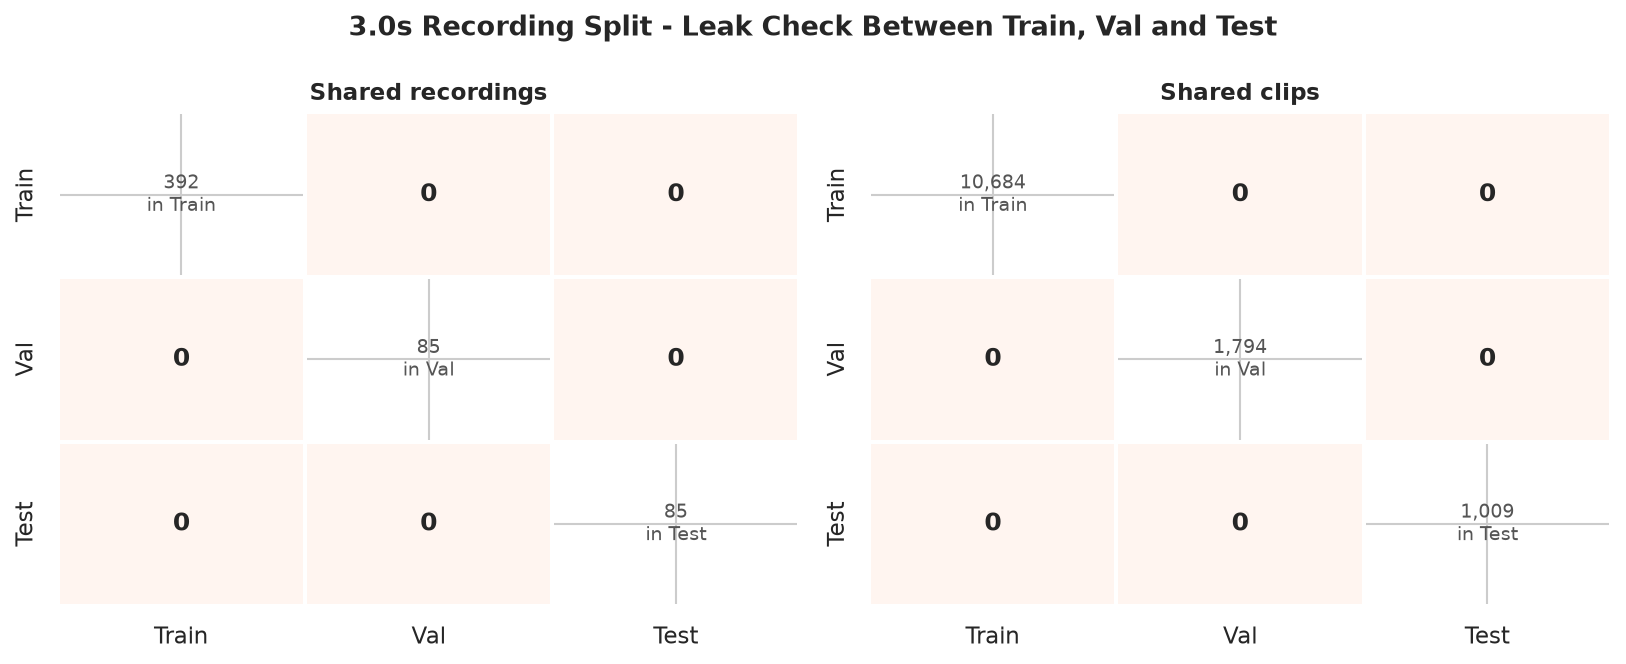


 Partition Distribution Summary: 3.0s Recording Split
Split Total Samples Eagle Calls (1) Non-Eagle (0) Original Field Audio Offline Augmented Unique Audio Sources
Train        10,684   4,806 (45.0%) 5,878 (55.0%)        8,281 (77.5%)     2,403 (22.5%)                  392
  Val         1,794     484 (27.0%) 1,310 (73.0%)       1,794 (100.0%)          0 (0.0%)                   85
 Test         1,009     450 (44.6%)   559 (55.4%)       1,009 (100.0%)          0 (0.0%)                   85

Saved partition distribution figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/outputs/3-seconds/splits/recording-split-distribution.png


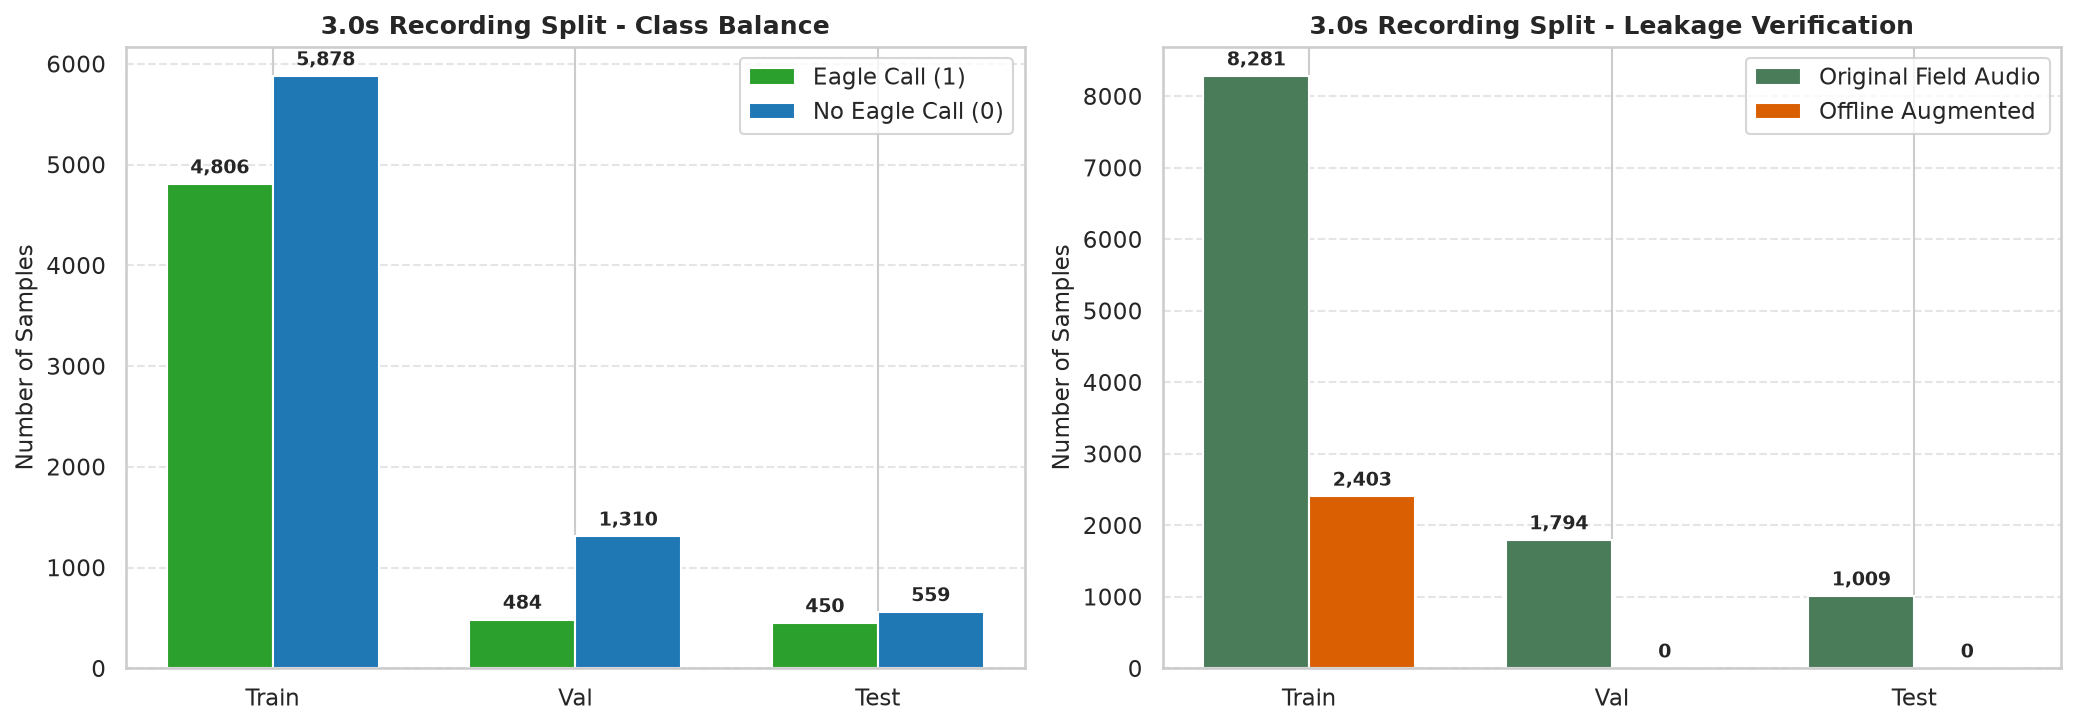

,Split,Total Samples,Eagle Calls (1),Non-Eagle (0),Original Field Audio,Offline Augmented,Unique Audio Sources
0,Train,"10,684","4,806 (45.0%)","5,878 (55.0%)","8,281 (77.5%)","2,403 (22.5%)",392
1,Val,"1,794",484 (27.0%),"1,310 (73.0%)","1,794 (100.0%)",0 (0.0%),85
2,Test,"1,009",450 (44.6%),559 (55.4%),"1,009 (100.0%)",0 (0.0%),85


In [4]:
# Partition dataset into Train, Val, and Test by recording (3.0s Recording Split)
train_idx_3s_std, val_idx_3s_std, test_idx_3s_std, df_recordings_3s = create_recording_split(
    df_clean_3s, train_ratio=0.70, val_ratio=0.15, random_state=SEED
)

# Stop here if anything leaks between the subsets
rec_overlap_3s_std, clip_overlap_3s_std = assert_no_leakage(df_clean_3s, train_idx_3s_std, val_idx_3s_std, test_idx_3s_std)
print("Leak check passed: no recording and no clip appears in more than one subset,")
print("and augmented clips are only in Train, from Train recordings.\n")

print("Recordings shared between subsets (diagonal = recordings in the subset):")
display(rec_overlap_3s_std)
print("Clips shared between subsets (diagonal = clips in the subset):")
display(clip_overlap_3s_std)
print("Recordings per stratum and subset:")
display(pd.crosstab(df_recordings_3s["stratum"], df_recordings_3s["split"])[["train", "val", "test"]])

# Overlap between subsets: every off-diagonal cell should be zero
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
diagonal = np.eye(3, dtype=bool)
for ax, matrix, title in [(axes[0], rec_overlap_3s_std, "Shared recordings"), (axes[1], clip_overlap_3s_std, "Shared clips")]:
    vmax = max(1, int(matrix.values[~diagonal].max()))
    sns.heatmap(matrix, mask=diagonal, annot=True, fmt="d", cmap="Reds", vmin=0, vmax=vmax, cbar=False,
                linewidths=1, linecolor="white", annot_kws={"fontsize": 12, "fontweight": "bold"}, ax=ax)
    for k, name in enumerate(matrix.index):
        ax.text(k + 0.5, k + 0.5, f"{matrix.iloc[k, k]:,}\nin {name}", ha="center", va="center", fontsize=9, color="#555555")
    ax.set_title(title, fontsize=11, fontweight="bold")
plt.suptitle("3.0s Recording Split - Leak Check Between Train, Val and Test", fontsize=13, fontweight="bold")
plt.tight_layout()
leak_fig_path_3s_std = SPLITS_DIR / "recording-split-leakage-check.png"
fig.savefig(leak_fig_path_3s_std, dpi=300, bbox_inches="tight")
print(f"Saved leak check figure to: {leak_fig_path_3s_std}")
plt.show()

X_train_3s_std = X_all_3s[train_idx_3s_std]
y_train_3s_std = y_all_3s[train_idx_3s_std]

X_val_3s_std = X_all_3s[val_idx_3s_std]
y_val_3s_std = y_all_3s[val_idx_3s_std]

X_test_3s_std = X_all_3s[test_idx_3s_std]
y_test_3s_std = y_all_3s[test_idx_3s_std]

# Display distribution table and save visualization
dist_fig_path_3s_std = SPLITS_DIR / "recording-split-distribution.png"
report_and_plot_split_distribution(
    df_clean_3s,
    train_idx_3s_std,
    val_idx_3s_std,
    test_idx_3s_std,
    experiment_name="3.0s Recording Split",
    save_path=dist_fig_path_3s_std
)


### 4.2. Partition Dataset and Visualize Distribution (3.0s Leave-One-Site-Out (LOSO) - Davao del Sur)



 Partition Distribution Summary: 3.0s Leave-One-Site-Out (LOSO) - Davao del Sur
Split Total Samples Eagle Calls (1) Non-Eagle (0) Original Field Audio Offline Augmented Unique Audio Sources
Train         6,627   2,798 (42.2%) 3,829 (57.8%)        5,228 (78.9%)     1,399 (21.1%)                  459
  Val           892     246 (27.6%)   646 (72.4%)         892 (100.0%)          0 (0.0%)                   81
 Test         4,964   1,692 (34.1%) 3,272 (65.9%)       4,964 (100.0%)          0 (0.0%)                   22

Saved partition distribution figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/outputs/3-seconds/splits/loso-davao-distribution.png


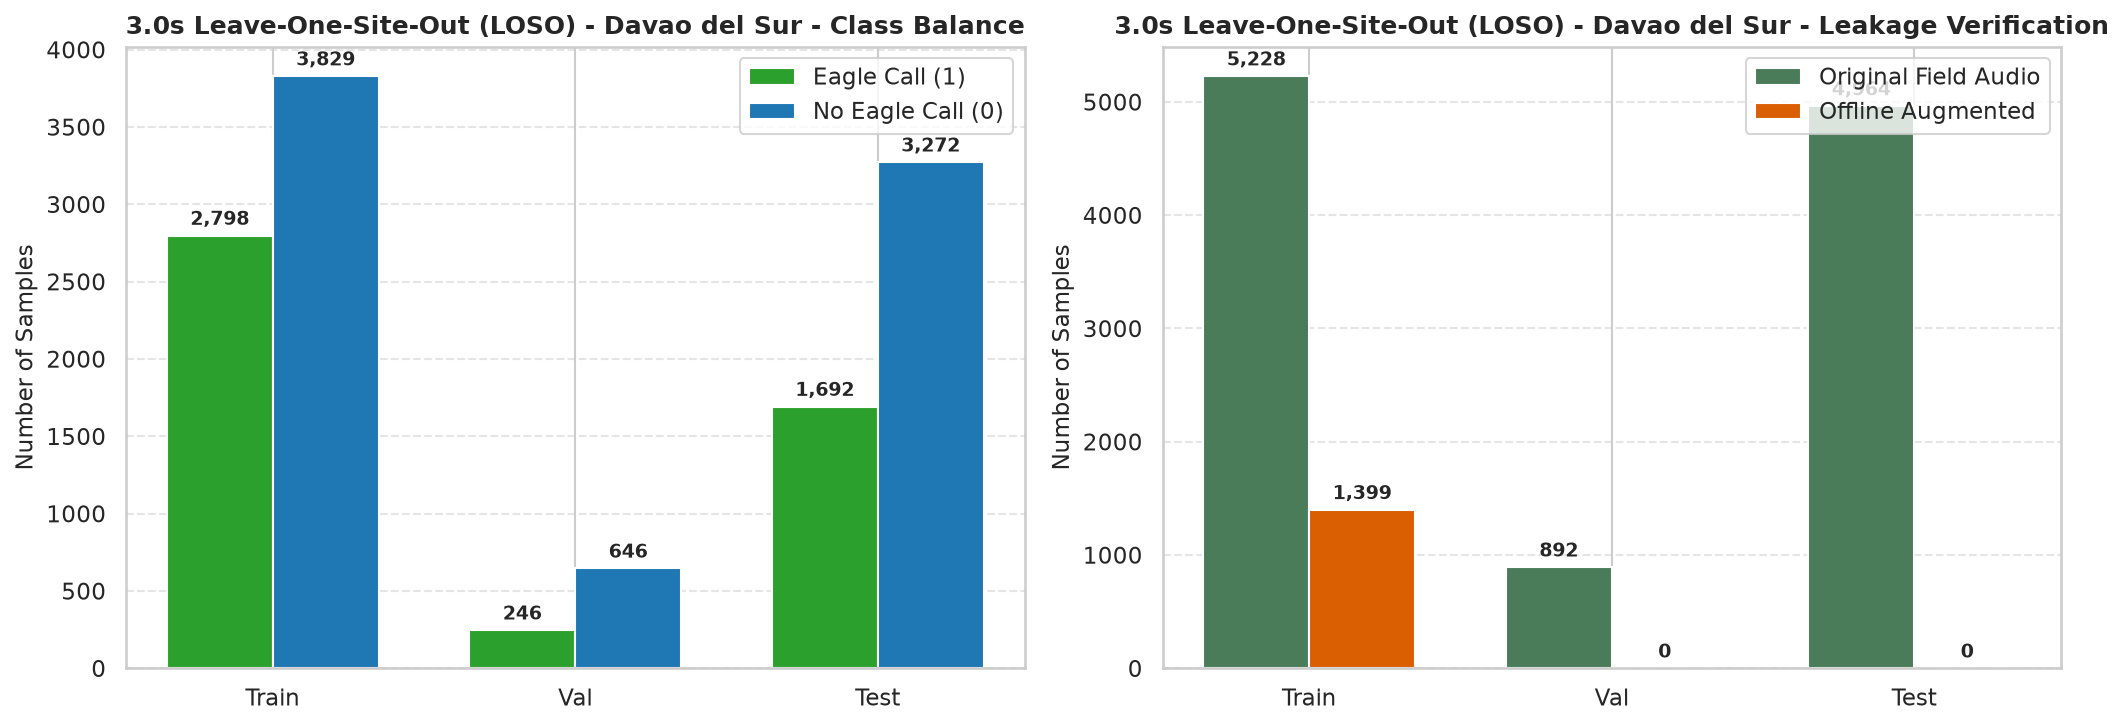

,Split,Total Samples,Eagle Calls (1),Non-Eagle (0),Original Field Audio,Offline Augmented,Unique Audio Sources
0,Train,"6,627","2,798 (42.2%)","3,829 (57.8%)","5,228 (78.9%)","1,399 (21.1%)",459
1,Val,892,246 (27.6%),646 (72.4%),892 (100.0%),0 (0.0%),81
2,Test,"4,964","1,692 (34.1%)","3,272 (65.9%)","4,964 (100.0%)",0 (0.0%),22


In [5]:
# Partition dataset into Train, Val, and Test for 3.0s Leave-One-Site-Out (LOSO) - Davao del Sur
train_idx_3s_loso_davao, val_idx_3s_loso_davao, test_idx_3s_loso_davao = create_loso_split(df_clean_3s, holdout_site='Davao del Sur', val_ratio=0.15, random_state=SEED)

X_train_3s_loso_davao = X_all_3s[train_idx_3s_loso_davao]
y_train_3s_loso_davao = y_all_3s[train_idx_3s_loso_davao]

X_val_3s_loso_davao = X_all_3s[val_idx_3s_loso_davao]
y_val_3s_loso_davao = y_all_3s[val_idx_3s_loso_davao]

X_test_3s_loso_davao = X_all_3s[test_idx_3s_loso_davao]
y_test_3s_loso_davao = y_all_3s[test_idx_3s_loso_davao]

# Display distribution table and save visualization
dist_fig_path_3s_loso_davao = SPLITS_DIR / "loso-davao-distribution.png"
report_and_plot_split_distribution(
    df_clean_3s,
    train_idx_3s_loso_davao,
    val_idx_3s_loso_davao,
    test_idx_3s_loso_davao,
    experiment_name="3.0s Leave-One-Site-Out (LOSO) - Davao del Sur",
    save_path=dist_fig_path_3s_loso_davao
)


### 4.3. Partition Dataset and Visualize Distribution (3.0s Leave-One-Site-Out (LOSO) - Cotabato)



 Partition Distribution Summary: 3.0s Leave-One-Site-Out (LOSO) - Cotabato
Split Total Samples Eagle Calls (1) Non-Eagle (0) Original Field Audio Offline Augmented Unique Audio Sources
Train         7,703   3,024 (39.3%) 4,679 (60.7%)        6,191 (80.4%)     1,512 (19.6%)                  450
  Val         1,491     344 (23.1%) 1,147 (76.9%)       1,491 (100.0%)          0 (0.0%)                   80
 Test         3,402   1,481 (43.5%) 1,921 (56.5%)       3,402 (100.0%)          0 (0.0%)                   32

Saved partition distribution figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/outputs/3-seconds/splits/loso-cotabato-distribution.png


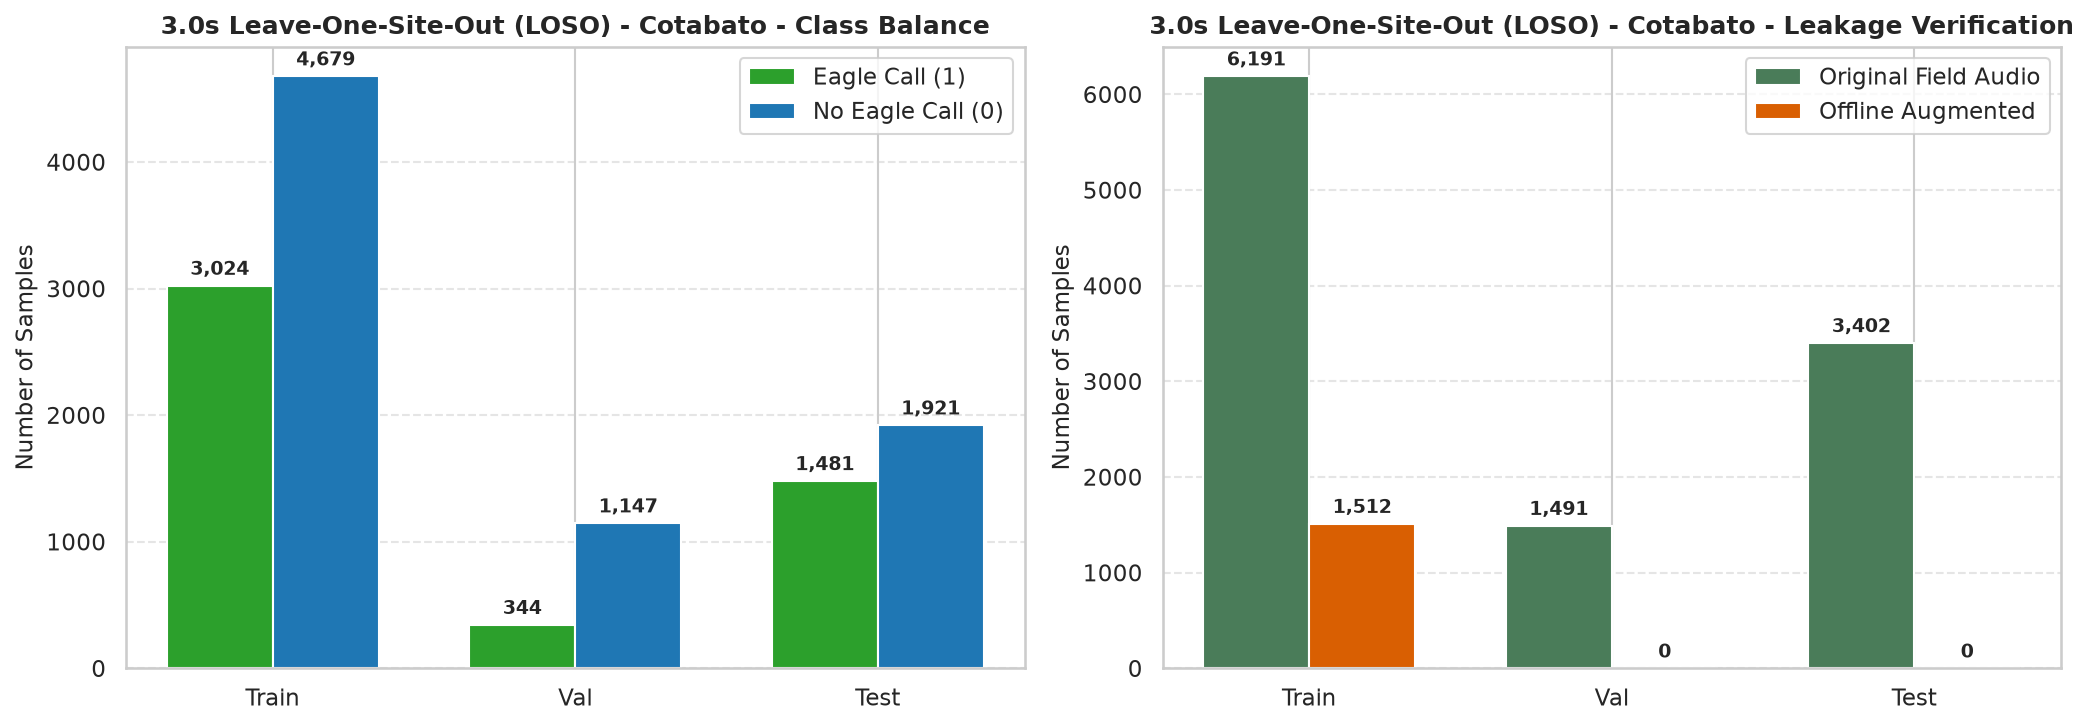

,Split,Total Samples,Eagle Calls (1),Non-Eagle (0),Original Field Audio,Offline Augmented,Unique Audio Sources
0,Train,"7,703","3,024 (39.3%)","4,679 (60.7%)","6,191 (80.4%)","1,512 (19.6%)",450
1,Val,"1,491",344 (23.1%),"1,147 (76.9%)","1,491 (100.0%)",0 (0.0%),80
2,Test,"3,402","1,481 (43.5%)","1,921 (56.5%)","3,402 (100.0%)",0 (0.0%),32


In [6]:
# Partition dataset into Train, Val, and Test for 3.0s Leave-One-Site-Out (LOSO) - Cotabato
train_idx_3s_loso_cotabato, val_idx_3s_loso_cotabato, test_idx_3s_loso_cotabato = create_loso_split(df_clean_3s, holdout_site='Cotabato', val_ratio=0.15, random_state=SEED)

X_train_3s_loso_cotabato = X_all_3s[train_idx_3s_loso_cotabato]
y_train_3s_loso_cotabato = y_all_3s[train_idx_3s_loso_cotabato]

X_val_3s_loso_cotabato = X_all_3s[val_idx_3s_loso_cotabato]
y_val_3s_loso_cotabato = y_all_3s[val_idx_3s_loso_cotabato]

X_test_3s_loso_cotabato = X_all_3s[test_idx_3s_loso_cotabato]
y_test_3s_loso_cotabato = y_all_3s[test_idx_3s_loso_cotabato]

# Display distribution table and save visualization
dist_fig_path_3s_loso_cotabato = SPLITS_DIR / "loso-cotabato-distribution.png"
report_and_plot_split_distribution(
    df_clean_3s,
    train_idx_3s_loso_cotabato,
    val_idx_3s_loso_cotabato,
    test_idx_3s_loso_cotabato,
    experiment_name="3.0s Leave-One-Site-Out (LOSO) - Cotabato",
    save_path=dist_fig_path_3s_loso_cotabato
)


### 4.4. Partition Dataset and Visualize Distribution (3.0s Minor Sites Held Out)



 Partition Distribution Summary: 3.0s Minor Sites Held Out
Split Total Samples Eagle Calls (1) Non-Eagle (0) Original Field Audio Offline Augmented Unique Audio Sources
Train        12,468   5,706 (45.8%) 6,762 (54.2%)        9,615 (77.1%)     2,853 (22.9%)                  451
  Val         1,105     320 (29.0%)   785 (71.0%)       1,105 (100.0%)          0 (0.0%)                   80
 Test           364     164 (45.1%)   200 (54.9%)         364 (100.0%)          0 (0.0%)                   31

Saved partition distribution figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/outputs/3-seconds/splits/minor-sites-distribution.png


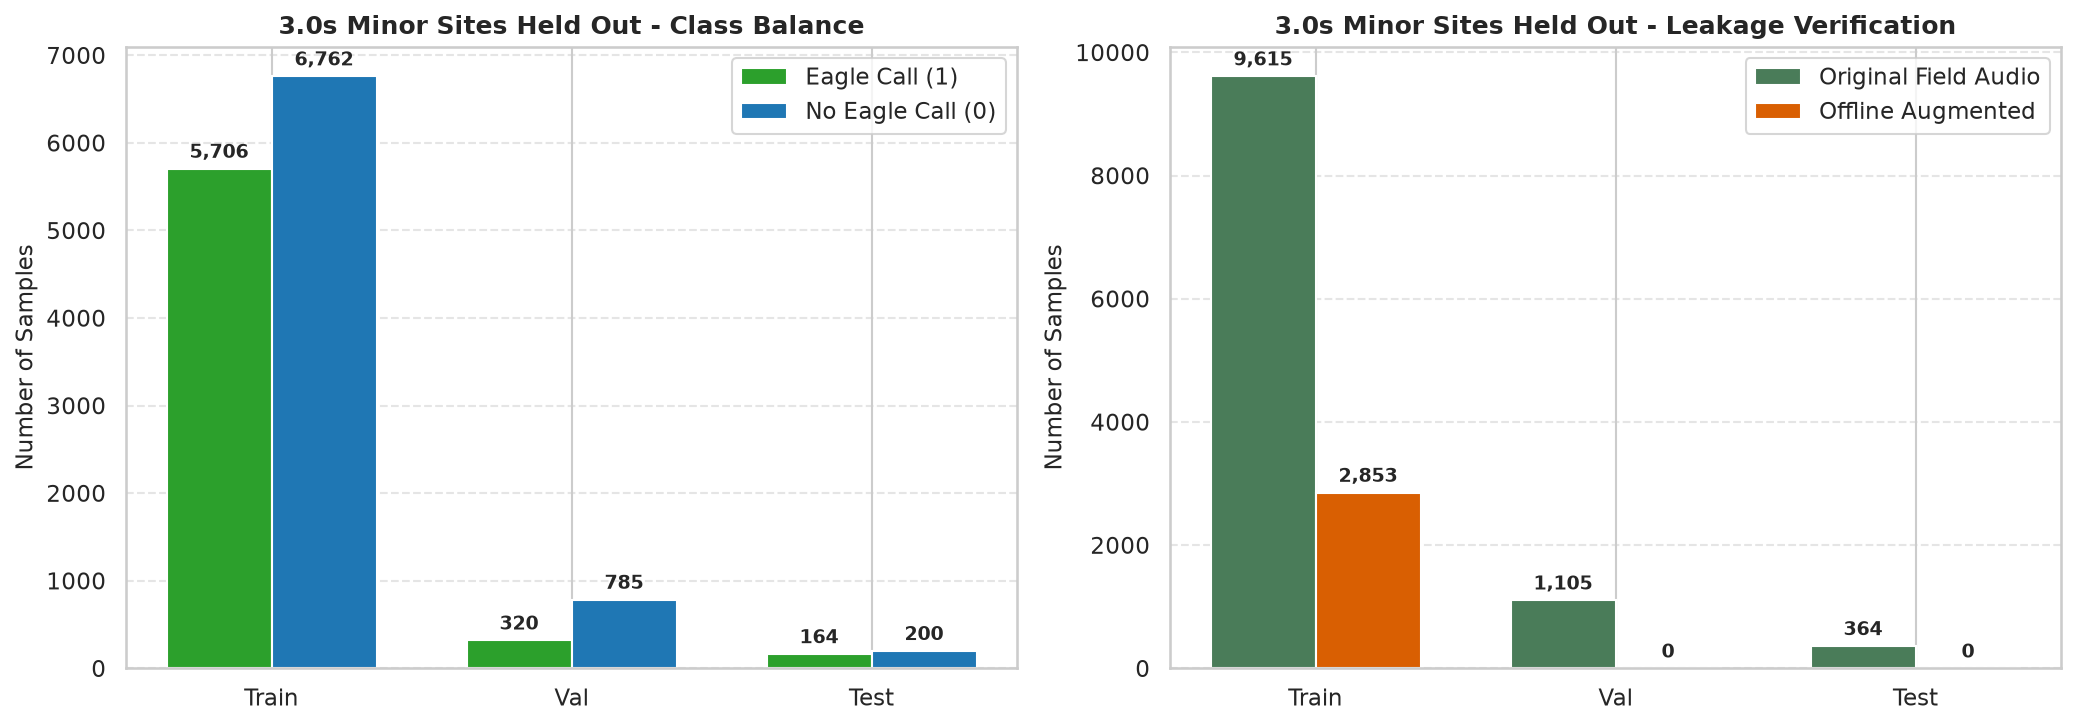

,Split,Total Samples,Eagle Calls (1),Non-Eagle (0),Original Field Audio,Offline Augmented,Unique Audio Sources
0,Train,"12,468","5,706 (45.8%)","6,762 (54.2%)","9,615 (77.1%)","2,853 (22.9%)",451
1,Val,"1,105",320 (29.0%),785 (71.0%),"1,105 (100.0%)",0 (0.0%),80
2,Test,364,164 (45.1%),200 (54.9%),364 (100.0%),0 (0.0%),31


In [7]:
# Partition dataset into Train, Val, and Test for 3.0s Minor Sites Held Out
MINOR_SITES = ["Bukidnon", "Davao Oriental", "Agusan del Sur", "Misamis Oriental"]
train_idx_3s_loso_minor, val_idx_3s_loso_minor, test_idx_3s_loso_minor = create_loso_split(df_clean_3s, holdout_site=MINOR_SITES, val_ratio=0.15, random_state=SEED)

X_train_3s_loso_minor = X_all_3s[train_idx_3s_loso_minor]
y_train_3s_loso_minor = y_all_3s[train_idx_3s_loso_minor]

X_val_3s_loso_minor = X_all_3s[val_idx_3s_loso_minor]
y_val_3s_loso_minor = y_all_3s[val_idx_3s_loso_minor]

X_test_3s_loso_minor = X_all_3s[test_idx_3s_loso_minor]
y_test_3s_loso_minor = y_all_3s[test_idx_3s_loso_minor]

# Display distribution table and save visualization
dist_fig_path_3s_loso_minor = SPLITS_DIR / "minor-sites-distribution.png"
report_and_plot_split_distribution(
    df_clean_3s,
    train_idx_3s_loso_minor,
    val_idx_3s_loso_minor,
    test_idx_3s_loso_minor,
    experiment_name="3.0s Minor Sites Held Out",
    save_path=dist_fig_path_3s_loso_minor
)


## 5. Model Experiments in Ablation Order (3.0s, 128 x 130)

Eight models, each trained on all four partitions, in the order of the ablation. Every step changes one thing from the step before it:

| Step | Section | Model | What changes |
|---|---|---|---|
| 0 | 5.2 | Published baseline | CRNN-GRU of Carvalho and Gomes (2023), log-Mel input, binary cross-entropy, no augmentation, default Adam |
| 1 | 5.3 | Compact CRNN-GRU | The smaller architecture of this study |
| 2 | 5.4 | + PCEN | PCEN replaces log-Mel |
| 3 | 5.5 | + Augmentation | Pitch-shifted copies, gain scaling, SpecAugment |
| 4 | 5.6 | + Training stabilization | Warmup and cosine decay, gradient clipping, averaged weights (EMA) |
| 5 | 5.7 | + Focal loss | Model A |
| 6 | 5.8 | + Cost-sensitive weights | Model B |
| 7 | 5.9 | Edge-optimized | Model C |

All steps use the same windows, labels, partitions, seed, early stopping rule and decision threshold. To retrain a model, delete its folder under `models/3-seconds/`.


### 5.1. Setup for the Baseline and the Ablation Steps


#### 5.1.1 Load Log-Mel Features (3.0s)


In [8]:
# Load the log-Mel version of the same 3.0s windows (same rows and order as the PCEN arrays)
X_all_3s_logmel = np.full((num_samples_3s, 128, 130, 1), -80.0, dtype=np.float32)
for i, row in enumerate(tqdm(df_clean_3s.itertuples(), total=num_samples_3s, desc="Loading 3s log-Mel features")):
    arr = np.load(FEATURES_3S_LOGMEL_DIR / row.feature_file)
    t_frames = min(arr.shape[1], 130)
    X_all_3s_logmel[i, :, :t_frames, 0] = arr[:, :t_frames]

# The saved values are decibels from -80 to 0. Rescale them to 0-1 with fixed constants (nothing is fitted to the data)
X_all_3s_logmel = (X_all_3s_logmel + 80.0) / 80.0

print(f"3.0s log-Mel tensor shape: {X_all_3s_logmel.shape} ({X_all_3s_logmel.nbytes / (1024**2):.1f} MB in RAM)")
print(f"Value range after rescaling: {X_all_3s_logmel.min():.3f} to {X_all_3s_logmel.max():.3f}")

Loading 3s log-Mel features:   0%|          | 0/14421 [00:00<?, ?it/s]

3.0s log-Mel tensor shape: (14421, 128, 130, 1) (915.4 MB in RAM)
Value range after rescaling: 0.000 to 1.000


#### 5.1.2 Define the Published Baseline Model, the Ablation Steps, and the Training Helper


In [9]:
def build_published_crnn_gru_model(input_shape):
    """
    CRNN-GRU of Carvalho and Gomes (2023), with one sigmoid output in place of their 91-class softmax:
    - 4 Conv2D layers (32, 64, 128, 256 filters, ReLU), each followed by 2x2 max pooling
    - Dropout 0.5, then the feature map is read as a sequence over time
    - 2 bidirectional GRU layers (512 and 256 units), each followed by 1D max pooling
    - Dropout 0.5, Dense 64 (ReLU), sigmoid output
    The paper does not give the kernel size of these convolutions, so 3x3 is used.
    """
    inputs = tf.keras.Input(shape=input_shape, name="audio_input")
    x = inputs
    for i, filters in enumerate([32, 64, 128, 256], start=1):
        x = tf.keras.layers.Conv2D(filters, (3, 3), padding="same", activation="relu", name=f"conv{i}")(x)
        x = tf.keras.layers.MaxPooling2D((2, 2), name=f"pool{i}")(x)
    x = tf.keras.layers.Dropout(0.5, name="conv_dropout")(x)

    # Four 2x2 poolings leave 130 // 16 = 8 time steps
    x = tf.keras.layers.Permute((2, 1, 3), name="permute_time_first")(x)
    x = tf.keras.layers.Reshape((input_shape[1] // 16, -1), name="time_flatten")(x)

    x = tf.keras.layers.Bidirectional(tf.keras.layers.GRU(512, return_sequences=True), name="bigru1")(x)
    x = tf.keras.layers.MaxPooling1D(2, name="seq_pool1")(x)
    x = tf.keras.layers.Dropout(0.5, name="gru_dropout")(x)
    x = tf.keras.layers.Bidirectional(tf.keras.layers.GRU(256, return_sequences=True), name="bigru2")(x)
    x = tf.keras.layers.MaxPooling1D(2, name="seq_pool2")(x)

    x = tf.keras.layers.Flatten(name="flatten")(x)
    x = tf.keras.layers.Dropout(0.5, name="dense_dropout")(x)
    x = tf.keras.layers.Dense(64, activation="relu", name="dense1")(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="eagle_prob")(x)
    return tf.keras.Model(inputs=inputs, outputs=outputs, name="Published_CRNN_GRU")


# Each step changes one thing from the step before it
ABLATION_MODELS = {
    "published-baseline":     {"title": "Published Baseline",           "architecture": "published", "features": "log-mel", "augment": False, "stabilized": False},
    "compact":                {"title": "Compact CRNN-GRU",             "architecture": "compact",   "features": "log-mel", "augment": False, "stabilized": False},
    "compact-pcen":           {"title": "Compact + PCEN",               "architecture": "compact",   "features": "pcen",    "augment": False, "stabilized": False},
    "compact-pcen-augmented": {"title": "Compact + PCEN + Augmentation", "architecture": "compact",   "features": "pcen",    "augment": True,  "stabilized": False},
    "compact-stabilized":     {"title": "Compact + Stabilization",      "architecture": "compact",   "features": "pcen",    "augment": True,  "stabilized": True},
}

# The same four partitions as the other experiments in this notebook
ABLATION_PARTITIONS = {
    "recording-split": ("Recording Split", train_idx_3s_std, val_idx_3s_std, test_idx_3s_std),
    "loso-davao":      ("LOSO - Davao del Sur", train_idx_3s_loso_davao, val_idx_3s_loso_davao, test_idx_3s_loso_davao),
    "loso-cotabato":   ("LOSO - Cotabato", train_idx_3s_loso_cotabato, val_idx_3s_loso_cotabato, test_idx_3s_loso_cotabato),
    "minor-sites":     ("Minor Sites Held Out", train_idx_3s_loso_minor, val_idx_3s_loso_minor, test_idx_3s_loso_minor),
}

ablation_metrics = {}


def run_ablation_experiment(model_key, partition_key):
    """Train (or load) one ablation model on one partition, then plot its history and evaluate it on the test subset."""
    cfg = ABLATION_MODELS[model_key]
    partition_title, train_idx, val_idx, test_idx = ABLATION_PARTITIONS[partition_key]
    title = f"{cfg['title']} 3.0s {partition_title}"

    X_source = X_all_3s_logmel if cfg["features"] == "log-mel" else X_all_3s
    if not cfg["augment"]:
        # Without augmentation the pitch-shifted copies are left out of training
        train_idx = train_idx[~is_aug_all_3s[train_idx]]
    X_train, y_train = X_source[train_idx], y_all_3s[train_idx]
    X_val, y_val = X_source[val_idx], y_all_3s[val_idx]
    X_test, y_test = X_source[test_idx], y_all_3s[test_idx]

    model_dir = MODELS_DIR / "3-seconds" / model_key / partition_key
    (model_dir / "checkpoints").mkdir(parents=True, exist_ok=True)
    model_path = model_dir / f"{model_key}.keras"
    history_path = model_dir / "training_history.json"

    # Clear previous Keras session and reclaim GPU VRAM
    tf.keras.backend.clear_session()
    gc.collect()

    if model_path.exists():
        print(f"Model already exists at: {model_path}")
        print("Loading cached model...")
        model = tf.keras.models.load_model(model_path)
        with open(history_path, "r") as f:
            history = json.load(f)
    else:
        print(f"Training {title} on {len(train_idx):,} windows ({int(y_train.sum()):,} eagle)...")
        tf.keras.utils.set_random_seed(SEED)
        if cfg["architecture"] == "published":
            model = build_published_crnn_gru_model(SHAPE_3S)
        else:
            model = build_crnn_gru_model(input_shape=SHAPE_3S)

        early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1)
        checkpoint = tf.keras.callbacks.ModelCheckpoint(str(model_dir / "checkpoints" / "best_model.keras"), monitor="val_loss", save_best_only=True)
        if cfg["stabilized"]:
            # Same training setup as the standard model: warmup + cosine decay, gradient clipping, averaged weights
            optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=0.5, use_ema=True, ema_momentum=0.99)
            callbacks = [
                tf.keras.callbacks.SwapEMAWeights(swap_on_epoch=True),
                early_stopping,
                make_warmup_cosine_callback(target_lr=5e-4, start_lr=1e-4, min_lr=1e-5, warmup_epochs=3),
                checkpoint,
            ]
        else:
            # Keras default Adam (learning rate 0.001), nothing tuned
            optimizer = tf.keras.optimizers.Adam()
            callbacks = [early_stopping, checkpoint]

        model.compile(
            optimizer=optimizer,
            loss="binary_crossentropy",
            metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
        )

        if cfg["augment"]:
            # On-the-fly training generator (Gain jitter + SpecAugment time/freq masking)
            train_gen = SpecAugmentDataGenerator(X_train, y_train, batch_size=BATCH_SIZE, is_training=True, shuffle=True, mask_all_classes=True)
            fit_res = model.fit(train_gen, validation_data=(X_val, y_val), epochs=EPOCHS, callbacks=callbacks, verbose=1)
        else:
            fit_res = model.fit(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True, validation_data=(X_val, y_val), epochs=EPOCHS, callbacks=callbacks, verbose=1)

        history = {k: [float(x) for x in vals] for k, vals in fit_res.history.items()}
        model.save(model_path)
        with open(history_path, "w") as f:
            json.dump(history, f)
        print(f"Saved trained model to: {model_path}")

    out_dir = model_output_dir(model_key, partition_key)
    plot_training_history(history, out_dir / "training-history.png", title_prefix=title)

    y_pred_prob = model.predict(X_test, batch_size=BATCH_SIZE).ravel()
    metrics = evaluate_predictions(y_test, y_pred_prob, title, out_dir / "confusion-matrix.png")
    metrics["parameters"] = int(model.count_params())
    metrics["epochs_trained"] = len(history["loss"])
    return metrics

### 5.2. Step 0: Published Baseline

The CRNN-GRU of Carvalho and Gomes (2023), about 10.3 million parameters. Input: log-Mel spectrogram. Loss: binary cross-entropy. No augmentation. Optimizer: Keras default Adam (learning rate 0.001).


#### 5.2.1 Train or Load, Plot History, and Evaluate: Published Baseline (3.0s Recording Split)


Training Published Baseline 3.0s Recording Split on 8,281 windows (2,403 eagle)...


I0000 00:00:1791900807.061312   59966 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4108 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Epoch 1/50


E0000 00:00:1791900810.423581   59966 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/Published_CRNN_GRU_1/conv_dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1791900810.672250   60091 cuda_dnn.cc:461] Loaded cuDNN version 92501


259/259 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - accuracy: 0.8062 - auc: 0.8402 - loss: 0.4251 - precision: 0.7822 - recall: 0.4603 - val_accuracy: 0.8595 - val_auc: 0.9295 - val_loss: 0.3252 - val_precision: 0.9000 - val_recall: 0.5393
Epoch 2/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 11s 43ms/step - accuracy: 0.8972 - auc: 0.9449 - loss: 0.2598 - precision: 0.8428 - recall: 0.7940 - val_accuracy: 0.9030 - val_auc: 0.9418 - val_loss: 0.2617 - val_precision: 0.8460 - val_recall: 0.7831
Epoch 3/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 11s 42ms/step - accuracy: 0.9080 - auc: 0.9555 - loss: 0.2331 - precision: 0.8661 - recall: 0.8077 - val_accuracy: 0.8846 - val_auc: 0.9430 - val_loss: 0.2709 - val_precision: 0.9425 - val_recall: 0.6095
Epoch 4/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 12s 47ms/step - accuracy: 0.9181 - auc: 0.9632 - loss: 0.2127 - precision: 0.8785 - recall: 0.8331 - val_accuracy: 0.9247 - val_auc: 0.9596 - val_loss: 0.2149 - val_precision: 0.9049 - val_recall: 0.8058
Epoch 5/50
259/259 ━━━━━━━━━━━━━━━━

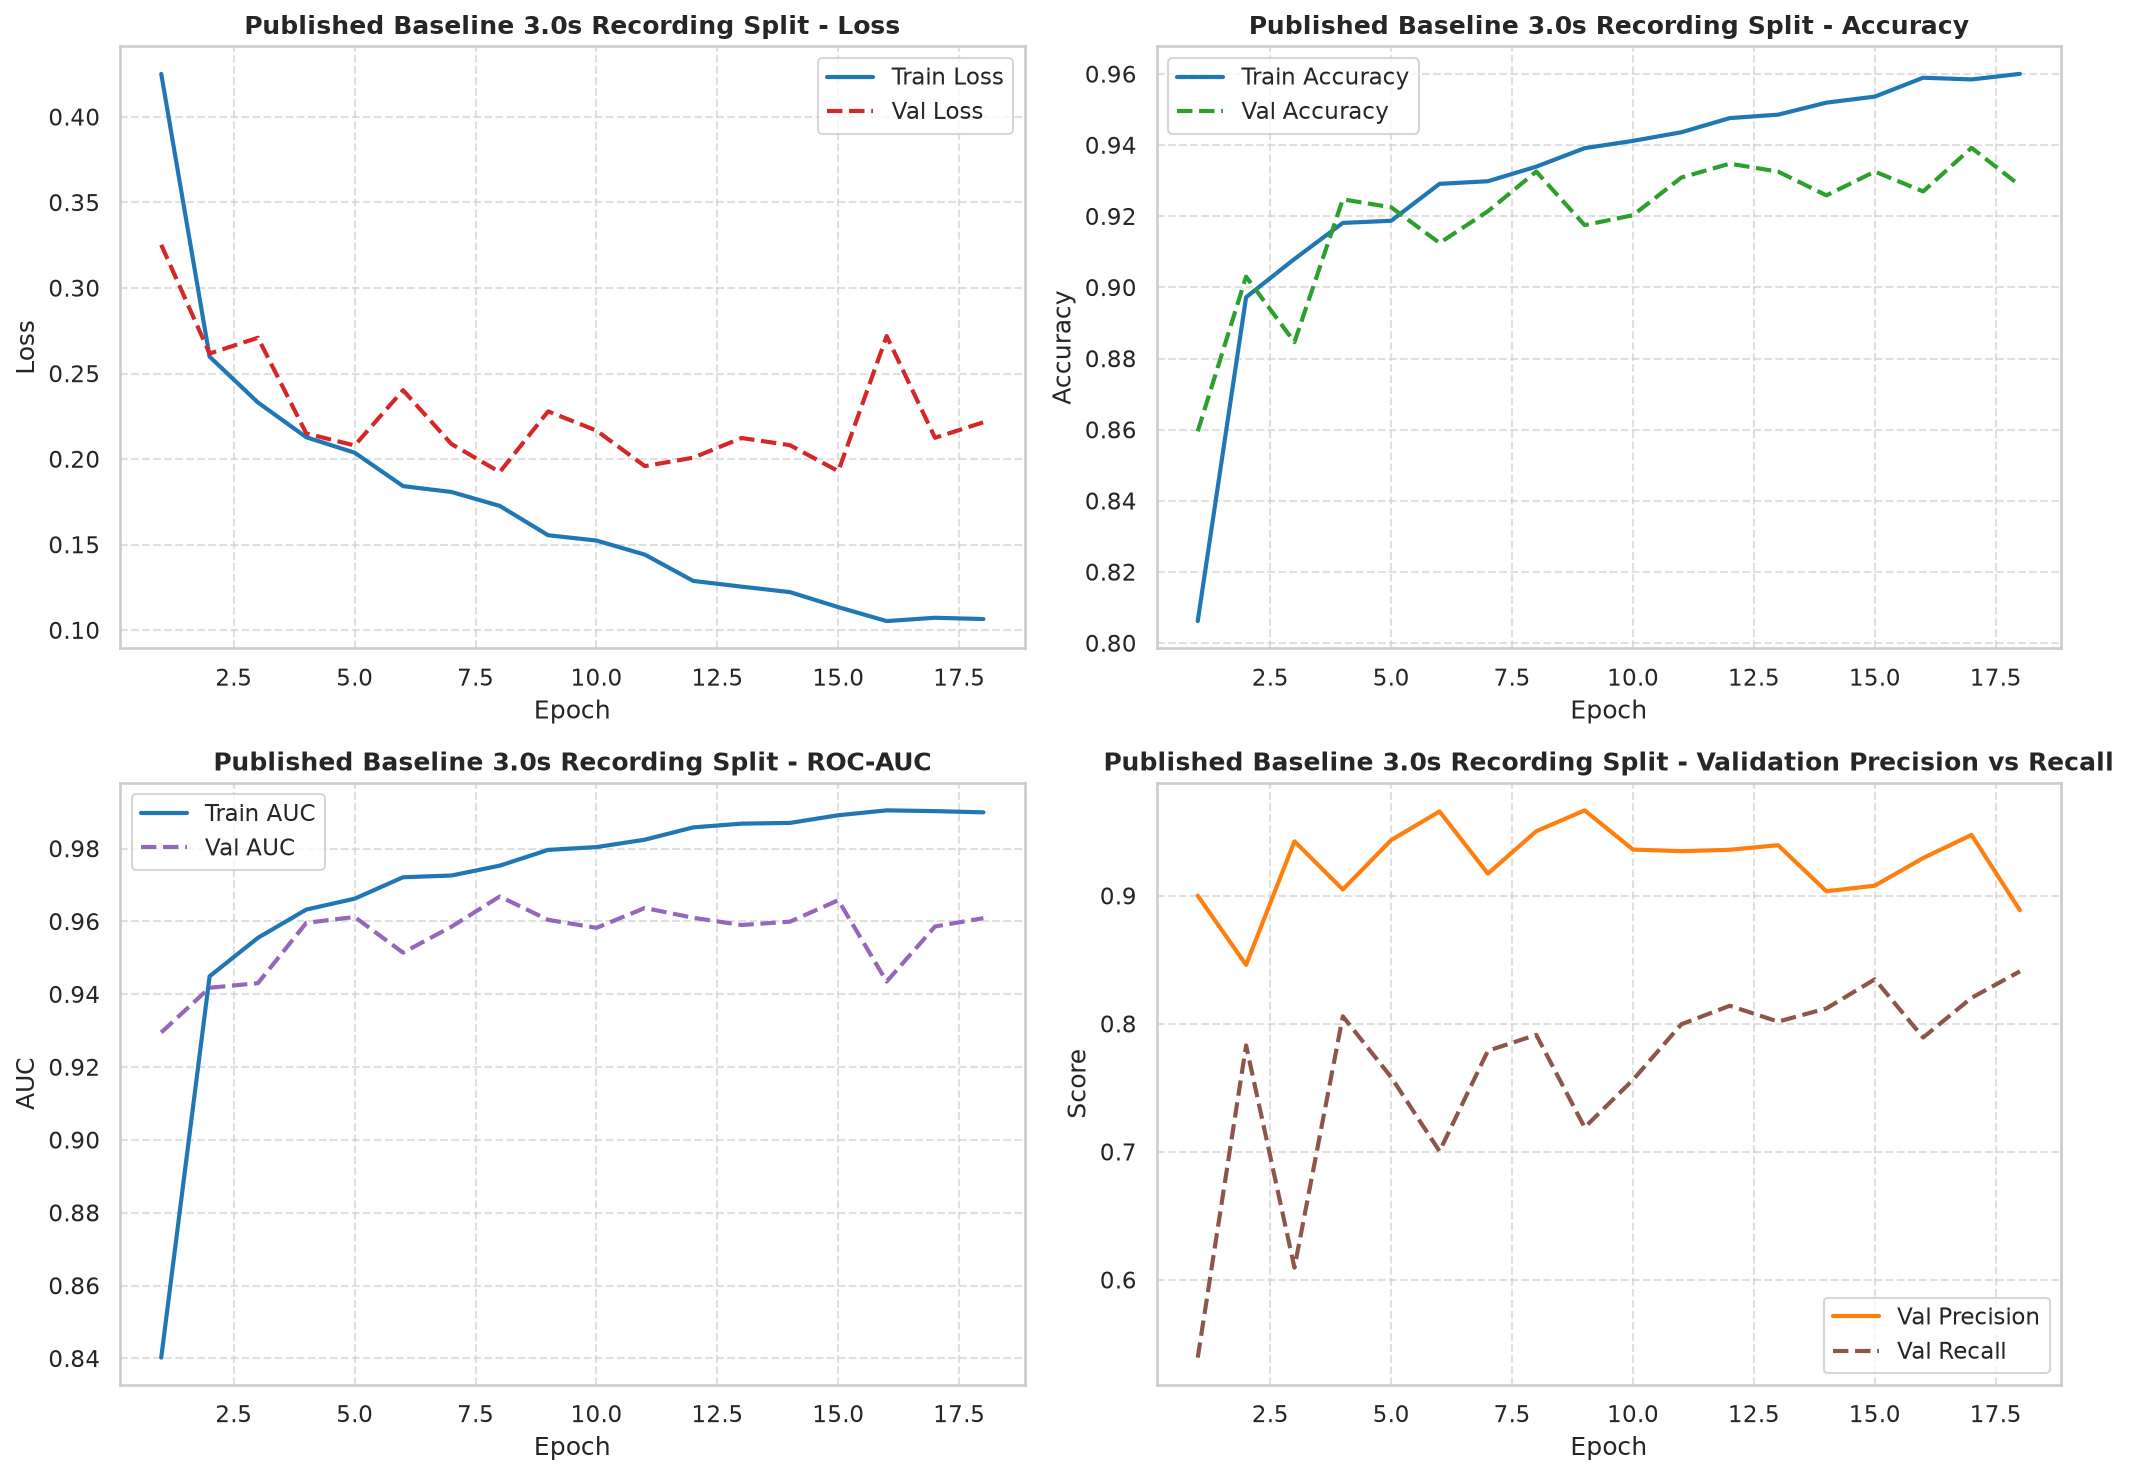

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step
EVALUATION RESULTS: Published Baseline 3.0s Recording Split
Accuracy:    0.9167 (91.67%)
Precision:   0.9463 (94.63%)
Recall:      0.8622 (86.22%)
F1-Score:    0.9023 (90.23%)
Specificity: 0.9606 (96.06%)
ROC-AUC:     0.9748
Confusion:   TN 537 | FP 22 | FN 62 | TP 388
              precision    recall  f1-score   support

No Eagle (0)       0.90      0.96      0.93       559
   Eagle (1)       0.95      0.86      0.90       450

    accuracy                           0.92      1009
   macro avg       0.92      0.91      0.91      1009
weighted avg       0.92      0.92      0.92      1009

Saved statistics to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/outputs/3-seconds/published-baseline/recording-split/statistics.txt
Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/outputs/3-seconds/published-baseline/recording-split/confusio

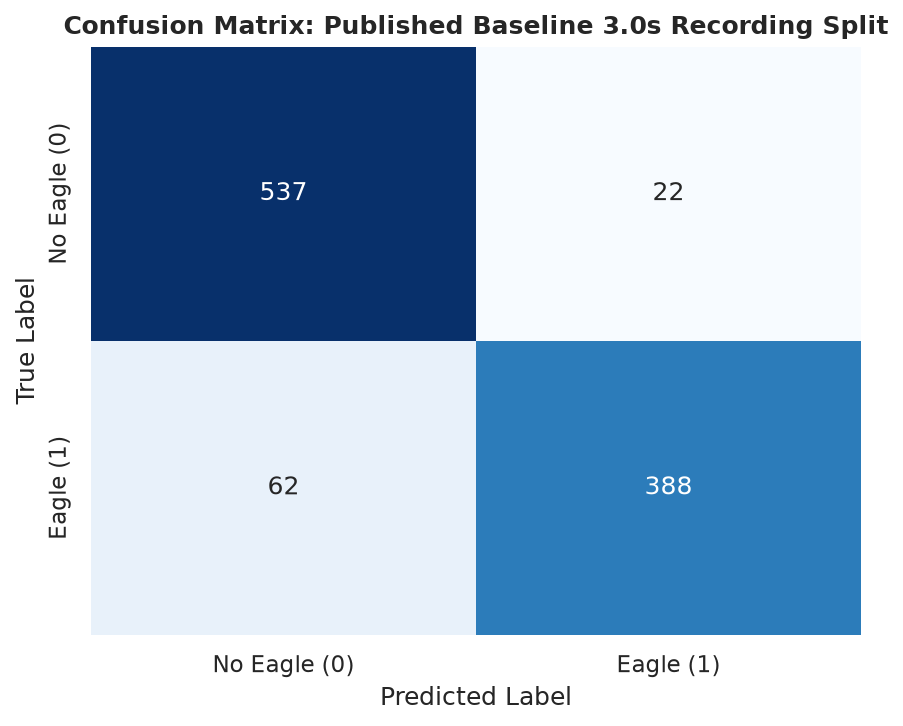

In [10]:
# Published Baseline on the 3.0s Recording Split
ablation_metrics[("published-baseline", "recording-split")] = run_ablation_experiment("published-baseline", "recording-split")

#### 5.2.2 Train or Load, Plot History, and Evaluate: Published Baseline (3.0s LOSO - Davao del Sur)


Training Published Baseline 3.0s LOSO - Davao del Sur on 5,228 windows (1,399 eagle)...
Epoch 1/50


E0000 00:00:1791901020.109907   59966 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/Published_CRNN_GRU_1/conv_dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


164/164 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - accuracy: 0.8294 - auc: 0.8634 - loss: 0.3910 - precision: 0.7795 - recall: 0.5054 - val_accuracy: 0.7859 - val_auc: 0.8758 - val_loss: 0.5068 - val_precision: 0.5762 - val_recall: 0.8455
Epoch 2/50
164/164 ━━━━━━━━━━━━━━━━━━━━ 7s 43ms/step - accuracy: 0.9256 - auc: 0.9635 - loss: 0.2041 - precision: 0.8885 - recall: 0.8256 - val_accuracy: 0.8206 - val_auc: 0.9088 - val_loss: 0.4863 - val_precision: 0.6257 - val_recall: 0.8699
Epoch 3/50
164/164 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - accuracy: 0.9392 - auc: 0.9742 - loss: 0.1677 - precision: 0.9098 - recall: 0.8578 - val_accuracy: 0.8307 - val_auc: 0.9184 - val_loss: 0.4321 - val_precision: 0.6401 - val_recall: 0.8821
Epoch 4/50
164/164 ━━━━━━━━━━━━━━━━━━━━ 7s 42ms/step - accuracy: 0.9474 - auc: 0.9808 - loss: 0.1438 - precision: 0.9245 - recall: 0.8749 - val_accuracy: 0.8374 - val_auc: 0.9223 - val_loss: 0.5211 - val_precision: 0.6517 - val_recall: 0.8821
Epoch 5/50
164/164 ━━━━━━━━━━━━━━━━━━━

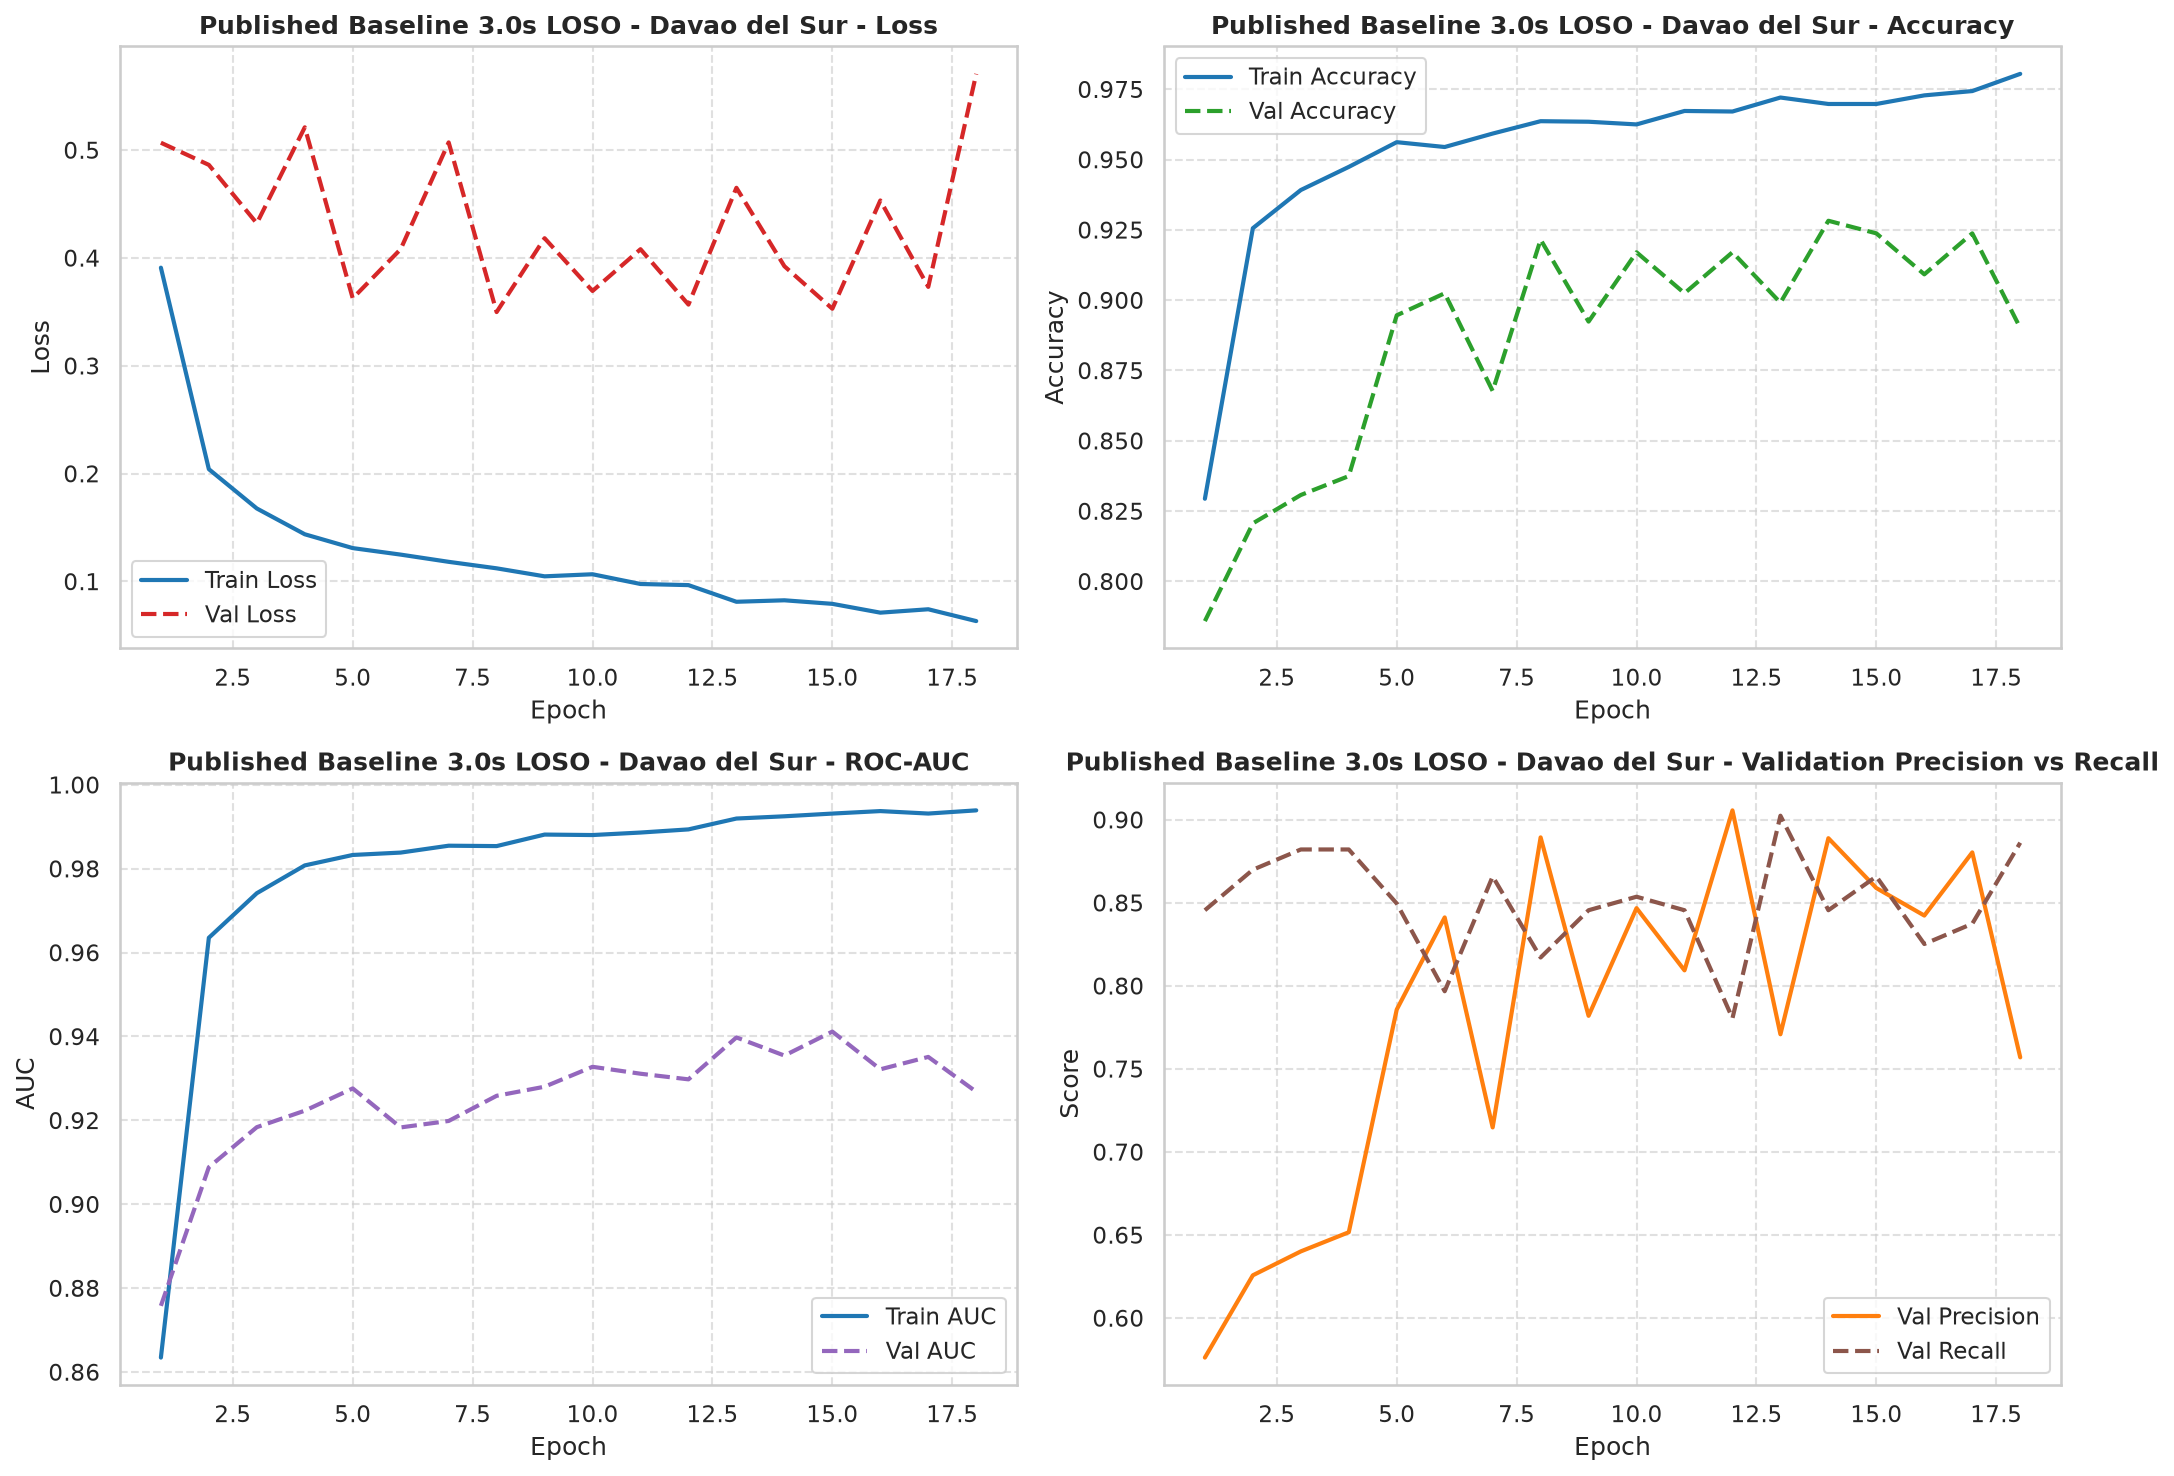

156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step
EVALUATION RESULTS: Published Baseline 3.0s LOSO - Davao del Sur
Accuracy:    0.8378 (83.78%)
Precision:   0.8668 (86.68%)
Recall:      0.6194 (61.94%)
F1-Score:    0.7225 (72.25%)
Specificity: 0.9508 (95.08%)
ROC-AUC:     0.9048
Confusion:   TN 3111 | FP 161 | FN 644 | TP 1048
              precision    recall  f1-score   support

No Eagle (0)       0.83      0.95      0.89      3272
   Eagle (1)       0.87      0.62      0.72      1692

    accuracy                           0.84      4964
   macro avg       0.85      0.79      0.80      4964
weighted avg       0.84      0.84      0.83      4964

Saved statistics to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/outputs/3-seconds/published-baseline/loso-davao/statistics.txt
Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/outputs/3-seconds/published-baseline/loso-davao/confusi

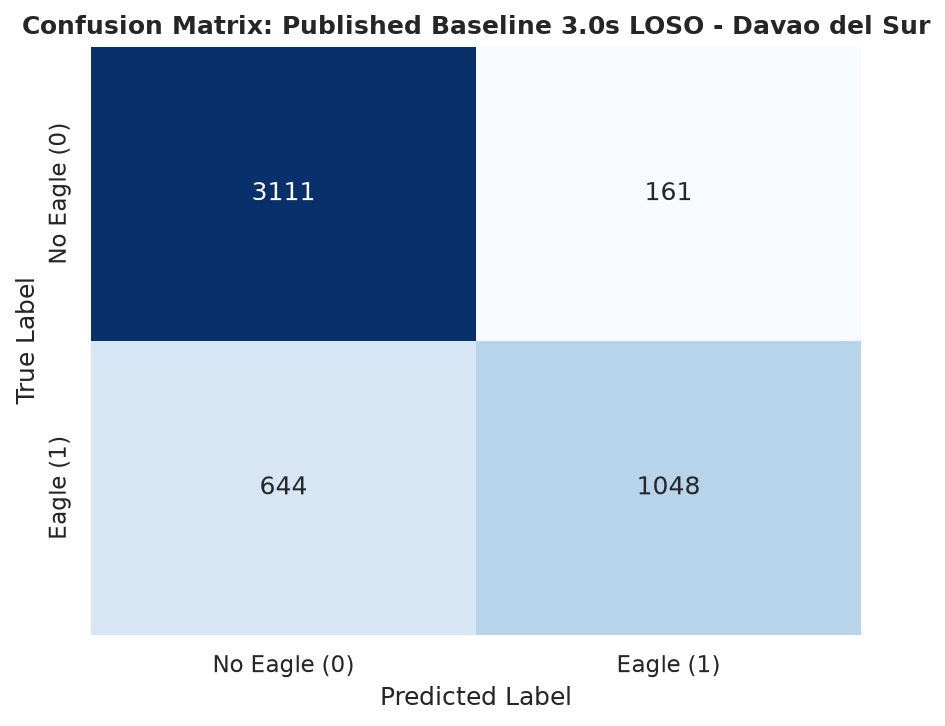

In [11]:
# Published Baseline on the 3.0s LOSO - Davao del Sur
ablation_metrics[("published-baseline", "loso-davao")] = run_ablation_experiment("published-baseline", "loso-davao")

#### 5.2.3 Train or Load, Plot History, and Evaluate: Published Baseline (3.0s LOSO - Cotabato)


Training Published Baseline 3.0s LOSO - Cotabato on 6,191 windows (1,512 eagle)...
Epoch 1/50


E0000 00:00:1791901154.327881   59966 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/Published_CRNN_GRU_1/conv_dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


194/194 ━━━━━━━━━━━━━━━━━━━━ 12s 50ms/step - accuracy: 0.7601 - auc: 0.7536 - loss: 0.4809 - precision: 0.5211 - recall: 0.2209 - val_accuracy: 0.5795 - val_auc: 0.8589 - val_loss: 0.5730 - val_precision: 0.3430 - val_recall: 0.8983
Epoch 2/50
194/194 ━━━━━━━━━━━━━━━━━━━━ 9s 46ms/step - accuracy: 0.8688 - auc: 0.9272 - loss: 0.2876 - precision: 0.7585 - recall: 0.6792 - val_accuracy: 0.9235 - val_auc: 0.9376 - val_loss: 0.2335 - val_precision: 0.8686 - val_recall: 0.7878
Epoch 3/50
194/194 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.9011 - auc: 0.9543 - loss: 0.2280 - precision: 0.8285 - recall: 0.7507 - val_accuracy: 0.9363 - val_auc: 0.9416 - val_loss: 0.2181 - val_precision: 0.9192 - val_recall: 0.7936
Epoch 4/50
194/194 ━━━━━━━━━━━━━━━━━━━━ 9s 46ms/step - accuracy: 0.9150 - auc: 0.9651 - loss: 0.2012 - precision: 0.8472 - recall: 0.7956 - val_accuracy: 0.9323 - val_auc: 0.9566 - val_loss: 0.2016 - val_precision: 0.8907 - val_recall: 0.8052
Epoch 5/50
194/194 ━━━━━━━━━━━━━━━━━━━

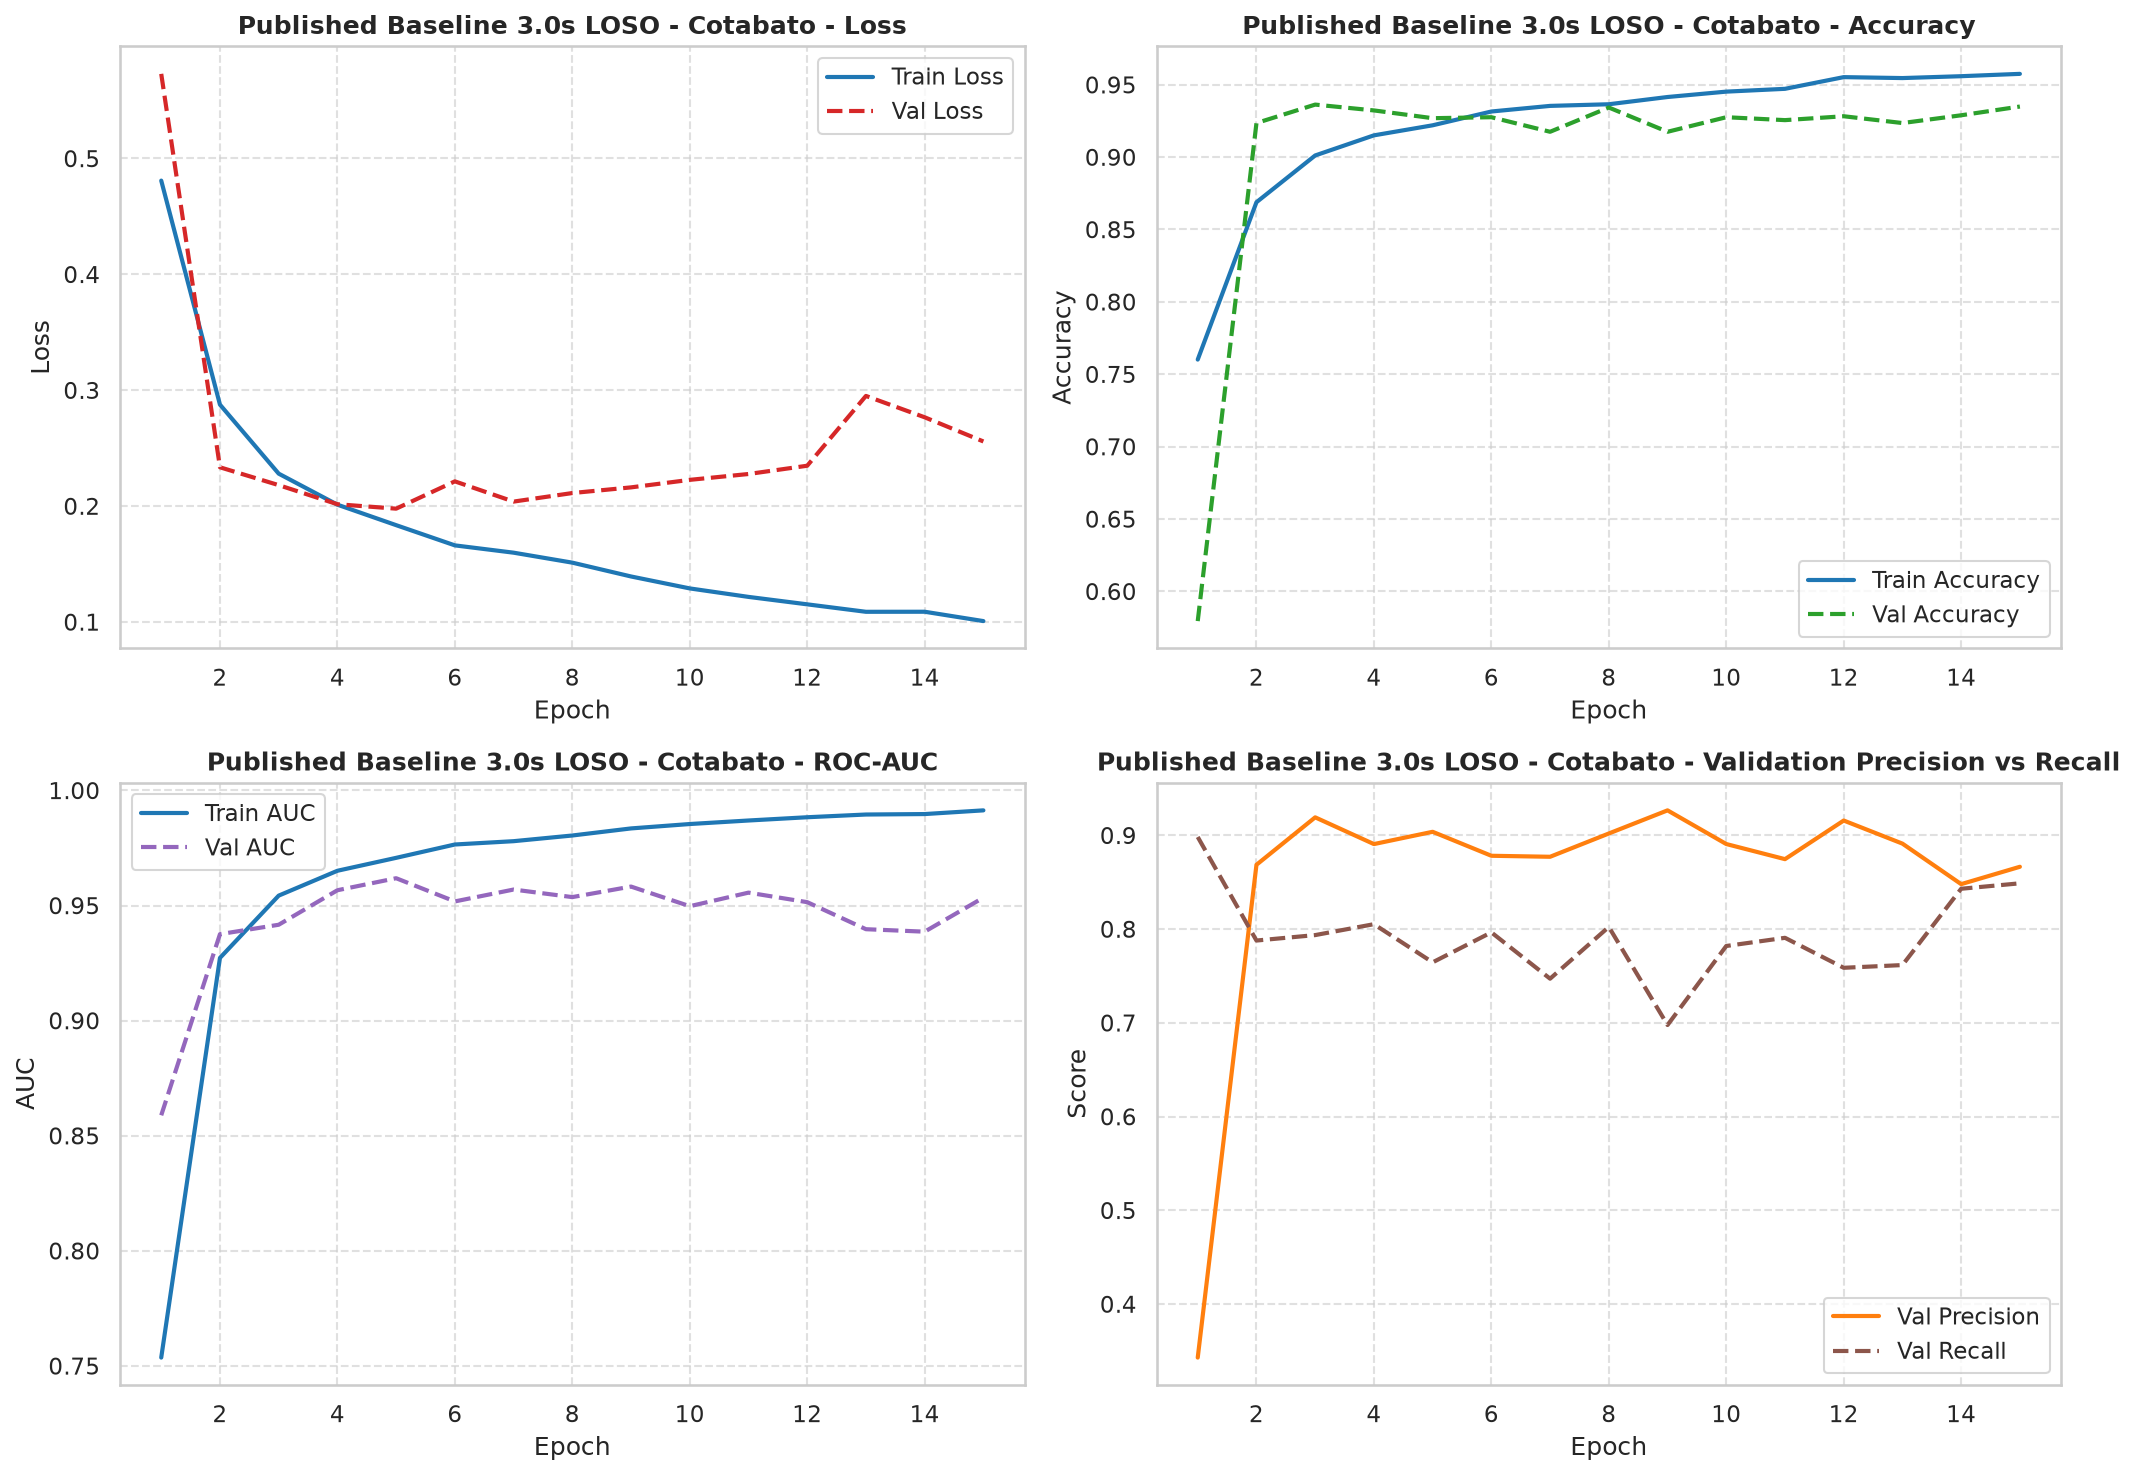

107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
EVALUATION RESULTS: Published Baseline 3.0s LOSO - Cotabato
Accuracy:    0.8636 (86.36%)
Precision:   0.9635 (96.35%)
Recall:      0.7137 (71.37%)
F1-Score:    0.8200 (82.00%)
Specificity: 0.9792 (97.92%)
ROC-AUC:     0.9209
Confusion:   TN 1881 | FP 40 | FN 424 | TP 1057
              precision    recall  f1-score   support

No Eagle (0)       0.82      0.98      0.89      1921
   Eagle (1)       0.96      0.71      0.82      1481

    accuracy                           0.86      3402
   macro avg       0.89      0.85      0.86      3402
weighted avg       0.88      0.86      0.86      3402

Saved statistics to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/outputs/3-seconds/published-baseline/loso-cotabato/statistics.txt
Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/outputs/3-seconds/published-baseline/loso-cotabato/confusi

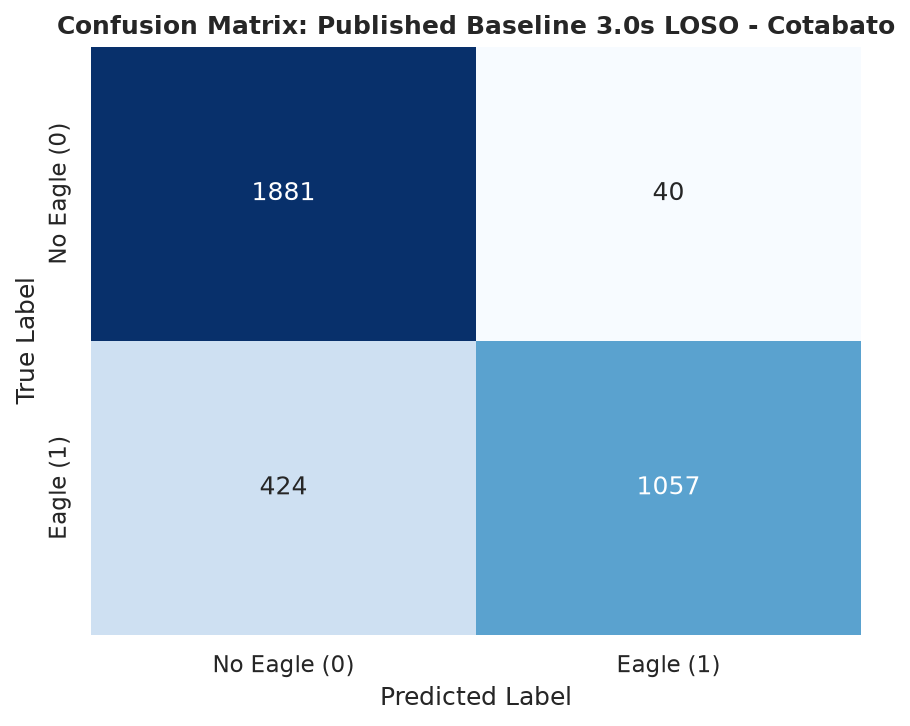

In [12]:
# Published Baseline on the 3.0s LOSO - Cotabato
ablation_metrics[("published-baseline", "loso-cotabato")] = run_ablation_experiment("published-baseline", "loso-cotabato")

#### 5.2.4 Train or Load, Plot History, and Evaluate: Published Baseline (3.0s Minor Sites Held Out)


Training Published Baseline 3.0s Minor Sites Held Out on 9,615 windows (2,853 eagle)...
Epoch 1/50


E0000 00:00:1791901290.140460   59966 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/Published_CRNN_GRU_1/conv_dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


301/301 ━━━━━━━━━━━━━━━━━━━━ 16s 45ms/step - accuracy: 0.8157 - auc: 0.8599 - loss: 0.4074 - precision: 0.7946 - recall: 0.5110 - val_accuracy: 0.8851 - val_auc: 0.9387 - val_loss: 0.2808 - val_precision: 0.8206 - val_recall: 0.7719
Epoch 2/50
301/301 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.9114 - auc: 0.9547 - loss: 0.2338 - precision: 0.8701 - recall: 0.8244 - val_accuracy: 0.8959 - val_auc: 0.9561 - val_loss: 0.2459 - val_precision: 0.8648 - val_recall: 0.7594
Epoch 3/50
301/301 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9186 - auc: 0.9626 - loss: 0.2119 - precision: 0.8862 - recall: 0.8325 - val_accuracy: 0.9167 - val_auc: 0.9673 - val_loss: 0.2096 - val_precision: 0.8851 - val_recall: 0.8188
Epoch 4/50
301/301 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.9244 - auc: 0.9695 - loss: 0.1930 - precision: 0.8937 - recall: 0.8458 - val_accuracy: 0.9303 - val_auc: 0.9725 - val_loss: 0.1883 - val_precision: 0.9175 - val_recall: 0.8344
Epoch 5/50
301/301 ━━━━━━━━━━━━━━━━

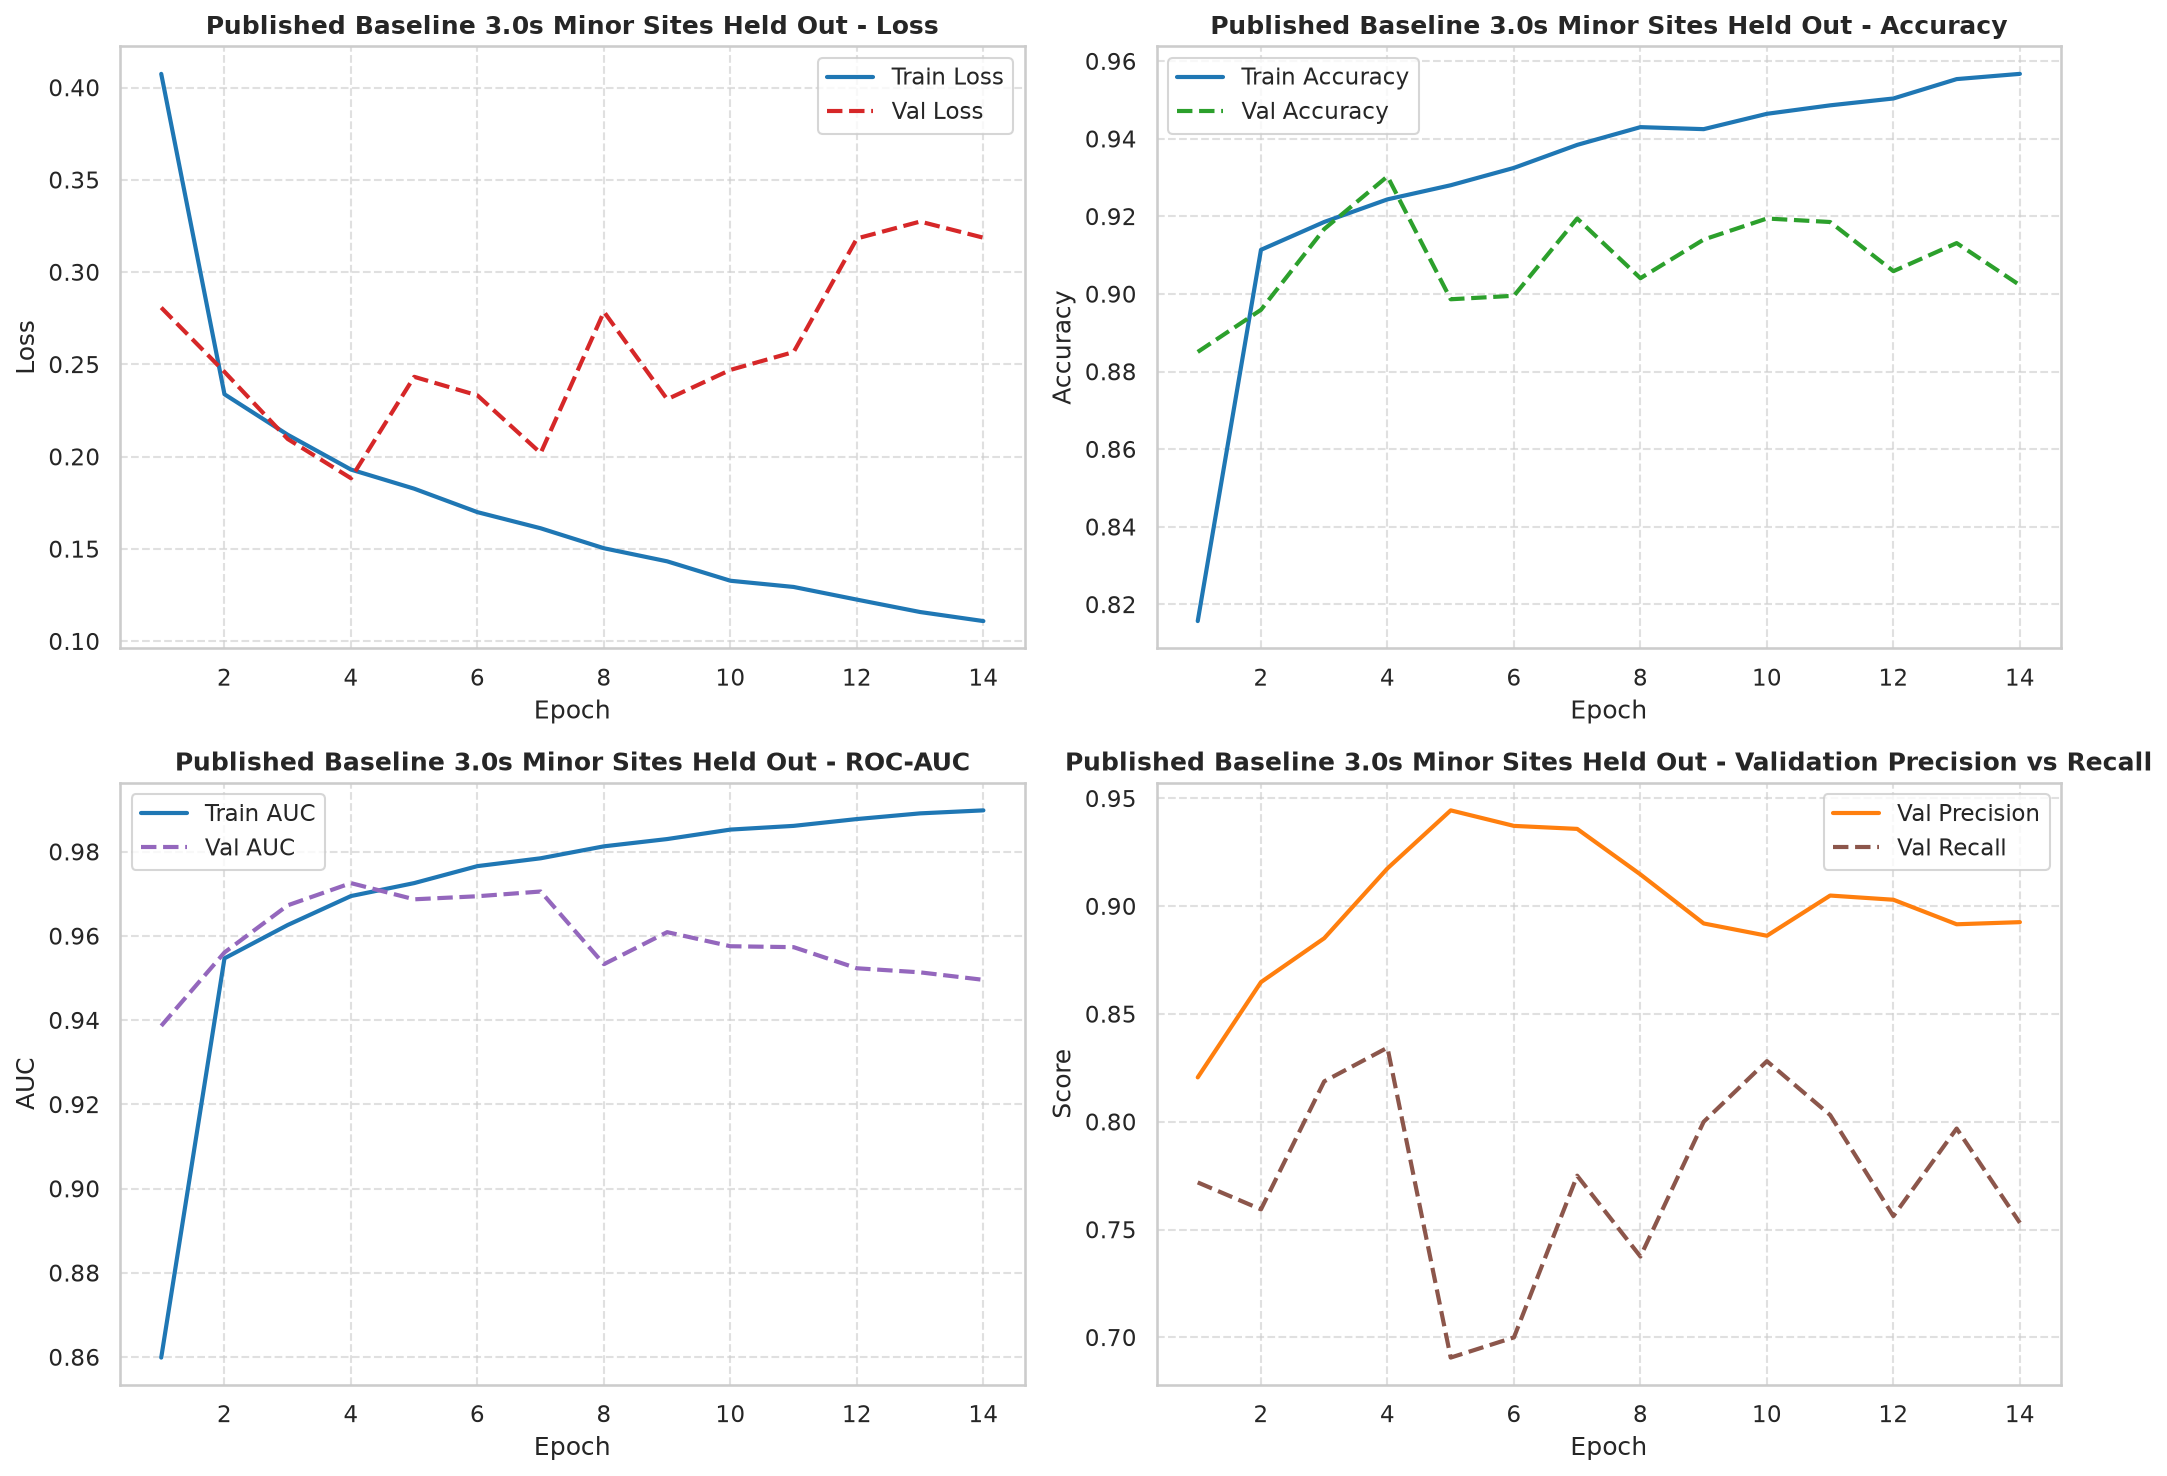

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step
EVALUATION RESULTS: Published Baseline 3.0s Minor Sites Held Out
Accuracy:    0.7967 (79.67%)
Precision:   0.9412 (94.12%)
Recall:      0.5854 (58.54%)
F1-Score:    0.7218 (72.18%)
Specificity: 0.9700 (97.00%)
ROC-AUC:     0.9179
Confusion:   TN 194 | FP 6 | FN 68 | TP 96
              precision    recall  f1-score   support

No Eagle (0)       0.74      0.97      0.84       200
   Eagle (1)       0.94      0.59      0.72       164

    accuracy                           0.80       364
   macro avg       0.84      0.78      0.78       364
weighted avg       0.83      0.80      0.79       364

Saved statistics to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/outputs/3-seconds/published-baseline/minor-sites/statistics.txt
Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/outputs/3-seconds/published-baseline/minor-sites/confusion-mat

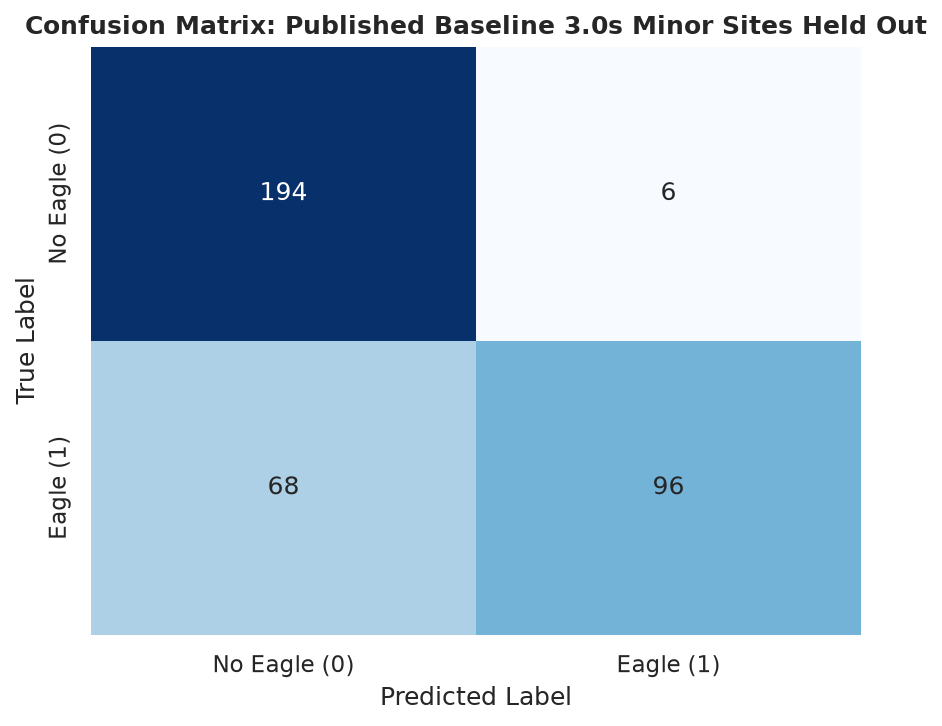

In [13]:
# Published Baseline on the 3.0s Minor Sites Held Out
ablation_metrics[("published-baseline", "minor-sites")] = run_ablation_experiment("published-baseline", "minor-sites")

### 5.3. Step 1: Compact CRNN-GRU

The smaller architecture of this study (304,737 parameters) replaces the published one. Everything else is as in step 0.


#### 5.3.1 Train or Load, Plot History, and Evaluate: Compact CRNN-GRU (3.0s Recording Split)


Training Compact CRNN-GRU 3.0s Recording Split on 8,281 windows (2,403 eagle)...
Epoch 1/50


I0000 00:00:1791901481.711978   60085 service.cc:153] XLA service 0x55c0e7cc1820 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791901481.711996   60085 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.25.1)
I0000 00:00:1791901481.822825   60085 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791901482.666472   60085 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_183586__.94
I0000 00:00:1791901483.547018   72813 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_17', 8652 bytes spill stores, 8640 bytes spill loads

I0000 00:00:1791901484.819475   60085 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Mayb

  6/259 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.6979 - auc: 0.5778 - loss: 0.6336 - precision: 0.4000 - recall: 0.1091

I0000 00:00:1791901501.289575   60085 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


258/259 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8505 - auc: 0.9040 - loss: 0.3453 - precision: 0.8005 - recall: 0.6462

I0000 00:00:1791901508.786340   60082 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_183586__.94
I0000 00:00:1791901511.508881   76842 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_17', 9456 bytes spill stores, 9480 bytes spill loads



259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.8509 - auc: 0.9043 - loss: 0.3448 - precision: 0.8007 - recall: 0.6471

I0000 00:00:1791901523.251555   60085 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_186771__.23
I0000 00:00:1791901528.799920   60083 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_186771__.23


259/259 ━━━━━━━━━━━━━━━━━━━━ 55s 124ms/step - accuracy: 0.8509 - auc: 0.9043 - loss: 0.3448 - precision: 0.8007 - recall: 0.6471 - val_accuracy: 0.7302 - val_auc: 0.7637 - val_loss: 0.5704 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.9127 - auc: 0.9577 - loss: 0.2288 - precision: 0.8681 - recall: 0.8244 - val_accuracy: 0.8099 - val_auc: 0.8546 - val_loss: 0.6019 - val_precision: 0.9931 - val_recall: 0.2975
Epoch 3/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.9174 - auc: 0.9649 - loss: 0.2073 - precision: 0.8755 - recall: 0.8340 - val_accuracy: 0.8857 - val_auc: 0.9546 - val_loss: 0.2950 - val_precision: 0.9457 - val_recall: 0.6116
Epoch 4/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - accuracy: 0.9271 - auc: 0.9690 - loss: 0.1899 - precision: 0.8933 - recall: 0.8502 - val_accuracy: 0.9181 - val_auc: 0.9517 - val_loss: 0.2497 - val_precision: 0.8210 - val_recall: 0.8905
Epoch 5/50
259/259 ━━━━━━━━━━

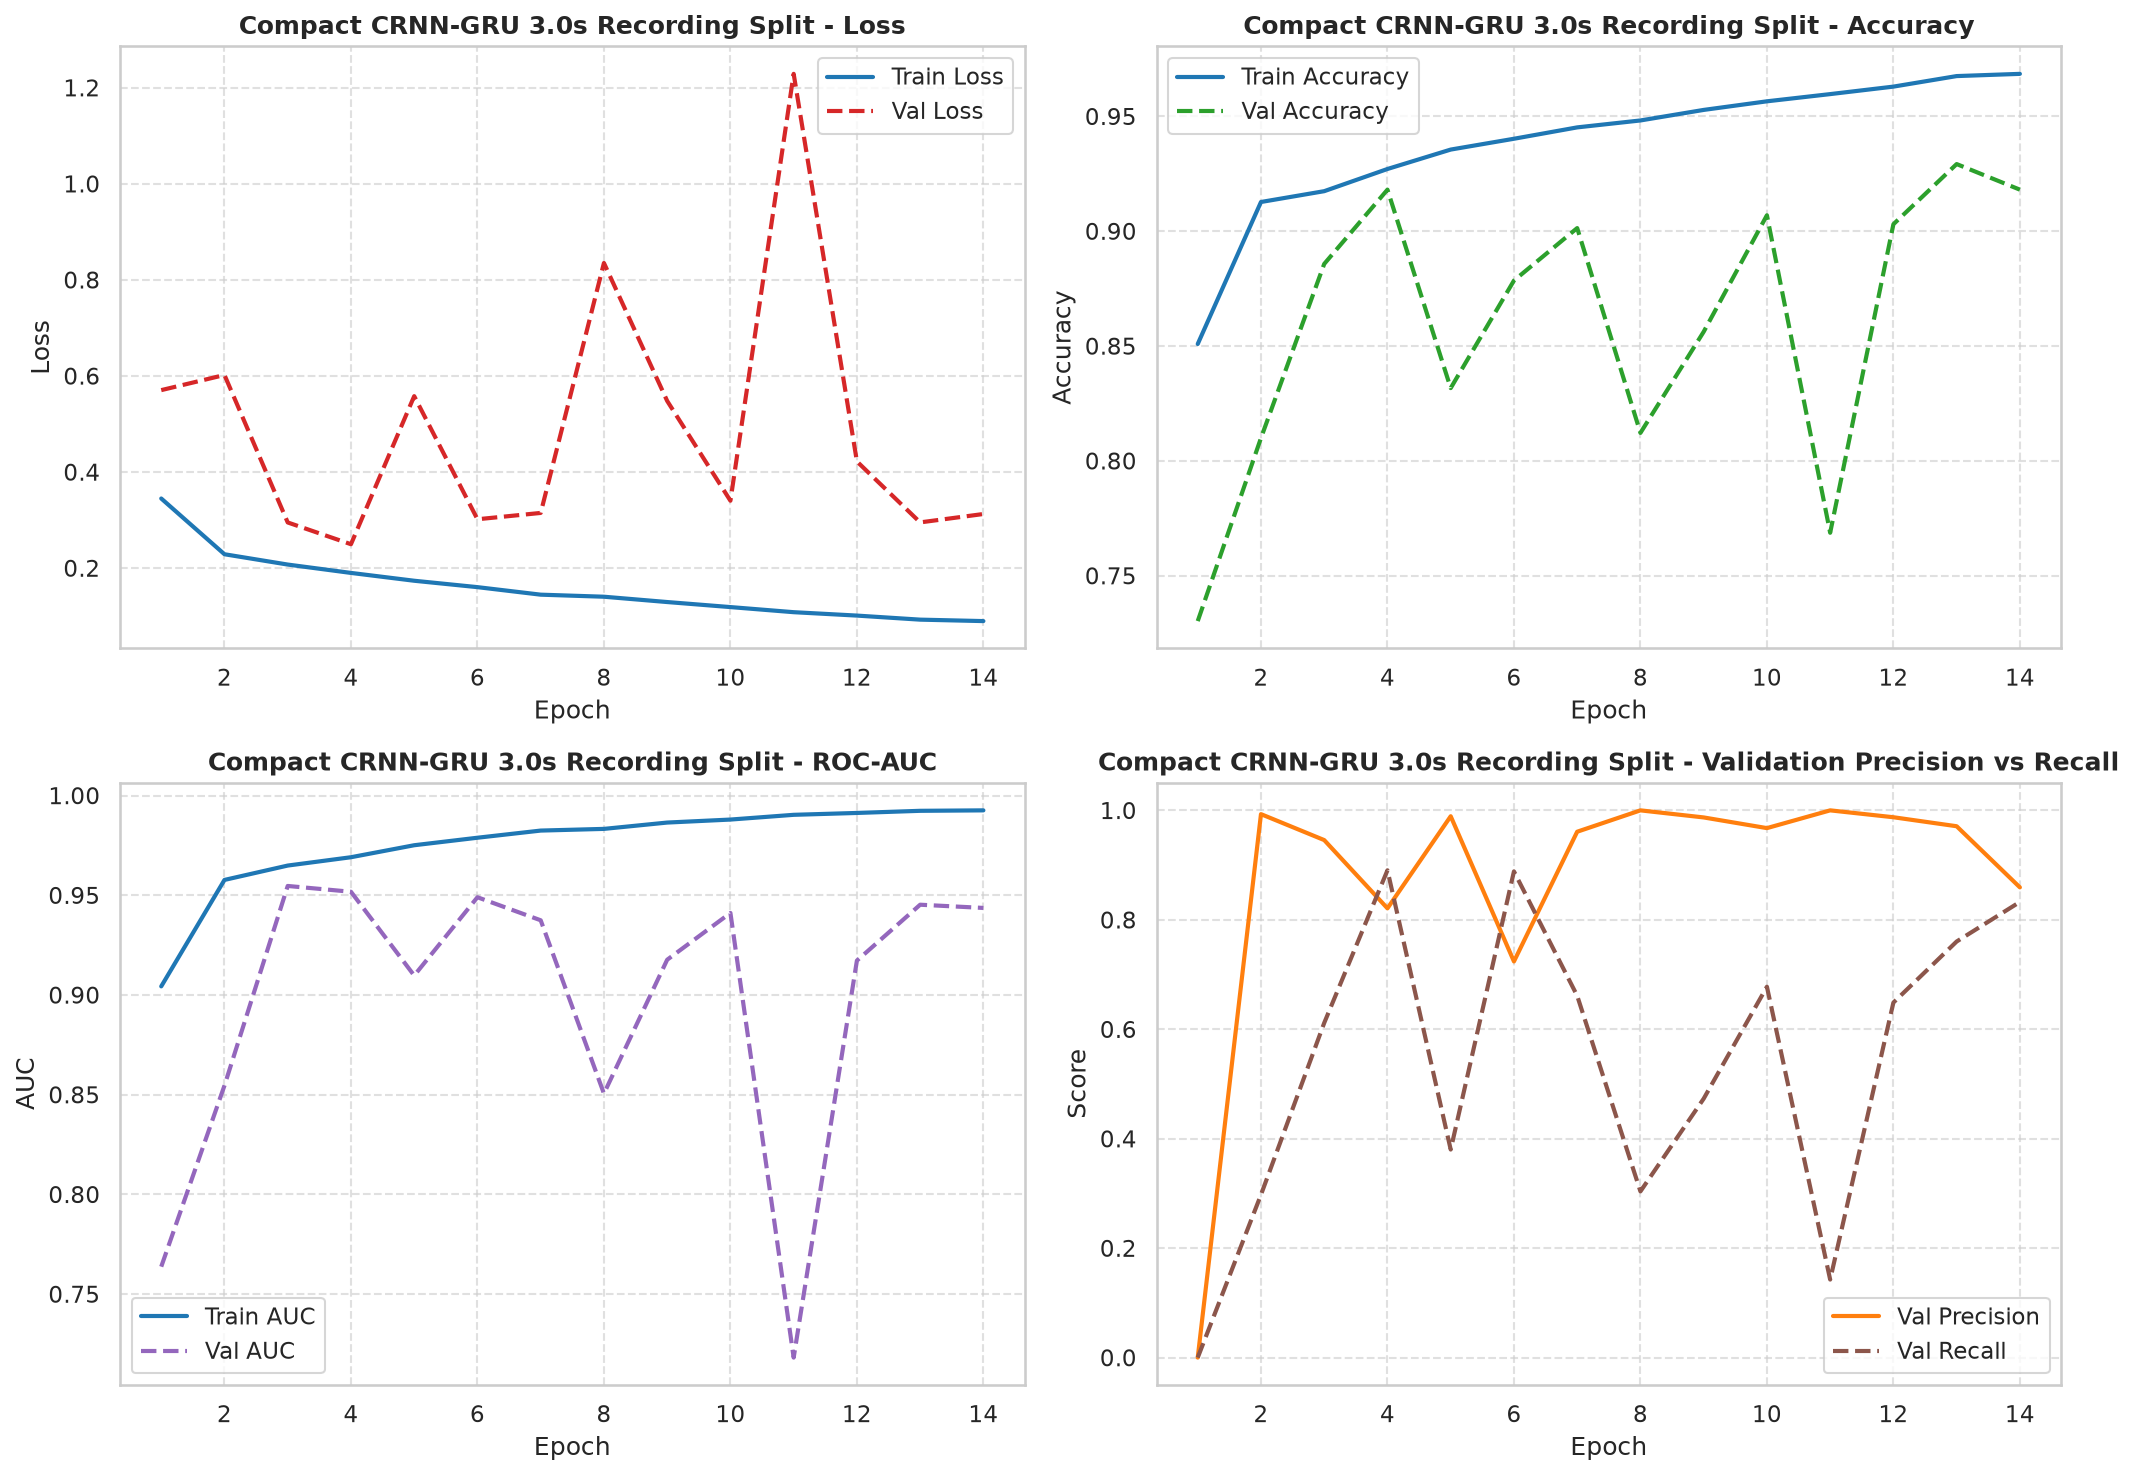

I0000 00:00:1791901629.108231   60085 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_219893__.7


22/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

I0000 00:00:1791901631.378006   60083 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_220773__.7
I0000 00:00:1791901632.303784   79378 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_15', 9456 bytes spill stores, 9480 bytes spill loads



32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 184ms/step
EVALUATION RESULTS: Compact CRNN-GRU 3.0s Recording Split
Accuracy:    0.9177 (91.77%)
Precision:   0.8896 (88.96%)
Recall:      0.9311 (93.11%)
F1-Score:    0.9099 (90.99%)
Specificity: 0.9070 (90.70%)
ROC-AUC:     0.9685
Confusion:   TN 507 | FP 52 | FN 31 | TP 419
              precision    recall  f1-score   support

No Eagle (0)       0.94      0.91      0.92       559
   Eagle (1)       0.89      0.93      0.91       450

    accuracy                           0.92      1009
   macro avg       0.92      0.92      0.92      1009
weighted avg       0.92      0.92      0.92      1009

Saved statistics to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/outputs/3-seconds/compact/recording-split/statistics.txt
Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/outputs/3-seconds/compact/recording-split/confusion-matrix.png


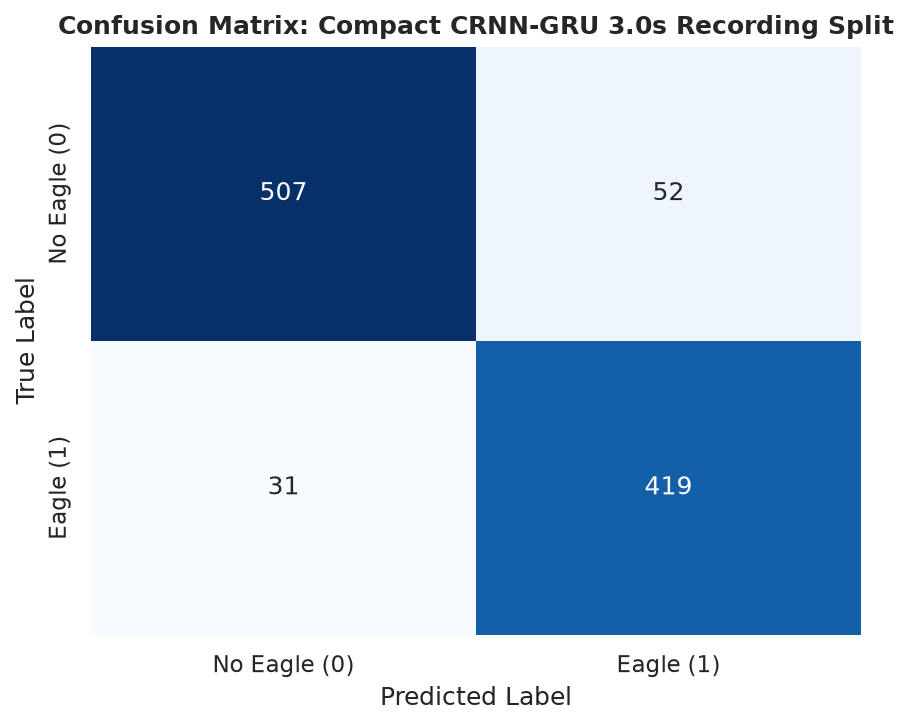

In [14]:
# Compact CRNN-GRU on the 3.0s Recording Split
ablation_metrics[("compact", "recording-split")] = run_ablation_experiment("compact", "recording-split")

#### 5.3.2 Train or Load, Plot History, and Evaluate: Compact CRNN-GRU (3.0s LOSO - Davao del Sur)


In [ ]:
# Compact CRNN-GRU on the 3.0s LOSO - Davao del Sur
ablation_metrics[("compact", "loso-davao")] = run_ablation_experiment("compact", "loso-davao")

Training Compact CRNN-GRU 3.0s LOSO - Davao del Sur on 5,228 windows (1,399 eagle)...
Epoch 1/50


I0000 00:00:1791901641.451398   60088 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_229596__.94


162/164 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8858 - auc: 0.9401 - loss: 0.2713 - precision: 0.8410 - recall: 0.7079

I0000 00:00:1791901652.200339   60085 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_229596__.94
I0000 00:00:1791901654.516532   83483 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_17', 8776 bytes spill stores, 8744 bytes spill loads



164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.8864 - auc: 0.9402 - loss: 0.2703 - precision: 0.8414 - recall: 0.7091

I0000 00:00:1791901668.989666   60085 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_232116__.23
I0000 00:00:1791901671.028359   60083 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_232116__.23
I0000 00:00:1791901672.762544   85615 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_15', 8692 bytes spill stores, 8692 bytes spill loads



164/164 ━━━━━━━━━━━━━━━━━━━━ 40s 188ms/step - accuracy: 0.8864 - auc: 0.9402 - loss: 0.2703 - precision: 0.8414 - recall: 0.7091 - val_accuracy: 0.7242 - val_auc: 0.6710 - val_loss: 0.7900 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/50
164/164 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.9468 - auc: 0.9741 - loss: 0.1609 - precision: 0.9224 - recall: 0.8749 - val_accuracy: 0.7242 - val_auc: 0.7032 - val_loss: 0.7085 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/50
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.9529 - auc: 0.9808 - loss: 0.1348 - precision: 0.9364 - recall: 0.8842 - val_accuracy: 0.8274 - val_auc: 0.8399 - val_loss: 0.4657 - val_precision: 1.0000 - val_recall: 0.3740
Epoch 4/50
164/164 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.9581 - auc: 0.9826 - loss: 0.1280 - precision: 0.9403 - recall: 0.9006 - val_accuracy: 0.8509 - val_auc: 0.8932 - val_loss: 0.4200 - val_precision: 0.8742 - val_recall: 0.5366
Epoch 5/50
164/164 ━━

#### 5.3.3 Train or Load, Plot History, and Evaluate: Compact CRNN-GRU (3.0s LOSO - Cotabato)


In [ ]:
# Compact CRNN-GRU on the 3.0s LOSO - Cotabato
ablation_metrics[("compact", "loso-cotabato")] = run_ablation_experiment("compact", "loso-cotabato")

#### 5.3.4 Train or Load, Plot History, and Evaluate: Compact CRNN-GRU (3.0s Minor Sites Held Out)


In [ ]:
# Compact CRNN-GRU on the 3.0s Minor Sites Held Out
ablation_metrics[("compact", "minor-sites")] = run_ablation_experiment("compact", "minor-sites")

### 5.4. Step 2: + PCEN

PCEN replaces the log-Mel input. Everything else is as in step 1.


#### 5.4.1 Train or Load, Plot History, and Evaluate: Compact + PCEN (3.0s Recording Split)


In [ ]:
# Compact + PCEN on the 3.0s Recording Split
ablation_metrics[("compact-pcen", "recording-split")] = run_ablation_experiment("compact-pcen", "recording-split")

#### 5.4.2 Train or Load, Plot History, and Evaluate: Compact + PCEN (3.0s LOSO - Davao del Sur)


In [ ]:
# Compact + PCEN on the 3.0s LOSO - Davao del Sur
ablation_metrics[("compact-pcen", "loso-davao")] = run_ablation_experiment("compact-pcen", "loso-davao")

#### 5.4.3 Train or Load, Plot History, and Evaluate: Compact + PCEN (3.0s LOSO - Cotabato)


In [ ]:
# Compact + PCEN on the 3.0s LOSO - Cotabato
ablation_metrics[("compact-pcen", "loso-cotabato")] = run_ablation_experiment("compact-pcen", "loso-cotabato")

#### 5.4.4 Train or Load, Plot History, and Evaluate: Compact + PCEN (3.0s Minor Sites Held Out)


In [ ]:
# Compact + PCEN on the 3.0s Minor Sites Held Out
ablation_metrics[("compact-pcen", "minor-sites")] = run_ablation_experiment("compact-pcen", "minor-sites")

### 5.5. Step 3: + Augmentation

The pitch-shifted copies of the eagle windows are added to training, with gain scaling and SpecAugment masks on both classes. Everything else is as in step 2.


#### 5.5.1 Train or Load, Plot History, and Evaluate: Compact + PCEN + Augmentation (3.0s Recording Split)


In [ ]:
# Compact + PCEN + Augmentation on the 3.0s Recording Split
ablation_metrics[("compact-pcen-augmented", "recording-split")] = run_ablation_experiment("compact-pcen-augmented", "recording-split")

#### 5.5.2 Train or Load, Plot History, and Evaluate: Compact + PCEN + Augmentation (3.0s LOSO - Davao del Sur)


In [ ]:
# Compact + PCEN + Augmentation on the 3.0s LOSO - Davao del Sur
ablation_metrics[("compact-pcen-augmented", "loso-davao")] = run_ablation_experiment("compact-pcen-augmented", "loso-davao")

#### 5.5.3 Train or Load, Plot History, and Evaluate: Compact + PCEN + Augmentation (3.0s LOSO - Cotabato)


In [ ]:
# Compact + PCEN + Augmentation on the 3.0s LOSO - Cotabato
ablation_metrics[("compact-pcen-augmented", "loso-cotabato")] = run_ablation_experiment("compact-pcen-augmented", "loso-cotabato")

#### 5.5.4 Train or Load, Plot History, and Evaluate: Compact + PCEN + Augmentation (3.0s Minor Sites Held Out)


In [ ]:
# Compact + PCEN + Augmentation on the 3.0s Minor Sites Held Out
ablation_metrics[("compact-pcen-augmented", "minor-sites")] = run_ablation_experiment("compact-pcen-augmented", "minor-sites")

### 5.6. Step 4: + Training Stabilization

3-epoch learning rate warmup from 1e-4 to 5e-4, cosine decay to 1e-5, gradient clipping at 0.5, and a running average of the weights (EMA, momentum 0.99) for validation, early stopping and the saved model. Everything else is as in step 3.


#### 5.6.1 Train or Load, Plot History, and Evaluate: Compact + Stabilization (3.0s Recording Split)


In [ ]:
# Compact + Stabilization on the 3.0s Recording Split
ablation_metrics[("compact-stabilized", "recording-split")] = run_ablation_experiment("compact-stabilized", "recording-split")

#### 5.6.2 Train or Load, Plot History, and Evaluate: Compact + Stabilization (3.0s LOSO - Davao del Sur)


In [ ]:
# Compact + Stabilization on the 3.0s LOSO - Davao del Sur
ablation_metrics[("compact-stabilized", "loso-davao")] = run_ablation_experiment("compact-stabilized", "loso-davao")

#### 5.6.3 Train or Load, Plot History, and Evaluate: Compact + Stabilization (3.0s LOSO - Cotabato)


In [ ]:
# Compact + Stabilization on the 3.0s LOSO - Cotabato
ablation_metrics[("compact-stabilized", "loso-cotabato")] = run_ablation_experiment("compact-stabilized", "loso-cotabato")

#### 5.6.4 Train or Load, Plot History, and Evaluate: Compact + Stabilization (3.0s Minor Sites Held Out)


In [ ]:
# Compact + Stabilization on the 3.0s Minor Sites Held Out
ablation_metrics[("compact-stabilized", "minor-sites")] = run_ablation_experiment("compact-stabilized", "minor-sites")

### 5.7. Step 5: + Focal Loss (Model A, Standard CRNN-GRU)

Focal loss (γ = 1.5) with equal class weighting replaces binary cross-entropy, so a missed eagle and a false alarm still cost the same. Everything else is as in step 4: warmup and cosine learning rate, gradient clipping, EMA weights, and SpecAugment masks on both classes.


#### 5.7.1 Train or Load Model (3.0s Recording Split)


In [ ]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

# Train or load 3.0s Recording Split CRNN-GRU model (Guarded)
model_3s_std_path = MODELS_3S_STD / "crnn-gru-std.keras"
history_3s_std_path = MODELS_3S_STD / "training_history.json"

if model_3s_std_path.exists():
    print(f"Model already exists at: {model_3s_std_path}")
    print("Loading cached model...")
    model_3s_std = tf.keras.models.load_model(model_3s_std_path)
    with open(history_3s_std_path, "r") as f:
        history_3s_std = json.load(f)
    print("Model and training history loaded successfully from cache!")
else:
    print("Training 3.0s Recording Split CRNN-GRU model with focal loss (gamma=1.5, equal class weighting)...")
    model_3s_std = build_crnn_gru_model(input_shape=SHAPE_3S, learning_rate=1e-4)
    # Focal loss with equal class weighting: both kinds of mistakes cost the same
    focal_loss_fn = tf.keras.losses.BinaryFocalCrossentropy(apply_class_balancing=False, gamma=1.5)
    model_3s_std.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=0.5, use_ema=True, ema_momentum=0.99),
        loss=focal_loss_fn,
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )

    # On-the-fly training generator (Gain jitter + SpecAugment time/freq masking)
    train_gen_3s_std = SpecAugmentDataGenerator(
        X_train_3s_std,
        y_train_3s_std,
        batch_size=BATCH_SIZE,
        is_training=True,
        shuffle=True,
        mask_all_classes=True
    )

    # SwapEMAWeights goes first so validation, early stopping and the checkpoint all use the averaged weights
    callbacks = [
        tf.keras.callbacks.SwapEMAWeights(swap_on_epoch=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        make_warmup_cosine_callback(target_lr=5e-4, start_lr=1e-4, min_lr=1e-5, warmup_epochs=3),
        tf.keras.callbacks.ModelCheckpoint(str(MODELS_3S_STD / "checkpoints" / "best_model.keras"), monitor="val_loss", save_best_only=True)
    ]

    fit_res = model_3s_std.fit(
        train_gen_3s_std,
        validation_data=(X_val_3s_std, y_val_3s_std),
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1
    )

    history_3s_std = fit_res.history
    model_3s_std.save(model_3s_std_path)
    with open(history_3s_std_path, "w") as f:
        json.dump({k: [float(x) for x in vals] for k, vals in history_3s_std.items()}, f)
    print(f"Saved trained model to: {model_3s_std_path}")


#### 5.7.2 Training History Visualization (3.0s Recording Split)


In [ ]:
# Visualize training curves (3.0s Recording Split)
history_fig_3s_std = model_output_dir("standard", "recording-split") / "training-history.png"
plot_training_history(history_3s_std, history_fig_3s_std, title_prefix="CRNN-GRU 3.0s Recording Split")


#### 5.7.3 FP32 Model Evaluation on Test Set (3.0s Recording Split)


In [ ]:
# Evaluate FP32 model on clean test set (3.0s Recording Split)
y_pred_prob_3s_std = model_3s_std.predict(X_test_3s_std, batch_size=BATCH_SIZE).ravel()
cm_fig_3s_std = model_output_dir("standard", "recording-split") / "confusion-matrix.png"
metrics_3s_std = evaluate_predictions(y_test_3s_std, y_pred_prob_3s_std, "CRNN-GRU 3.0s Recording Split", cm_fig_3s_std)


#### 5.7.4 Edge Quantization Benchmark: Float16 & INT8 (3.0s Recording Split)


In [ ]:
# Edge Quantization Benchmark: Float16 & INT8 (3.0s Recording Split, Guarded)
tflite_3s_std_fp16_path = MODELS_3S_STD / "crnn-gru-std-fp16.tflite"
tflite_3s_std_int8_path = MODELS_3S_STD / "crnn-gru-std-int8.tflite"

# 1. Float16 Quantization
if not tflite_3s_std_fp16_path.exists():
    print("Converting model to Float16 TFLite...")
    convert_to_tflite_fp16(model_3s_std, tflite_3s_std_fp16_path)
    print(f"Saved Float16 TFLite model to: {tflite_3s_std_fp16_path}")
else:
    print(f"Loading cached Float16 model from: {tflite_3s_std_fp16_path}")

fp16_res_3s_std = evaluate_tflite_model(tflite_3s_std_fp16_path, X_test_3s_std, y_test_3s_std)

# 2. Full INT8 Quantization (with Balanced Representative Dataset Calibration)
if not tflite_3s_std_int8_path.exists():
    print("Converting model to INT8 TFLite with balanced representative calibration...")
    rng_calib = np.random.default_rng(SEED)
    pos_idx = np.where(y_train_3s_std == 1)[0]
    neg_idx = np.where(y_train_3s_std == 0)[0]
    sel_pos = rng_calib.choice(pos_idx, size=min(150, len(pos_idx)), replace=False)
    sel_neg = rng_calib.choice(neg_idx, size=min(150, len(neg_idx)), replace=False)
    calib_indices = rng_calib.permutation(np.concatenate([sel_pos, sel_neg]))
    calib_data = X_train_3s_std[calib_indices]
    convert_to_tflite_int8(model_3s_std, calib_data, tflite_3s_std_int8_path)
    print(f"Saved INT8 TFLite model to: {tflite_3s_std_int8_path}")
else:
    print(f"Loading cached INT8 model from: {tflite_3s_std_int8_path}")

int8_res_3s_std = evaluate_tflite_model(tflite_3s_std_int8_path, X_test_3s_std, y_test_3s_std)

fp32_size_kb = os.path.getsize(model_3s_std_path) / 1024.0
fp16_size_kb = fp16_res_3s_std["model_size_kb"]
int8_size_kb = int8_res_3s_std["model_size_kb"]

print("=" * 75)
print("3.0S STANDARD SPLIT: FP32 vs. FLOAT16 vs. INT8 EDGE BENCHMARK")
print("=" * 75)
print(f"FP32 Model:      Size = {fp32_size_kb:6.1f} KB | Acc = {metrics_3s_std['accuracy']*100:.2f}% | F1 = {metrics_3s_std['f1_score']:.4f}")
print(f"Float16 Model:   Size = {fp16_size_kb:6.1f} KB | Acc = {fp16_res_3s_std['accuracy']*100:.2f}% | F1 = {fp16_res_3s_std['f1_score']:.4f} | Latency = {fp16_res_3s_std['latency_ms']:.2f} ms")
print(f"Full INT8 Model: Size = {int8_size_kb:6.1f} KB | Acc = {int8_res_3s_std['accuracy']*100:.2f}% | F1 = {int8_res_3s_std['f1_score']:.4f} | Latency = {int8_res_3s_std['latency_ms']:.2f} ms")
print("=" * 75)


#### 5.7.5 Train or Load Model (3.0s Leave-One-Site-Out (LOSO) - Davao del Sur)


In [ ]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

# Train or load 3.0s Leave-One-Site-Out (LOSO) - Davao del Sur CRNN-GRU model (Guarded)
model_3s_loso_davao_path = MODELS_3S_LOSO_DAVAO / "crnn-gru-loso_davao.keras"
history_3s_loso_davao_path = MODELS_3S_LOSO_DAVAO / "training_history.json"

if model_3s_loso_davao_path.exists():
    print(f"Model already exists at: {model_3s_loso_davao_path}")
    print("Loading cached model...")
    model_3s_loso_davao = tf.keras.models.load_model(model_3s_loso_davao_path)
    with open(history_3s_loso_davao_path, "r") as f:
        history_3s_loso_davao = json.load(f)
    print("Model and training history loaded successfully from cache!")
else:
    print("Training 3.0s Leave-One-Site-Out (LOSO) - Davao del Sur CRNN-GRU model with focal loss (gamma=1.5, equal class weighting)...")
    model_3s_loso_davao = build_crnn_gru_model(input_shape=SHAPE_3S, learning_rate=1e-4)
    # Focal loss with equal class weighting: both kinds of mistakes cost the same
    focal_loss_fn = tf.keras.losses.BinaryFocalCrossentropy(apply_class_balancing=False, gamma=1.5)
    model_3s_loso_davao.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=0.5, use_ema=True, ema_momentum=0.99),
        loss=focal_loss_fn,
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )

    # On-the-fly training generator (Gain jitter + SpecAugment time/freq masking)
    train_gen_3s_loso_davao = SpecAugmentDataGenerator(
        X_train_3s_loso_davao,
        y_train_3s_loso_davao,
        batch_size=BATCH_SIZE,
        is_training=True,
        shuffle=True,
        mask_all_classes=True
    )

    # SwapEMAWeights goes first so validation, early stopping and the checkpoint all use the averaged weights
    callbacks = [
        tf.keras.callbacks.SwapEMAWeights(swap_on_epoch=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        make_warmup_cosine_callback(target_lr=5e-4, start_lr=1e-4, min_lr=1e-5, warmup_epochs=3),
        tf.keras.callbacks.ModelCheckpoint(str(MODELS_3S_LOSO_DAVAO / "checkpoints" / "best_model.keras"), monitor="val_loss", save_best_only=True)
    ]

    fit_res = model_3s_loso_davao.fit(
        train_gen_3s_loso_davao,
        validation_data=(X_val_3s_loso_davao, y_val_3s_loso_davao),
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1
    )

    history_3s_loso_davao = fit_res.history
    model_3s_loso_davao.save(model_3s_loso_davao_path)
    with open(history_3s_loso_davao_path, "w") as f:
        json.dump({k: [float(x) for x in vals] for k, vals in history_3s_loso_davao.items()}, f)
    print(f"Saved trained model to: {model_3s_loso_davao_path}")


#### 5.7.6 Training History Visualization (3.0s Leave-One-Site-Out (LOSO) - Davao del Sur)


In [ ]:
# Visualize training curves (3.0s Leave-One-Site-Out (LOSO) - Davao del Sur)
history_fig_3s_loso_davao = model_output_dir("standard", "loso-davao") / "training-history.png"
plot_training_history(history_3s_loso_davao, history_fig_3s_loso_davao, title_prefix="CRNN-GRU 3.0s LOSO - Davao del Sur")


#### 5.7.7 FP32 Model Evaluation on Test Set (3.0s Leave-One-Site-Out (LOSO) - Davao del Sur)


In [ ]:
# Evaluate FP32 model on clean test set (3.0s Leave-One-Site-Out (LOSO) - Davao del Sur)
y_pred_prob_3s_loso_davao = model_3s_loso_davao.predict(X_test_3s_loso_davao, batch_size=BATCH_SIZE).ravel()
cm_fig_3s_loso_davao = model_output_dir("standard", "loso-davao") / "confusion-matrix.png"
metrics_3s_loso_davao = evaluate_predictions(y_test_3s_loso_davao, y_pred_prob_3s_loso_davao, "CRNN-GRU 3.0s LOSO - Davao del Sur", cm_fig_3s_loso_davao)


#### 5.7.8 Train or Load Model (3.0s Leave-One-Site-Out (LOSO) - Cotabato)


In [ ]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

# Train or load 3.0s Leave-One-Site-Out (LOSO) - Cotabato CRNN-GRU model (Guarded)
model_3s_loso_cotabato_path = MODELS_3S_LOSO_COTABATO / "crnn-gru-loso_cotabato.keras"
history_3s_loso_cotabato_path = MODELS_3S_LOSO_COTABATO / "training_history.json"

if model_3s_loso_cotabato_path.exists():
    print(f"Model already exists at: {model_3s_loso_cotabato_path}")
    print("Loading cached model...")
    model_3s_loso_cotabato = tf.keras.models.load_model(model_3s_loso_cotabato_path)
    with open(history_3s_loso_cotabato_path, "r") as f:
        history_3s_loso_cotabato = json.load(f)
    print("Model and training history loaded successfully from cache!")
else:
    print("Training 3.0s Leave-One-Site-Out (LOSO) - Cotabato CRNN-GRU model with focal loss (gamma=1.5, equal class weighting)...")
    model_3s_loso_cotabato = build_crnn_gru_model(input_shape=SHAPE_3S, learning_rate=1e-4)
    # Focal loss with equal class weighting: both kinds of mistakes cost the same
    focal_loss_fn = tf.keras.losses.BinaryFocalCrossentropy(apply_class_balancing=False, gamma=1.5)
    model_3s_loso_cotabato.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=0.5, use_ema=True, ema_momentum=0.99),
        loss=focal_loss_fn,
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )

    # On-the-fly training generator (Gain jitter + SpecAugment time/freq masking)
    train_gen_3s_loso_cotabato = SpecAugmentDataGenerator(
        X_train_3s_loso_cotabato,
        y_train_3s_loso_cotabato,
        batch_size=BATCH_SIZE,
        is_training=True,
        shuffle=True,
        mask_all_classes=True
    )

    # SwapEMAWeights goes first so validation, early stopping and the checkpoint all use the averaged weights
    callbacks = [
        tf.keras.callbacks.SwapEMAWeights(swap_on_epoch=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        make_warmup_cosine_callback(target_lr=5e-4, start_lr=1e-4, min_lr=1e-5, warmup_epochs=3),
        tf.keras.callbacks.ModelCheckpoint(str(MODELS_3S_LOSO_COTABATO / "checkpoints" / "best_model.keras"), monitor="val_loss", save_best_only=True)
    ]

    fit_res = model_3s_loso_cotabato.fit(
        train_gen_3s_loso_cotabato,
        validation_data=(X_val_3s_loso_cotabato, y_val_3s_loso_cotabato),
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1
    )

    history_3s_loso_cotabato = fit_res.history
    model_3s_loso_cotabato.save(model_3s_loso_cotabato_path)
    with open(history_3s_loso_cotabato_path, "w") as f:
        json.dump({k: [float(x) for x in vals] for k, vals in history_3s_loso_cotabato.items()}, f)
    print(f"Saved trained model to: {model_3s_loso_cotabato_path}")


#### 5.7.9 Training History Visualization (3.0s Leave-One-Site-Out (LOSO) - Cotabato)


In [ ]:
# Visualize training curves (3.0s Leave-One-Site-Out (LOSO) - Cotabato)
history_fig_3s_loso_cotabato = model_output_dir("standard", "loso-cotabato") / "training-history.png"
plot_training_history(history_3s_loso_cotabato, history_fig_3s_loso_cotabato, title_prefix="CRNN-GRU 3.0s LOSO - Cotabato")


#### 5.7.10 FP32 Model Evaluation on Test Set (3.0s Leave-One-Site-Out (LOSO) - Cotabato)


In [ ]:
# Evaluate FP32 model on clean test set (3.0s Leave-One-Site-Out (LOSO) - Cotabato)
y_pred_prob_3s_loso_cotabato = model_3s_loso_cotabato.predict(X_test_3s_loso_cotabato, batch_size=BATCH_SIZE).ravel()
cm_fig_3s_loso_cotabato = model_output_dir("standard", "loso-cotabato") / "confusion-matrix.png"
metrics_3s_loso_cotabato = evaluate_predictions(y_test_3s_loso_cotabato, y_pred_prob_3s_loso_cotabato, "CRNN-GRU 3.0s LOSO - Cotabato", cm_fig_3s_loso_cotabato)


#### 5.7.11 Train or Load Model (3.0s Minor Sites Held Out, Standard)


In [ ]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

MODELS_3S_LOSO_MINOR = MODELS_DIR / "3-seconds" / "loso-minor-sites"
(MODELS_3S_LOSO_MINOR / "checkpoints").mkdir(parents=True, exist_ok=True)

# Train or load 3.0s Minor Sites Held Out CRNN-GRU model (Guarded)
model_3s_loso_minor_path = MODELS_3S_LOSO_MINOR / "crnn-gru-loso_minor_sites.keras"
history_3s_loso_minor_path = MODELS_3S_LOSO_MINOR / "training_history.json"

if model_3s_loso_minor_path.exists():
    print(f"Model already exists at: {model_3s_loso_minor_path}")
    print("Loading cached model...")
    model_3s_loso_minor = tf.keras.models.load_model(model_3s_loso_minor_path)
    with open(history_3s_loso_minor_path, "r") as f:
        history_3s_loso_minor = json.load(f)
    print("Model and training history loaded successfully from cache!")
else:
    print("Training 3.0s Minor Sites Held Out CRNN-GRU model with focal loss (gamma=1.5, equal class weighting)...")
    model_3s_loso_minor = build_crnn_gru_model(input_shape=SHAPE_3S, learning_rate=1e-4)
    # Focal loss with equal class weighting: both kinds of mistakes cost the same
    focal_loss_fn = tf.keras.losses.BinaryFocalCrossentropy(apply_class_balancing=False, gamma=1.5)
    model_3s_loso_minor.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=0.5, use_ema=True, ema_momentum=0.99),
        loss=focal_loss_fn,
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )

    # On-the-fly training generator (Gain jitter + SpecAugment time/freq masking)
    train_gen_3s_loso_minor = SpecAugmentDataGenerator(
        X_train_3s_loso_minor,
        y_train_3s_loso_minor,
        batch_size=BATCH_SIZE,
        is_training=True,
        shuffle=True,
        mask_all_classes=True
    )

    # SwapEMAWeights goes first so validation, early stopping and the checkpoint all use the averaged weights
    callbacks = [
        tf.keras.callbacks.SwapEMAWeights(swap_on_epoch=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        make_warmup_cosine_callback(target_lr=5e-4, start_lr=1e-4, min_lr=1e-5, warmup_epochs=3),
        tf.keras.callbacks.ModelCheckpoint(str(MODELS_3S_LOSO_MINOR / "checkpoints" / "best_model.keras"), monitor="val_loss", save_best_only=True)
    ]

    fit_res = model_3s_loso_minor.fit(
        train_gen_3s_loso_minor,
        validation_data=(X_val_3s_loso_minor, y_val_3s_loso_minor),
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1
    )

    history_3s_loso_minor = fit_res.history
    model_3s_loso_minor.save(model_3s_loso_minor_path)
    with open(history_3s_loso_minor_path, "w") as f:
        json.dump({k: [float(x) for x in vals] for k, vals in history_3s_loso_minor.items()}, f)
    print(f"Saved trained model to: {model_3s_loso_minor_path}")


#### 5.7.12 Training History Visualization (3.0s Minor Sites Held Out, Standard)


In [ ]:
# Visualize training curves (3.0s Minor Sites Held Out)
history_fig_3s_loso_minor = model_output_dir("standard", "minor-sites") / "training-history.png"
plot_training_history(history_3s_loso_minor, history_fig_3s_loso_minor, title_prefix="CRNN-GRU 3.0s Minor Sites Held Out")


#### 5.7.13 FP32 Model Evaluation on Test Set (3.0s Minor Sites Held Out, Standard)


In [ ]:
# Evaluate FP32 model on clean test set (3.0s Minor Sites Held Out)
y_pred_prob_3s_loso_minor = model_3s_loso_minor.predict(X_test_3s_loso_minor, batch_size=BATCH_SIZE).ravel()
cm_fig_3s_loso_minor = model_output_dir("standard", "minor-sites") / "confusion-matrix.png"
metrics_3s_loso_minor = evaluate_predictions(y_test_3s_loso_minor, y_pred_prob_3s_loso_minor, "CRNN-GRU 3.0s Minor Sites Held Out", cm_fig_3s_loso_minor)


### 5.8. Step 6: + Cost-Sensitive Weights (Model B)

Class balancing is switched on in the focal loss (`apply_class_balancing=True`, γ = 1.5, α = 0.60), so eagle slices weigh 0.60 and non-eagle slices 0.40. Nothing else differs from step 5.


#### 5.8.1 Train or Load Cost-Sensitive Model (3.0s Recording Split)


In [ ]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

MODELS_3S_FOCAL = MODELS_DIR / "3-seconds" / "focal-loss"
(MODELS_3S_FOCAL / "checkpoints").mkdir(parents=True, exist_ok=True)
model_3s_focal_path = MODELS_3S_FOCAL / "crnn-gru-3s-focal.keras"
ckpt_3s_focal_path = MODELS_3S_FOCAL / "checkpoints" / "best_model.keras"
hist_3s_focal_path = MODELS_3S_FOCAL / "training_history.json"

train_gen_3s_focal = SpecAugmentDataGenerator(
    X_train_3s_std, y_train_3s_std, batch_size=BATCH_SIZE, is_training=True, mask_all_classes=True
)

if not model_3s_focal_path.exists():
    print("Initializing CRNN-GRU with Cost-Sensitive Focal Loss (gamma=1.5, alpha=0.60)...")
    model_3s_focal = build_crnn_gru_model(SHAPE_3S, learning_rate=1e-4)
    # apply_class_balancing=True makes alpha take effect: eagle slices weigh 0.60 and non-eagle slices 0.40
    focal_loss_fn = tf.keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=0.60, gamma=1.5)
    model_3s_focal.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=0.5, use_ema=True, ema_momentum=0.99),
        loss=focal_loss_fn,
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )

    # SwapEMAWeights goes first so validation, early stopping and the checkpoint all use the averaged weights
    callbacks_3s_focal = [
        tf.keras.callbacks.SwapEMAWeights(swap_on_epoch=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(ckpt_3s_focal_path), monitor="val_loss", save_best_only=True, verbose=0),
        make_warmup_cosine_callback(target_lr=5e-4, start_lr=1e-4, min_lr=1e-5, warmup_epochs=3)
    ]

    print("Training CRNN-GRU with Cost-Sensitive Focal Loss on 3.0s Recording Split...")
    history_3s_focal = model_3s_focal.fit(
        train_gen_3s_focal,
        validation_data=(X_val_3s_std, y_val_3s_std),
        epochs=EPOCHS,
        callbacks=callbacks_3s_focal,
        verbose=1
    )

    model_3s_focal.save(model_3s_focal_path)
    with open(hist_3s_focal_path, "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in history_3s_focal.history.items()}, f, indent=2)
    print(f"Saved best Cost-Sensitive model to: {model_3s_focal_path}")
else:
    print(f"Loading cached Cost-Sensitive model from: {model_3s_focal_path}")
    model_3s_focal = tf.keras.models.load_model(model_3s_focal_path, compile=False)
    with open(hist_3s_focal_path) as f:
        history_dict_3s_focal = json.load(f)


#### 5.8.2 Training History Visualization (3.0s Cost-Sensitive)

In [ ]:
# Visualize training curves (3.0s Cost-Sensitive)
hist_data_3s_focal = history_3s_focal.history if 'history_3s_focal' in locals() else history_dict_3s_focal
plot_training_history(hist_data_3s_focal, model_output_dir("cost-sensitive", "recording-split") / "training-history.png", title_prefix="CRNN-GRU 3.0s Recording Split (Cost-Sensitive)")

#### 5.8.3 FP32 Model Evaluation on Test Set (3.0s Cost-Sensitive)

In [ ]:
# Evaluate FP32 model with Cost-Sensitive Focal Loss on clean test set (3.0s Recording Split)
y_pred_prob_3s_focal = model_3s_focal.predict(X_test_3s_std, batch_size=BATCH_SIZE).ravel()
cm_fig_3s_focal = model_output_dir("cost-sensitive", "recording-split") / "confusion-matrix.png"
metrics_3s_focal = evaluate_predictions(y_test_3s_std, y_pred_prob_3s_focal, "CRNN-GRU 3.0s Recording Split (Cost-Sensitive)", cm_fig_3s_focal)

#### 5.8.4 Edge Quantization Benchmark: Float16 & INT8 (3.0s Cost-Sensitive)

In [ ]:
# Edge Quantization Benchmark: Float16 & INT8 (3.0s Cost-Sensitive Recording Split, Guarded)
tflite_3s_focal_fp16_path = MODELS_3S_FOCAL / f"crnn-gru-3s-focal-fp16.tflite"
tflite_3s_focal_int8_path = MODELS_3S_FOCAL / f"crnn-gru-3s-focal-int8.tflite"

# 1. Float16 Quantization
if not tflite_3s_focal_fp16_path.exists():
    print("Converting Cost-Sensitive model to Float16 TFLite...")
    convert_to_tflite_fp16(model_3s_focal, tflite_3s_focal_fp16_path)
    print(f"Saved Float16 TFLite model to: {tflite_3s_focal_fp16_path}")
else:
    print(f"Loading cached Float16 model from: {tflite_3s_focal_fp16_path}")

fp16_res_3s_focal = evaluate_tflite_model(tflite_3s_focal_fp16_path, X_test_3s_std, y_test_3s_std)

# 2. Full INT8 Quantization (with Balanced Representative Dataset Calibration)
if not tflite_3s_focal_int8_path.exists():
    print("Converting Cost-Sensitive model to INT8 TFLite with balanced representative calibration...")
    rng_calib = np.random.default_rng(SEED)
    pos_idx = np.where(y_train_3s_std == 1)[0]
    neg_idx = np.where(y_train_3s_std == 0)[0]
    sel_pos = rng_calib.choice(pos_idx, size=min(150, len(pos_idx)), replace=False)
    sel_neg = rng_calib.choice(neg_idx, size=min(150, len(neg_idx)), replace=False)
    calib_indices = rng_calib.permutation(np.concatenate([sel_pos, sel_neg]))
    calib_data = X_train_3s_std[calib_indices]
    convert_to_tflite_int8(model_3s_focal, calib_data, tflite_3s_focal_int8_path)
    print(f"Saved INT8 TFLite model to: {tflite_3s_focal_int8_path}")
else:
    print(f"Loading cached INT8 model from: {tflite_3s_focal_int8_path}")

int8_res_3s_focal = evaluate_tflite_model(tflite_3s_focal_int8_path, X_test_3s_std, y_test_3s_std)

fp32_size_focal_kb = os.path.getsize(model_3s_focal_path) / 1024.0
fp16_size_focal_kb = fp16_res_3s_focal["model_size_kb"]
int8_size_focal_kb = int8_res_3s_focal["model_size_kb"]

print("=" * 75)
print(f"3.0S STANDARD SPLIT (COST-SENSITIVE): FP32 vs. FLOAT16 vs. INT8 EDGE BENCHMARK")
print("=" * 75)
print(f"FP32 Model:      Size = {fp32_size_focal_kb:6.1f} KB | Acc = {metrics_3s_focal['accuracy']*100:.2f}% | F1 = {metrics_3s_focal['f1_score']:.4f}")
print(f"Float16 Model:   Size = {fp16_size_focal_kb:6.1f} KB | Acc = {fp16_res_3s_focal['accuracy']*100:.2f}% | F1 = {fp16_res_3s_focal['f1_score']:.4f} | Latency = {fp16_res_3s_focal['latency_ms']:.2f} ms")
print(f"Full INT8 Model: Size = {int8_size_focal_kb:6.1f} KB | Acc = {int8_res_3s_focal['accuracy']*100:.2f}% | F1 = {int8_res_3s_focal['f1_score']:.4f} | Latency = {int8_res_3s_focal['latency_ms']:.2f} ms")
print("=" * 75)


#### 5.8.5 Train or Load Model (3.0s Leave-One-Site-Out (LOSO) - Davao del Sur, Cost-Sensitive)


In [ ]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

MODELS_3S_LOSO_DAVAO_FOCAL = MODELS_DIR / "3-seconds" / "loso-davao-focal"
(MODELS_3S_LOSO_DAVAO_FOCAL / "checkpoints").mkdir(parents=True, exist_ok=True)
model_3s_loso_davao_focal_path = MODELS_3S_LOSO_DAVAO_FOCAL / "crnn-gru-loso_davao_focal.keras"
ckpt_3s_loso_davao_focal_path = MODELS_3S_LOSO_DAVAO_FOCAL / "checkpoints" / "best_model.keras"
hist_3s_loso_davao_focal_path = MODELS_3S_LOSO_DAVAO_FOCAL / "training_history.json"

train_gen_3s_loso_davao_focal = SpecAugmentDataGenerator(
    X_train_3s_loso_davao,
    y_train_3s_loso_davao,
    batch_size=BATCH_SIZE,
    is_training=True,
    shuffle=True,
    mask_all_classes=True
)

if not model_3s_loso_davao_focal_path.exists():
    print("Initializing CRNN-GRU with Cost-Sensitive Focal Loss (gamma=1.5, alpha=0.60) for LOSO Davao del Sur...")
    model_3s_loso_davao_focal = build_crnn_gru_model(SHAPE_3S, learning_rate=1e-4)
    # apply_class_balancing=True makes alpha take effect: eagle slices weigh 0.60 and non-eagle slices 0.40
    focal_loss_fn = tf.keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=0.60, gamma=1.5)
    model_3s_loso_davao_focal.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=0.5, use_ema=True, ema_momentum=0.99),
        loss=focal_loss_fn,
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )

    # SwapEMAWeights goes first so validation, early stopping and the checkpoint all use the averaged weights
    callbacks_3s_loso_davao_focal = [
        tf.keras.callbacks.SwapEMAWeights(swap_on_epoch=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(ckpt_3s_loso_davao_focal_path), monitor="val_loss", save_best_only=True, verbose=0),
        make_warmup_cosine_callback(target_lr=5e-4, start_lr=1e-4, min_lr=1e-5, warmup_epochs=3)
    ]

    print("Training CRNN-GRU with Cost-Sensitive Focal Loss on 3.0s LOSO - Davao del Sur...")
    fit_res_3s_loso_davao_focal = model_3s_loso_davao_focal.fit(
        train_gen_3s_loso_davao_focal,
        validation_data=(X_val_3s_loso_davao, y_val_3s_loso_davao),
        epochs=EPOCHS,
        callbacks=callbacks_3s_loso_davao_focal,
        verbose=1
    )

    model_3s_loso_davao_focal.save(model_3s_loso_davao_focal_path)
    with open(hist_3s_loso_davao_focal_path, "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in fit_res_3s_loso_davao_focal.history.items()}, f, indent=2)
    print(f"Saved best Cost-Sensitive LOSO Davao model to: {model_3s_loso_davao_focal_path}")
else:
    print(f"Loading cached Cost-Sensitive LOSO Davao model from: {model_3s_loso_davao_focal_path}")
    model_3s_loso_davao_focal = tf.keras.models.load_model(model_3s_loso_davao_focal_path, compile=False)
    if hist_3s_loso_davao_focal_path.exists():
        with open(hist_3s_loso_davao_focal_path) as f:
            history_dict_3s_loso_davao_focal = json.load(f)
    else:
        history_dict_3s_loso_davao_focal = None


#### 5.8.6 Training History Visualization (3.0s LOSO Davao del Sur, Cost-Sensitive)


In [ ]:
# Visualize training curves (3.0s LOSO Davao del Sur, Cost-Sensitive)
hist_data_3s_loso_davao_focal = fit_res_3s_loso_davao_focal.history if "fit_res_3s_loso_davao_focal" in locals() and hasattr(fit_res_3s_loso_davao_focal, "history") else (history_dict_3s_loso_davao_focal if "history_dict_3s_loso_davao_focal" in locals() else None)
if hist_data_3s_loso_davao_focal is not None:
    plot_training_history(hist_data_3s_loso_davao_focal, model_output_dir("cost-sensitive", "loso-davao") / "training-history.png", title_prefix="CRNN-GRU 3.0s LOSO - Davao del Sur (Cost-Sensitive)")
else:
    print(f"Notice: No training history available to plot for cached {model_3s_loso_davao_focal_path.name}")


#### 5.8.7 FP32 Model Evaluation on Test Set (3.0s LOSO Davao del Sur, Cost-Sensitive)


In [ ]:
# Evaluate FP32 model with Cost-Sensitive Focal Loss on clean test set (3.0s LOSO Davao del Sur)
y_pred_prob_3s_loso_davao_focal = model_3s_loso_davao_focal.predict(X_test_3s_loso_davao).ravel()
cm_path_3s_loso_davao_focal = model_output_dir("cost-sensitive", "loso-davao") / "confusion-matrix.png"
metrics_3s_loso_davao_focal = evaluate_predictions(
    y_test_3s_loso_davao,
    y_pred_prob_3s_loso_davao_focal,
    "CRNN-GRU 3.0s LOSO - Davao del Sur (Cost-Sensitive)",
    cm_path_3s_loso_davao_focal
)


#### 5.8.8 Train or Load Model (3.0s Leave-One-Site-Out (LOSO) - Cotabato, Cost-Sensitive)


In [ ]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

MODELS_3S_LOSO_COTABATO_FOCAL = MODELS_DIR / "3-seconds" / "loso-cotabato-focal"
(MODELS_3S_LOSO_COTABATO_FOCAL / "checkpoints").mkdir(parents=True, exist_ok=True)
model_3s_loso_cotabato_focal_path = MODELS_3S_LOSO_COTABATO_FOCAL / "crnn-gru-loso_cotabato_focal.keras"
ckpt_3s_loso_cotabato_focal_path = MODELS_3S_LOSO_COTABATO_FOCAL / "checkpoints" / "best_model.keras"
hist_3s_loso_cotabato_focal_path = MODELS_3S_LOSO_COTABATO_FOCAL / "training_history.json"

train_gen_3s_loso_cotabato_focal = SpecAugmentDataGenerator(
    X_train_3s_loso_cotabato,
    y_train_3s_loso_cotabato,
    batch_size=BATCH_SIZE,
    is_training=True,
    shuffle=True,
    mask_all_classes=True
)

if not model_3s_loso_cotabato_focal_path.exists():
    print("Initializing CRNN-GRU with Cost-Sensitive Focal Loss (gamma=1.5, alpha=0.60) for LOSO Cotabato...")
    model_3s_loso_cotabato_focal = build_crnn_gru_model(SHAPE_3S, learning_rate=1e-4)
    # apply_class_balancing=True makes alpha take effect: eagle slices weigh 0.60 and non-eagle slices 0.40
    focal_loss_fn = tf.keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=0.60, gamma=1.5)
    model_3s_loso_cotabato_focal.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=0.5, use_ema=True, ema_momentum=0.99),
        loss=focal_loss_fn,
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )

    # SwapEMAWeights goes first so validation, early stopping and the checkpoint all use the averaged weights
    callbacks_3s_loso_cotabato_focal = [
        tf.keras.callbacks.SwapEMAWeights(swap_on_epoch=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(ckpt_3s_loso_cotabato_focal_path), monitor="val_loss", save_best_only=True, verbose=0),
        make_warmup_cosine_callback(target_lr=5e-4, start_lr=1e-4, min_lr=1e-5, warmup_epochs=3)
    ]

    print("Training CRNN-GRU with Cost-Sensitive Focal Loss on 3.0s LOSO - Cotabato...")
    fit_res_3s_loso_cotabato_focal = model_3s_loso_cotabato_focal.fit(
        train_gen_3s_loso_cotabato_focal,
        validation_data=(X_val_3s_loso_cotabato, y_val_3s_loso_cotabato),
        epochs=EPOCHS,
        callbacks=callbacks_3s_loso_cotabato_focal,
        verbose=1
    )

    model_3s_loso_cotabato_focal.save(model_3s_loso_cotabato_focal_path)
    with open(hist_3s_loso_cotabato_focal_path, "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in fit_res_3s_loso_cotabato_focal.history.items()}, f, indent=2)
    print(f"Saved best Cost-Sensitive LOSO Cotabato model to: {model_3s_loso_cotabato_focal_path}")
else:
    print(f"Loading cached Cost-Sensitive LOSO Cotabato model from: {model_3s_loso_cotabato_focal_path}")
    model_3s_loso_cotabato_focal = tf.keras.models.load_model(model_3s_loso_cotabato_focal_path, compile=False)
    if hist_3s_loso_cotabato_focal_path.exists():
        with open(hist_3s_loso_cotabato_focal_path) as f:
            history_dict_3s_loso_cotabato_focal = json.load(f)
    else:
        history_dict_3s_loso_cotabato_focal = None


#### 5.8.9 Training History Visualization (3.0s LOSO Cotabato, Cost-Sensitive)


In [ ]:
# Visualize training curves (3.0s LOSO Cotabato, Cost-Sensitive)
hist_data_3s_loso_cotabato_focal = fit_res_3s_loso_cotabato_focal.history if "fit_res_3s_loso_cotabato_focal" in locals() and hasattr(fit_res_3s_loso_cotabato_focal, "history") else (history_dict_3s_loso_cotabato_focal if "history_dict_3s_loso_cotabato_focal" in locals() else None)
if hist_data_3s_loso_cotabato_focal is not None:
    plot_training_history(hist_data_3s_loso_cotabato_focal, model_output_dir("cost-sensitive", "loso-cotabato") / "training-history.png", title_prefix="CRNN-GRU 3.0s LOSO - Cotabato (Cost-Sensitive)")
else:
    print(f"Notice: No training history available to plot for cached {model_3s_loso_cotabato_focal_path.name}")


#### 5.8.10 FP32 Model Evaluation on Test Set (3.0s LOSO Cotabato, Cost-Sensitive)


In [ ]:
# Evaluate FP32 model with Cost-Sensitive Focal Loss on clean test set (3.0s LOSO Cotabato)
y_pred_prob_3s_loso_cotabato_focal = model_3s_loso_cotabato_focal.predict(X_test_3s_loso_cotabato).ravel()
cm_path_3s_loso_cotabato_focal = model_output_dir("cost-sensitive", "loso-cotabato") / "confusion-matrix.png"
metrics_3s_loso_cotabato_focal = evaluate_predictions(
    y_test_3s_loso_cotabato,
    y_pred_prob_3s_loso_cotabato_focal,
    "CRNN-GRU 3.0s LOSO - Cotabato (Cost-Sensitive)",
    cm_path_3s_loso_cotabato_focal
)


#### 5.8.11 Train or Load Model (3.0s Minor Sites Held Out, Cost-Sensitive)


In [ ]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

MODELS_3S_LOSO_MINOR_CS = MODELS_DIR / "3-seconds" / "loso-minor-sites-cost-sensitive"
(MODELS_3S_LOSO_MINOR_CS / "checkpoints").mkdir(parents=True, exist_ok=True)
model_3s_loso_minor_cs_path = MODELS_3S_LOSO_MINOR_CS / "crnn-gru-loso_minor_sites_cost_sensitive.keras"
ckpt_3s_loso_minor_cs_path = MODELS_3S_LOSO_MINOR_CS / "checkpoints" / "best_model.keras"
hist_3s_loso_minor_cs_path = MODELS_3S_LOSO_MINOR_CS / "training_history.json"

train_gen_3s_loso_minor_cs = SpecAugmentDataGenerator(
    X_train_3s_loso_minor,
    y_train_3s_loso_minor,
    batch_size=BATCH_SIZE,
    is_training=True,
    shuffle=True,
    mask_all_classes=True
)

if not model_3s_loso_minor_cs_path.exists():
    print("Initializing CRNN-GRU with Cost-Sensitive Focal Loss (gamma=1.5, alpha=0.60) for Minor Sites Held Out...")
    model_3s_loso_minor_cs = build_crnn_gru_model(SHAPE_3S, learning_rate=1e-4)
    # apply_class_balancing=True makes alpha take effect: eagle slices weigh 0.60 and non-eagle slices 0.40
    focal_loss_fn = tf.keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=0.60, gamma=1.5)
    model_3s_loso_minor_cs.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=0.5, use_ema=True, ema_momentum=0.99),
        loss=focal_loss_fn,
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )

    # SwapEMAWeights goes first so validation, early stopping and the checkpoint all use the averaged weights
    callbacks_3s_loso_minor_cs = [
        tf.keras.callbacks.SwapEMAWeights(swap_on_epoch=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(ckpt_3s_loso_minor_cs_path), monitor="val_loss", save_best_only=True, verbose=0),
        make_warmup_cosine_callback(target_lr=5e-4, start_lr=1e-4, min_lr=1e-5, warmup_epochs=3)
    ]

    print("Training CRNN-GRU with Cost-Sensitive Focal Loss on 3.0s Minor Sites Held Out...")
    fit_res_3s_loso_minor_cs = model_3s_loso_minor_cs.fit(
        train_gen_3s_loso_minor_cs,
        validation_data=(X_val_3s_loso_minor, y_val_3s_loso_minor),
        epochs=EPOCHS,
        callbacks=callbacks_3s_loso_minor_cs,
        verbose=1
    )

    model_3s_loso_minor_cs.save(model_3s_loso_minor_cs_path)
    with open(hist_3s_loso_minor_cs_path, "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in fit_res_3s_loso_minor_cs.history.items()}, f, indent=2)
    print(f"Saved best Cost-Sensitive Minor Sites Held Out model to: {model_3s_loso_minor_cs_path}")
else:
    print(f"Loading cached Cost-Sensitive Minor Sites Held Out model from: {model_3s_loso_minor_cs_path}")
    model_3s_loso_minor_cs = tf.keras.models.load_model(model_3s_loso_minor_cs_path, compile=False)
    if hist_3s_loso_minor_cs_path.exists():
        with open(hist_3s_loso_minor_cs_path) as f:
            history_dict_3s_loso_minor_cs = json.load(f)
    else:
        history_dict_3s_loso_minor_cs = None


#### 5.8.12 Training History Visualization (3.0s Minor Sites Held Out, Cost-Sensitive)


In [ ]:
# Visualize training curves (3.0s Minor Sites Held Out, Cost-Sensitive)
hist_data_3s_loso_minor_cs = fit_res_3s_loso_minor_cs.history if "fit_res_3s_loso_minor_cs" in locals() and hasattr(fit_res_3s_loso_minor_cs, "history") else (history_dict_3s_loso_minor_cs if "history_dict_3s_loso_minor_cs" in locals() else None)
if hist_data_3s_loso_minor_cs is not None:
    plot_training_history(hist_data_3s_loso_minor_cs, model_output_dir("cost-sensitive", "minor-sites") / "training-history.png", title_prefix="CRNN-GRU 3.0s Minor Sites Held Out (Cost-Sensitive)")
else:
    print(f"Notice: No training history available to plot for cached {model_3s_loso_minor_cs_path.name}")


#### 5.8.13 FP32 Model Evaluation on Test Set (3.0s Minor Sites Held Out, Cost-Sensitive)


In [ ]:
# Evaluate FP32 model with Cost-Sensitive Focal Loss on clean test set (3.0s Minor Sites Held Out)
y_pred_prob_3s_loso_minor_cs = model_3s_loso_minor_cs.predict(X_test_3s_loso_minor).ravel()
cm_path_3s_loso_minor_cs = model_output_dir("cost-sensitive", "minor-sites") / "confusion-matrix.png"
metrics_3s_loso_minor_cs = evaluate_predictions(
    y_test_3s_loso_minor,
    y_pred_prob_3s_loso_minor_cs,
    "CRNN-GRU 3.0s Minor Sites Held Out (Cost-Sensitive)",
    cm_path_3s_loso_minor_cs
)


### 5.9. Step 7: Edge-Optimized CRNN-GRU (Model C)

The reduced architecture for the ESP32-S3 (59,233 parameters: strided `conv1` with strides=(2, 2), slimmed filters, 32-unit bottleneck projection, unrolled GRU-32), trained in the same way as step 6. The recording-split model and the held-out-site models are also converted to Float16 and INT8 TFLite.


#### 5.9.1 Train or Load Edge-Optimized Model (3.0s Sub-Second Architecture)

Validation, early stopping and the saved model use a running average of the weights (EMA, momentum 0.99) instead of the weights after the last batch. SpecAugment masks are applied to both classes. Class balancing is on in the focal loss (`apply_class_balancing=True`), so eagle slices weigh 0.60 and non-eagle slices 0.40.


In [ ]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

MODELS_3S_EDGE_FOCAL = MODELS_DIR / "3-seconds" / "edge-focal"
(MODELS_3S_EDGE_FOCAL / "checkpoints").mkdir(parents=True, exist_ok=True)
model_3s_edge_focal_path = MODELS_3S_EDGE_FOCAL / "crnn-gru-3s-edge-focal.keras"
ckpt_3s_edge_focal_path = MODELS_3S_EDGE_FOCAL / "checkpoints" / "best_model.keras"
hist_3s_edge_focal_path = MODELS_3S_EDGE_FOCAL / "training_history.json"

def build_edge_crnn_gru_model(input_shape, learning_rate=5e-4, use_ema=False):
    """
    Edge-Optimized Sub-Second CRNN-GRU Architecture (Fused Conv-BN-ReLU):
    - Conv Block 1 with strides=(2, 2): Cuts raw spectrogram MACs by 4x and activation size from 520 KB -> 130 KB
    - Conv Block 2 (Slimmed to 40 filters): Reduces intermediate memory to 40 KB
    - Conv Block 3 (Slimmed to 64 filters): Cuts channel projection to 512 features
    - Fused Conv-BN-ReLU ordering (use_bias=False -> BatchNorm -> ReLU) for seamless TFLite INT8 folding
    - 1x1 Bottleneck projection: Compresses 512 -> 32 acoustic features per time frame
    - Compact Unrolled GRU (32 units): Fast edge execution
    - Peak Activation Memory: < 195 KB (fits 100% inside fast ESP32-S3 Internal SRAM via malloc!)
    - use_ema=True makes the optimizer keep a running average of the weights (about the last 100 batches)
    """
    inputs = tf.keras.Input(shape=input_shape, batch_size=None, name="audio_input")

    # Conv Block 1 (Fused Conv -> BN -> ReLU with strides=(2, 2))
    x = tf.keras.layers.Conv2D(32, (3, 3), strides=(2, 2), padding="same", use_bias=False, name="conv1")(inputs)
    x = tf.keras.layers.BatchNormalization(name="bn1")(x)
    x = tf.keras.layers.ReLU(name="relu1")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), name="pool1")(x)

    # Conv Block 2 (Fused Conv -> BN -> ReLU)
    x = tf.keras.layers.Conv2D(40, (3, 3), padding="same", use_bias=False, name="conv2")(x)
    x = tf.keras.layers.BatchNormalization(name="bn2")(x)
    x = tf.keras.layers.ReLU(name="relu2")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), name="pool2")(x)

    # Conv Block 3 (Fused Conv -> BN -> ReLU)
    x = tf.keras.layers.Conv2D(64, (3, 3), padding="same", use_bias=False, name="conv3")(x)
    x = tf.keras.layers.BatchNormalization(name="bn3")(x)
    x = tf.keras.layers.ReLU(name="relu3")(x)
    x = tf.keras.layers.MaxPooling2D((2, 1), name="pool3")(x)

    # Time step dimension: exactly 16 time steps
    time_steps = 16
    x = tf.keras.layers.Permute((2, 1, 3), name="permute_time_first")(x)
    x = tf.keras.layers.Reshape((time_steps, -1), name="time_flatten")(x)

    # 1x1 Bottleneck Projection: Compresses 512 -> 32 features per frame
    x = tf.keras.layers.Dense(32, activation="relu", name="bottleneck_projection")(x)

    # Compact Unrolled GRU (32 units)
    x = tf.keras.layers.GRU(32, return_sequences=False, unroll=True, name="recurrent_gru")(x)
    x = tf.keras.layers.Dropout(0.3, name="gru_dropout")(x)

    # Output Head
    x = tf.keras.layers.Dense(32, activation="relu", name="dense1")(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="eagle_prob")(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="Edge_CRNN_GRU_Eagle_Classifier")
    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=0.5, use_ema=use_ema, ema_momentum=0.99)
    # apply_class_balancing=True makes alpha take effect: eagle slices weigh 0.60 and non-eagle slices 0.40
    focal_loss_fn = tf.keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=0.60, gamma=1.5)
    model.compile(
        optimizer=optimizer,
        loss=focal_loss_fn,
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )
    return model

train_gen_3s_edge_focal = SpecAugmentDataGenerator(
    X_train_3s_std,
    y_train_3s_std,
    batch_size=BATCH_SIZE,
    is_training=True,
    shuffle=True,
    mask_all_classes=True
)

if not model_3s_edge_focal_path.exists():
    print("Initializing Edge-Optimized Sub-Second CRNN-GRU with Fused Conv-BN-ReLU & Cost-Sensitive Focal Loss (gamma=1.5, alpha=0.60)...")
    model_3s_edge_focal = build_edge_crnn_gru_model(SHAPE_3S, learning_rate=5e-4, use_ema=True)
    model_3s_edge_focal.summary()

    # Smooth Warmup (3 epochs) + Cosine Decay Schedule
    def warmup_cosine_lr(epoch, lr):
        warmup_epochs = 3
        target_lr = 5e-4
        min_lr = 1e-5
        if epoch < warmup_epochs:
            return 1e-4 + (target_lr - 1e-4) * ((epoch + 1) / warmup_epochs)
        progress = (epoch - warmup_epochs) / max(1, (EPOCHS - warmup_epochs))
        return min_lr + 0.5 * (target_lr - min_lr) * (1.0 + np.cos(np.pi * progress))

    lr_callback = tf.keras.callbacks.LearningRateScheduler(warmup_cosine_lr, verbose=0)

    # SwapEMAWeights goes first so validation, early stopping and the checkpoint all use the averaged weights
    callbacks_3s_edge_focal = [
        tf.keras.callbacks.SwapEMAWeights(swap_on_epoch=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(ckpt_3s_edge_focal_path), monitor="val_loss", save_best_only=True, verbose=0),
        lr_callback
    ]

    print("Training Edge-Optimized CRNN-GRU on 3.0s Recording Split...")
    fit_res_3s_edge_focal = model_3s_edge_focal.fit(
        train_gen_3s_edge_focal,
        validation_data=(X_val_3s_std, y_val_3s_std),
        epochs=EPOCHS,
        callbacks=callbacks_3s_edge_focal,
        verbose=1
    )

    model_3s_edge_focal.save(model_3s_edge_focal_path)
    with open(hist_3s_edge_focal_path, "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in fit_res_3s_edge_focal.history.items()}, f, indent=2)
    print(f"Saved best Edge-Optimized model to: {model_3s_edge_focal_path}")
else:
    print(f"Loading cached Edge-Optimized model from: {model_3s_edge_focal_path}")
    model_3s_edge_focal = tf.keras.models.load_model(model_3s_edge_focal_path, compile=False)
    if hist_3s_edge_focal_path.exists():
        with open(hist_3s_edge_focal_path) as f:
            history_dict_3s_edge_focal = json.load(f)
    else:
        history_dict_3s_edge_focal = None


#### 5.9.2 Training History Visualization (3.0s Edge-Optimized Cost-Sensitive)


In [ ]:
# Visualize training curves (3.0s Edge-Optimized Cost-Sensitive)
hist_data_3s_edge_focal = fit_res_3s_edge_focal.history if "fit_res_3s_edge_focal" in locals() and hasattr(fit_res_3s_edge_focal, "history") else (history_dict_3s_edge_focal if "history_dict_3s_edge_focal" in locals() else None)
if hist_data_3s_edge_focal is not None:
    plot_training_history(hist_data_3s_edge_focal, model_output_dir("edge-optimized", "recording-split") / "training-history.png", title_prefix="Edge CRNN-GRU 3.0s Recording Split (Cost-Sensitive)")
else:
    print(f"Notice: No training history available to plot for cached {model_3s_edge_focal_path.name}")


#### 5.9.3 FP32 Model Evaluation on Test Set (3.0s Edge-Optimized Cost-Sensitive)


In [ ]:
# Evaluate FP32 model with Cost-Sensitive Focal Loss on clean test set (3.0s Edge-Optimized)
y_pred_prob_3s_edge_focal = model_3s_edge_focal.predict(X_test_3s_std).ravel()
cm_path_3s_edge_focal = model_output_dir("edge-optimized", "recording-split") / "confusion-matrix.png"
metrics_3s_edge_focal = evaluate_predictions(
    y_test_3s_std,
    y_pred_prob_3s_edge_focal,
    "Edge CRNN-GRU 3.0s Recording Split (Cost-Sensitive)",
    cm_path_3s_edge_focal
)


#### 5.9.4 Edge Quantization Benchmark: Float16 & INT8 (3.0s Edge-Optimized Sub-Second Model)


In [ ]:
# Edge Quantization Benchmark: Float16 & INT8 (3.0s Edge-Optimized Cost-Sensitive)
tflite_3s_edge_focal_fp16_path = MODELS_3S_EDGE_FOCAL / "crnn-gru-3s-edge-focal-fp16.tflite"
tflite_3s_edge_focal_int8_path = MODELS_3S_EDGE_FOCAL / "crnn-gru-3s-edge-focal-int8.tflite"

# 1. Float16 Quantization
if not tflite_3s_edge_focal_fp16_path.exists():
    print("Converting Edge-Optimized model to Float16 TFLite...")
    convert_to_tflite_fp16(model_3s_edge_focal, tflite_3s_edge_focal_fp16_path)
    print(f"Saved Float16 TFLite model to: {tflite_3s_edge_focal_fp16_path}")
else:
    print(f"Loading cached Float16 model from: {tflite_3s_edge_focal_fp16_path}")

fp16_res_3s_edge_focal = evaluate_tflite_model(tflite_3s_edge_focal_fp16_path, X_test_3s_std, y_test_3s_std)

# 2. Full INT8 Quantization (with Balanced Representative Dataset Calibration)
if not tflite_3s_edge_focal_int8_path.exists():
    print("Converting Edge-Optimized model to INT8 TFLite with balanced representative calibration...")
    rng_calib = np.random.default_rng(SEED)
    pos_idx = np.where(y_train_3s_std == 1)[0]
    neg_idx = np.where(y_train_3s_std == 0)[0]
    sel_pos = rng_calib.choice(pos_idx, size=min(150, len(pos_idx)), replace=False)
    sel_neg = rng_calib.choice(neg_idx, size=min(150, len(neg_idx)), replace=False)
    calib_indices = rng_calib.permutation(np.concatenate([sel_pos, sel_neg]))
    calib_data = X_train_3s_std[calib_indices]
    convert_to_tflite_int8(model_3s_edge_focal, calib_data, tflite_3s_edge_focal_int8_path)
    print(f"Saved INT8 TFLite model to: {tflite_3s_edge_focal_int8_path}")
else:
    print(f"Loading cached INT8 model from: {tflite_3s_edge_focal_int8_path}")

int8_res_3s_edge_focal = evaluate_tflite_model(tflite_3s_edge_focal_int8_path, X_test_3s_std, y_test_3s_std)

fp32_size_edge_kb = os.path.getsize(model_3s_edge_focal_path) / 1024.0
fp16_size_edge_kb = fp16_res_3s_edge_focal["model_size_kb"]
int8_size_edge_kb = int8_res_3s_edge_focal["model_size_kb"]

print("=" * 75)
print("3.0S EDGE-OPTIMIZED CRNN-GRU: FP32 vs. FLOAT16 vs. INT8 BENCHMARK")
print("=" * 75)
print(f"FP32 Model:      Size = {fp32_size_edge_kb:6.1f} KB | Acc = {metrics_3s_edge_focal['accuracy']*100:.2f}% | F1 = {metrics_3s_edge_focal['f1_score']:.4f}")
print(f"Float16 Model:   Size = {fp16_size_edge_kb:6.1f} KB | Acc = {fp16_res_3s_edge_focal['accuracy']*100:.2f}% | F1 = {fp16_res_3s_edge_focal['f1_score']:.4f} | Latency = {fp16_res_3s_edge_focal['latency_ms']:.2f} ms")
print(f"Full INT8 Model: Size = {int8_size_edge_kb:6.1f} KB | Acc = {int8_res_3s_edge_focal['accuracy']*100:.2f}% | Recall = {int8_res_3s_edge_focal['recall']*100:.2f}% | Precision = {int8_res_3s_edge_focal['precision']*100:.2f}% | F1 = {int8_res_3s_edge_focal['f1_score']:.4f} | Latency = {int8_res_3s_edge_focal['latency_ms']:.2f} ms")
int8_cm = confusion_matrix(y_test_3s_std, (int8_res_3s_edge_focal["predictions"] >= 0.5).astype(int))
print(f"Full INT8 Confusion Matrix: TN={int8_cm[0,0]}, FP={int8_cm[0,1]}, FN={int8_cm[1,0]}, TP={int8_cm[1,1]}")
print("=" * 75)


#### 5.9.5 Train or Load Edge-Optimized Model (3.0s Leave-One-Site-Out (LOSO) - Davao del Sur, Cost-Sensitive)

In [ ]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

MODELS_3S_EDGE_LOSO_DAVAO = MODELS_DIR / "3-seconds" / "edge-loso-davao"
(MODELS_3S_EDGE_LOSO_DAVAO / "checkpoints").mkdir(parents=True, exist_ok=True)
model_3s_edge_loso_davao_path = MODELS_3S_EDGE_LOSO_DAVAO / "crnn-gru-3s-edge-loso_davao.keras"
ckpt_3s_edge_loso_davao_path = MODELS_3S_EDGE_LOSO_DAVAO / "checkpoints" / "best_model.keras"
hist_3s_edge_loso_davao_path = MODELS_3S_EDGE_LOSO_DAVAO / "training_history.json"

train_gen_3s_edge_loso_davao = SpecAugmentDataGenerator(
    X_train_3s_loso_davao,
    y_train_3s_loso_davao,
    batch_size=BATCH_SIZE,
    is_training=True,
    shuffle=True,
    mask_all_classes=True
)

if not model_3s_edge_loso_davao_path.exists():
    print("Initializing Edge-Optimized CRNN-GRU with Cost-Sensitive Focal Loss for LOSO Davao del Sur...")
    model_3s_edge_loso_davao = build_edge_crnn_gru_model(SHAPE_3S, learning_rate=5e-4, use_ema=True)

    # SwapEMAWeights goes first so validation, early stopping and the checkpoint all use the averaged weights
    callbacks_3s_edge_loso_davao = [
        tf.keras.callbacks.SwapEMAWeights(swap_on_epoch=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(ckpt_3s_edge_loso_davao_path), monitor="val_loss", save_best_only=True, verbose=0),
        make_warmup_cosine_callback(target_lr=5e-4, start_lr=1e-4, min_lr=1e-5, warmup_epochs=3)
    ]

    print("Training Edge-Optimized CRNN-GRU on 3.0s LOSO - Davao del Sur...")
    fit_res_3s_edge_loso_davao = model_3s_edge_loso_davao.fit(
        train_gen_3s_edge_loso_davao,
        validation_data=(X_val_3s_loso_davao, y_val_3s_loso_davao),
        epochs=EPOCHS,
        callbacks=callbacks_3s_edge_loso_davao,
        verbose=1
    )

    model_3s_edge_loso_davao.save(model_3s_edge_loso_davao_path)
    with open(hist_3s_edge_loso_davao_path, "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in fit_res_3s_edge_loso_davao.history.items()}, f, indent=2)
    print(f"Saved best Edge-Optimized LOSO Davao model to: {model_3s_edge_loso_davao_path}")
else:
    print(f"Loading cached Edge-Optimized LOSO Davao model from: {model_3s_edge_loso_davao_path}")
    model_3s_edge_loso_davao = tf.keras.models.load_model(model_3s_edge_loso_davao_path, compile=False)
    if hist_3s_edge_loso_davao_path.exists():
        with open(hist_3s_edge_loso_davao_path) as f:
            history_dict_3s_edge_loso_davao = json.load(f)
    else:
        history_dict_3s_edge_loso_davao = None
    focal_loss_fn = tf.keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=0.60, gamma=1.5)
    model_3s_edge_loso_davao.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4, clipnorm=0.5),
        loss=focal_loss_fn,
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )


#### 5.9.6 Training History Visualization (3.0s Edge LOSO Davao del Sur)

In [ ]:
# Visualize training curves (3.0s Edge LOSO Davao del Sur)
hist_data_3s_edge_loso_davao = fit_res_3s_edge_loso_davao.history if "fit_res_3s_edge_loso_davao" in locals() and hasattr(fit_res_3s_edge_loso_davao, "history") else (history_dict_3s_edge_loso_davao if "history_dict_3s_edge_loso_davao" in locals() else None)
if hist_data_3s_edge_loso_davao is not None:
    plot_training_history(hist_data_3s_edge_loso_davao, model_output_dir("edge-optimized", "loso-davao") / "training-history.png", title_prefix="Edge CRNN-GRU 3.0s LOSO - Davao del Sur (Cost-Sensitive)")
else:
    print(f"Notice: No training history available to plot for cached {model_3s_edge_loso_davao_path.name}")


#### 5.9.7 FP32 Model Evaluation on Test Set (3.0s Edge LOSO Davao del Sur)

In [ ]:
# Evaluate FP32 model with Cost-Sensitive Focal Loss on clean test set (3.0s Edge LOSO Davao del Sur)
y_pred_prob_3s_edge_loso_davao = model_3s_edge_loso_davao.predict(X_test_3s_loso_davao).ravel()
cm_path_3s_edge_loso_davao = model_output_dir("edge-optimized", "loso-davao") / "confusion-matrix.png"
metrics_3s_edge_loso_davao = evaluate_predictions(
    y_test_3s_loso_davao,
    y_pred_prob_3s_edge_loso_davao,
    "Edge CRNN-GRU 3.0s LOSO - Davao del Sur (Cost-Sensitive)",
    cm_path_3s_edge_loso_davao
)


#### 5.9.8 Edge Quantization Benchmark: Float16 & INT8 (3.0s Edge LOSO Davao del Sur)

In [ ]:
# Edge Quantization Benchmark: Float16 & INT8 (3.0s Edge LOSO Davao del Sur)
tflite_3s_edge_loso_davao_fp16_path = MODELS_3S_EDGE_LOSO_DAVAO / "crnn-gru-3s-edge-loso_davao-fp16.tflite"
tflite_3s_edge_loso_davao_int8_path = MODELS_3S_EDGE_LOSO_DAVAO / "crnn-gru-3s-edge-loso_davao-int8.tflite"

# 1. Float16 Quantization
if not tflite_3s_edge_loso_davao_fp16_path.exists():
    print("Converting Edge LOSO Davao model to Float16 TFLite...")
    convert_to_tflite_fp16(model_3s_edge_loso_davao, tflite_3s_edge_loso_davao_fp16_path)
    print(f"Saved Float16 TFLite model to: {tflite_3s_edge_loso_davao_fp16_path}")
else:
    print(f"Loading cached Float16 model from: {tflite_3s_edge_loso_davao_fp16_path}")

fp16_res_3s_edge_loso_davao = evaluate_tflite_model(tflite_3s_edge_loso_davao_fp16_path, X_test_3s_loso_davao, y_test_3s_loso_davao)

# 2. Full INT8 Quantization (Representative Dataset Calibration using Davao training split)
if not tflite_3s_edge_loso_davao_int8_path.exists():
    print("Converting Edge LOSO Davao model to INT8 TFLite with representative calibration...")
    convert_to_tflite_int8(model_3s_edge_loso_davao, X_train_3s_loso_davao[:300], tflite_3s_edge_loso_davao_int8_path)
    print(f"Saved INT8 TFLite model to: {tflite_3s_edge_loso_davao_int8_path}")
else:
    print(f"Loading cached INT8 model from: {tflite_3s_edge_loso_davao_int8_path}")

int8_res_3s_edge_loso_davao = evaluate_tflite_model(tflite_3s_edge_loso_davao_int8_path, X_test_3s_loso_davao, y_test_3s_loso_davao)

fp32_size_edge_loso_davao_kb = os.path.getsize(model_3s_edge_loso_davao_path) / 1024.0
fp16_size_edge_loso_davao_kb = fp16_res_3s_edge_loso_davao["model_size_kb"]
int8_size_edge_loso_davao_kb = int8_res_3s_edge_loso_davao["model_size_kb"]

print("=" * 75)
print("3.0S EDGE LOSO DAVAO: FP32 vs. FLOAT16 vs. INT8 BENCHMARK")
print("=" * 75)
print(f"FP32 Model:      Size = {fp32_size_edge_loso_davao_kb:6.1f} KB | Acc = {metrics_3s_edge_loso_davao['accuracy']*100:.2f}% | F1 = {metrics_3s_edge_loso_davao['f1_score']:.4f}")
print(f"Float16 Model:   Size = {fp16_size_edge_loso_davao_kb:6.1f} KB | Acc = {fp16_res_3s_edge_loso_davao['accuracy']*100:.2f}% | F1 = {fp16_res_3s_edge_loso_davao['f1_score']:.4f} | Latency = {fp16_res_3s_edge_loso_davao['latency_ms']:.2f} ms")
print(f"Full INT8 Model: Size = {int8_size_edge_loso_davao_kb:6.1f} KB | Acc = {int8_res_3s_edge_loso_davao['accuracy']*100:.2f}% | F1 = {int8_res_3s_edge_loso_davao['f1_score']:.4f} | Latency = {int8_res_3s_edge_loso_davao['latency_ms']:.2f} ms")
print("=" * 75)


#### 5.9.9 Train or Load Edge-Optimized Model (3.0s Leave-One-Site-Out (LOSO) - Cotabato, Cost-Sensitive)

In [ ]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

MODELS_3S_EDGE_LOSO_COTABATO = MODELS_DIR / "3-seconds" / "edge-loso-cotabato"
(MODELS_3S_EDGE_LOSO_COTABATO / "checkpoints").mkdir(parents=True, exist_ok=True)
model_3s_edge_loso_cotabato_path = MODELS_3S_EDGE_LOSO_COTABATO / "crnn-gru-3s-edge-loso_cotabato.keras"
ckpt_3s_edge_loso_cotabato_path = MODELS_3S_EDGE_LOSO_COTABATO / "checkpoints" / "best_model.keras"
hist_3s_edge_loso_cotabato_path = MODELS_3S_EDGE_LOSO_COTABATO / "training_history.json"

train_gen_3s_edge_loso_cotabato = SpecAugmentDataGenerator(
    X_train_3s_loso_cotabato,
    y_train_3s_loso_cotabato,
    batch_size=BATCH_SIZE,
    is_training=True,
    shuffle=True,
    mask_all_classes=True
)

if not model_3s_edge_loso_cotabato_path.exists():
    print("Initializing Edge-Optimized CRNN-GRU with Cost-Sensitive Focal Loss for LOSO Cotabato...")
    model_3s_edge_loso_cotabato = build_edge_crnn_gru_model(SHAPE_3S, learning_rate=5e-4, use_ema=True)

    # SwapEMAWeights goes first so validation, early stopping and the checkpoint all use the averaged weights
    callbacks_3s_edge_loso_cotabato = [
        tf.keras.callbacks.SwapEMAWeights(swap_on_epoch=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(ckpt_3s_edge_loso_cotabato_path), monitor="val_loss", save_best_only=True, verbose=0),
        make_warmup_cosine_callback(target_lr=5e-4, start_lr=1e-4, min_lr=1e-5, warmup_epochs=3)
    ]

    print("Training Edge-Optimized CRNN-GRU on 3.0s LOSO - Cotabato...")
    fit_res_3s_edge_loso_cotabato = model_3s_edge_loso_cotabato.fit(
        train_gen_3s_edge_loso_cotabato,
        validation_data=(X_val_3s_loso_cotabato, y_val_3s_loso_cotabato),
        epochs=EPOCHS,
        callbacks=callbacks_3s_edge_loso_cotabato,
        verbose=1
    )

    model_3s_edge_loso_cotabato.save(model_3s_edge_loso_cotabato_path)
    with open(hist_3s_edge_loso_cotabato_path, "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in fit_res_3s_edge_loso_cotabato.history.items()}, f, indent=2)
    print(f"Saved best Edge-Optimized LOSO Cotabato model to: {model_3s_edge_loso_cotabato_path}")
else:
    print(f"Loading cached Edge-Optimized LOSO Cotabato model from: {model_3s_edge_loso_cotabato_path}")
    model_3s_edge_loso_cotabato = tf.keras.models.load_model(model_3s_edge_loso_cotabato_path, compile=False)
    if hist_3s_edge_loso_cotabato_path.exists():
        with open(hist_3s_edge_loso_cotabato_path) as f:
            history_dict_3s_edge_loso_cotabato = json.load(f)
    else:
        history_dict_3s_edge_loso_cotabato = None
    focal_loss_fn = tf.keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=0.60, gamma=1.5)
    model_3s_edge_loso_cotabato.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4, clipnorm=0.5),
        loss=focal_loss_fn,
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )


#### 5.9.10 Training History Visualization (3.0s Edge LOSO Cotabato)

In [ ]:
# Visualize training curves (3.0s Edge LOSO Cotabato)
hist_data_3s_edge_loso_cotabato = fit_res_3s_edge_loso_cotabato.history if "fit_res_3s_edge_loso_cotabato" in locals() and hasattr(fit_res_3s_edge_loso_cotabato, "history") else (history_dict_3s_edge_loso_cotabato if "history_dict_3s_edge_loso_cotabato" in locals() else None)
if hist_data_3s_edge_loso_cotabato is not None:
    plot_training_history(hist_data_3s_edge_loso_cotabato, model_output_dir("edge-optimized", "loso-cotabato") / "training-history.png", title_prefix="Edge CRNN-GRU 3.0s LOSO - Cotabato (Cost-Sensitive)")
else:
    print(f"Notice: No training history available to plot for cached {model_3s_edge_loso_cotabato_path.name}")


#### 5.9.11 FP32 Model Evaluation on Test Set (3.0s Edge LOSO Cotabato)

In [ ]:
# Evaluate FP32 model with Cost-Sensitive Focal Loss on clean test set (3.0s Edge LOSO Cotabato)
y_pred_prob_3s_edge_loso_cotabato = model_3s_edge_loso_cotabato.predict(X_test_3s_loso_cotabato).ravel()
cm_path_3s_edge_loso_cotabato = model_output_dir("edge-optimized", "loso-cotabato") / "confusion-matrix.png"
metrics_3s_edge_loso_cotabato = evaluate_predictions(
    y_test_3s_loso_cotabato,
    y_pred_prob_3s_edge_loso_cotabato,
    "Edge CRNN-GRU 3.0s LOSO - Cotabato (Cost-Sensitive)",
    cm_path_3s_edge_loso_cotabato
)


#### 5.9.12 Edge Quantization Benchmark: Float16 & INT8 (3.0s Edge LOSO Cotabato)

In [ ]:
# Edge Quantization Benchmark: Float16 & INT8 (3.0s Edge LOSO Cotabato)
tflite_3s_edge_loso_cotabato_fp16_path = MODELS_3S_EDGE_LOSO_COTABATO / "crnn-gru-3s-edge-loso_cotabato-fp16.tflite"
tflite_3s_edge_loso_cotabato_int8_path = MODELS_3S_EDGE_LOSO_COTABATO / "crnn-gru-3s-edge-loso_cotabato-int8.tflite"

# 1. Float16 Quantization
if not tflite_3s_edge_loso_cotabato_fp16_path.exists():
    print("Converting Edge LOSO Cotabato model to Float16 TFLite...")
    convert_to_tflite_fp16(model_3s_edge_loso_cotabato, tflite_3s_edge_loso_cotabato_fp16_path)
    print(f"Saved Float16 TFLite model to: {tflite_3s_edge_loso_cotabato_fp16_path}")
else:
    print(f"Loading cached Float16 model from: {tflite_3s_edge_loso_cotabato_fp16_path}")

fp16_res_3s_edge_loso_cotabato = evaluate_tflite_model(tflite_3s_edge_loso_cotabato_fp16_path, X_test_3s_loso_cotabato, y_test_3s_loso_cotabato)

# 2. Full INT8 Quantization (Representative Dataset Calibration using Cotabato training split)
if not tflite_3s_edge_loso_cotabato_int8_path.exists():
    print("Converting Edge LOSO Cotabato model to INT8 TFLite with representative calibration...")
    convert_to_tflite_int8(model_3s_edge_loso_cotabato, X_train_3s_loso_cotabato[:300], tflite_3s_edge_loso_cotabato_int8_path)
    print(f"Saved INT8 TFLite model to: {tflite_3s_edge_loso_cotabato_int8_path}")
else:
    print(f"Loading cached INT8 model from: {tflite_3s_edge_loso_cotabato_int8_path}")

int8_res_3s_edge_loso_cotabato = evaluate_tflite_model(tflite_3s_edge_loso_cotabato_int8_path, X_test_3s_loso_cotabato, y_test_3s_loso_cotabato)

fp32_size_edge_loso_cotabato_kb = os.path.getsize(model_3s_edge_loso_cotabato_path) / 1024.0
fp16_size_edge_loso_cotabato_kb = fp16_res_3s_edge_loso_cotabato["model_size_kb"]
int8_size_edge_loso_cotabato_kb = int8_res_3s_edge_loso_cotabato["model_size_kb"]

print("=" * 75)
print("3.0S EDGE LOSO COTABATO: FP32 vs. FLOAT16 vs. INT8 BENCHMARK")
print("=" * 75)
print(f"FP32 Model:      Size = {fp32_size_edge_loso_cotabato_kb:6.1f} KB | Acc = {metrics_3s_edge_loso_cotabato['accuracy']*100:.2f}% | F1 = {metrics_3s_edge_loso_cotabato['f1_score']:.4f}")
print(f"Float16 Model:   Size = {fp16_size_edge_loso_cotabato_kb:6.1f} KB | Acc = {fp16_res_3s_edge_loso_cotabato['accuracy']*100:.2f}% | F1 = {fp16_res_3s_edge_loso_cotabato['f1_score']:.4f} | Latency = {fp16_res_3s_edge_loso_cotabato['latency_ms']:.2f} ms")
print(f"Full INT8 Model: Size = {int8_size_edge_loso_cotabato_kb:6.1f} KB | Acc = {int8_res_3s_edge_loso_cotabato['accuracy']*100:.2f}% | F1 = {int8_res_3s_edge_loso_cotabato['f1_score']:.4f} | Latency = {int8_res_3s_edge_loso_cotabato['latency_ms']:.2f} ms")
print("=" * 75)


#### 5.9.13 Train or Load Edge-Optimized Model (3.0s Minor Sites Held Out, Cost-Sensitive)


In [ ]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

MODELS_3S_EDGE_LOSO_MINOR = MODELS_DIR / "3-seconds" / "edge-loso-minor-sites"
(MODELS_3S_EDGE_LOSO_MINOR / "checkpoints").mkdir(parents=True, exist_ok=True)
model_3s_edge_loso_minor_path = MODELS_3S_EDGE_LOSO_MINOR / "crnn-gru-3s-edge-loso_minor_sites.keras"
ckpt_3s_edge_loso_minor_path = MODELS_3S_EDGE_LOSO_MINOR / "checkpoints" / "best_model.keras"
hist_3s_edge_loso_minor_path = MODELS_3S_EDGE_LOSO_MINOR / "training_history.json"

train_gen_3s_edge_loso_minor = SpecAugmentDataGenerator(
    X_train_3s_loso_minor,
    y_train_3s_loso_minor,
    batch_size=BATCH_SIZE,
    is_training=True,
    shuffle=True,
    mask_all_classes=True
)

if not model_3s_edge_loso_minor_path.exists():
    print("Initializing Edge-Optimized CRNN-GRU with Cost-Sensitive Focal Loss for Minor Sites Held Out...")
    model_3s_edge_loso_minor = build_edge_crnn_gru_model(SHAPE_3S, learning_rate=5e-4, use_ema=True)

    # SwapEMAWeights goes first so validation, early stopping and the checkpoint all use the averaged weights
    callbacks_3s_edge_loso_minor = [
        tf.keras.callbacks.SwapEMAWeights(swap_on_epoch=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(ckpt_3s_edge_loso_minor_path), monitor="val_loss", save_best_only=True, verbose=0),
        make_warmup_cosine_callback(target_lr=5e-4, start_lr=1e-4, min_lr=1e-5, warmup_epochs=3)
    ]

    print("Training Edge-Optimized CRNN-GRU on 3.0s Minor Sites Held Out...")
    fit_res_3s_edge_loso_minor = model_3s_edge_loso_minor.fit(
        train_gen_3s_edge_loso_minor,
        validation_data=(X_val_3s_loso_minor, y_val_3s_loso_minor),
        epochs=EPOCHS,
        callbacks=callbacks_3s_edge_loso_minor,
        verbose=1
    )

    model_3s_edge_loso_minor.save(model_3s_edge_loso_minor_path)
    with open(hist_3s_edge_loso_minor_path, "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in fit_res_3s_edge_loso_minor.history.items()}, f, indent=2)
    print(f"Saved best Edge-Optimized Minor Sites Held Out model to: {model_3s_edge_loso_minor_path}")
else:
    print(f"Loading cached Edge-Optimized Minor Sites Held Out model from: {model_3s_edge_loso_minor_path}")
    model_3s_edge_loso_minor = tf.keras.models.load_model(model_3s_edge_loso_minor_path, compile=False)
    if hist_3s_edge_loso_minor_path.exists():
        with open(hist_3s_edge_loso_minor_path) as f:
            history_dict_3s_edge_loso_minor = json.load(f)
    else:
        history_dict_3s_edge_loso_minor = None
    focal_loss_fn = tf.keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=0.60, gamma=1.5)
    model_3s_edge_loso_minor.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4, clipnorm=0.5),
        loss=focal_loss_fn,
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )


#### 5.9.14 Training History Visualization (3.0s Edge Minor Sites Held Out)


In [ ]:
# Visualize training curves (3.0s Edge Minor Sites Held Out)
hist_data_3s_edge_loso_minor = fit_res_3s_edge_loso_minor.history if "fit_res_3s_edge_loso_minor" in locals() and hasattr(fit_res_3s_edge_loso_minor, "history") else (history_dict_3s_edge_loso_minor if "history_dict_3s_edge_loso_minor" in locals() else None)
if hist_data_3s_edge_loso_minor is not None:
    plot_training_history(hist_data_3s_edge_loso_minor, model_output_dir("edge-optimized", "minor-sites") / "training-history.png", title_prefix="Edge CRNN-GRU 3.0s Minor Sites Held Out (Cost-Sensitive)")
else:
    print(f"Notice: No training history available to plot for cached {model_3s_edge_loso_minor_path.name}")


#### 5.9.15 FP32 Model Evaluation on Test Set (3.0s Edge Minor Sites Held Out)


In [ ]:
# Evaluate FP32 model with Cost-Sensitive Focal Loss on clean test set (3.0s Edge Minor Sites Held Out)
y_pred_prob_3s_edge_loso_minor = model_3s_edge_loso_minor.predict(X_test_3s_loso_minor).ravel()
cm_path_3s_edge_loso_minor = model_output_dir("edge-optimized", "minor-sites") / "confusion-matrix.png"
metrics_3s_edge_loso_minor = evaluate_predictions(
    y_test_3s_loso_minor,
    y_pred_prob_3s_edge_loso_minor,
    "Edge CRNN-GRU 3.0s Minor Sites Held Out (Cost-Sensitive)",
    cm_path_3s_edge_loso_minor
)


#### 5.9.16 Edge Quantization Benchmark: Float16 & INT8 (3.0s Edge Minor Sites Held Out)


In [ ]:
# Edge Quantization Benchmark: Float16 & INT8 (3.0s Edge Minor Sites Held Out)
tflite_3s_edge_loso_minor_fp16_path = MODELS_3S_EDGE_LOSO_MINOR / "crnn-gru-3s-edge-loso_minor_sites-fp16.tflite"
tflite_3s_edge_loso_minor_int8_path = MODELS_3S_EDGE_LOSO_MINOR / "crnn-gru-3s-edge-loso_minor_sites-int8.tflite"

# 1. Float16 Quantization
if not tflite_3s_edge_loso_minor_fp16_path.exists():
    print("Converting Edge Minor Sites Held Out model to Float16 TFLite...")
    convert_to_tflite_fp16(model_3s_edge_loso_minor, tflite_3s_edge_loso_minor_fp16_path)
    print(f"Saved Float16 TFLite model to: {tflite_3s_edge_loso_minor_fp16_path}")
else:
    print(f"Loading cached Float16 model from: {tflite_3s_edge_loso_minor_fp16_path}")

fp16_res_3s_edge_loso_minor = evaluate_tflite_model(tflite_3s_edge_loso_minor_fp16_path, X_test_3s_loso_minor, y_test_3s_loso_minor)

# 2. Full INT8 Quantization (with Balanced Representative Dataset Calibration)
if not tflite_3s_edge_loso_minor_int8_path.exists():
    print("Converting Edge Minor Sites Held Out model to INT8 TFLite with balanced representative calibration...")
    rng_calib = np.random.default_rng(SEED)
    pos_idx = np.where(y_train_3s_loso_minor == 1)[0]
    neg_idx = np.where(y_train_3s_loso_minor == 0)[0]
    sel_pos = rng_calib.choice(pos_idx, size=min(150, len(pos_idx)), replace=False)
    sel_neg = rng_calib.choice(neg_idx, size=min(150, len(neg_idx)), replace=False)
    calib_indices = rng_calib.permutation(np.concatenate([sel_pos, sel_neg]))
    convert_to_tflite_int8(model_3s_edge_loso_minor, X_train_3s_loso_minor[calib_indices], tflite_3s_edge_loso_minor_int8_path)
    print(f"Saved INT8 TFLite model to: {tflite_3s_edge_loso_minor_int8_path}")
else:
    print(f"Loading cached INT8 model from: {tflite_3s_edge_loso_minor_int8_path}")

int8_res_3s_edge_loso_minor = evaluate_tflite_model(tflite_3s_edge_loso_minor_int8_path, X_test_3s_loso_minor, y_test_3s_loso_minor)

fp32_size_edge_loso_minor_kb = os.path.getsize(model_3s_edge_loso_minor_path) / 1024.0
fp16_size_edge_loso_minor_kb = fp16_res_3s_edge_loso_minor["model_size_kb"]
int8_size_edge_loso_minor_kb = int8_res_3s_edge_loso_minor["model_size_kb"]

print("=" * 75)
print("3.0S EDGE MINOR SITES HELD OUT: FP32 vs. FLOAT16 vs. INT8 BENCHMARK")
print("=" * 75)
print(f"FP32 Model:      Size = {fp32_size_edge_loso_minor_kb:6.1f} KB | Acc = {metrics_3s_edge_loso_minor['accuracy']*100:.2f}% | F1 = {metrics_3s_edge_loso_minor['f1_score']:.4f}")
print(f"Float16 Model:   Size = {fp16_size_edge_loso_minor_kb:6.1f} KB | Acc = {fp16_res_3s_edge_loso_minor['accuracy']*100:.2f}% | F1 = {fp16_res_3s_edge_loso_minor['f1_score']:.4f} | Latency = {fp16_res_3s_edge_loso_minor['latency_ms']:.2f} ms")
print(f"Full INT8 Model: Size = {int8_size_edge_loso_minor_kb:6.1f} KB | Acc = {int8_res_3s_edge_loso_minor['accuracy']*100:.2f}% | F1 = {int8_res_3s_edge_loso_minor['f1_score']:.4f} | Latency = {int8_res_3s_edge_loso_minor['latency_ms']:.2f} ms")
print("=" * 75)


## 6. Performance Comparison & Export (3.0s Models)


### 6.1. Performance Comparison Table (3.0s Models)


In [ ]:
# Construct 3.0s comparison DataFrame and export
from IPython.display import display

comparison_records = [
    {
        "Scale": "3.0s",
        "Experiment": "Recording Split",
        "FP32 Accuracy": metrics_3s_std["accuracy"],
        "FP16 Accuracy": fp16_res_3s_std["accuracy"],
        "INT8 Accuracy": int8_res_3s_std["accuracy"],
        "Precision": metrics_3s_std["precision"],
        "Recall": metrics_3s_std["recall"],
        "F1-Score": metrics_3s_std["f1_score"],
        "FP32 F1-Score": metrics_3s_std["f1_score"],
        "FP16 F1-Score": fp16_res_3s_std["f1_score"],
        "INT8 F1-Score": int8_res_3s_std["f1_score"],
        "Specificity": metrics_3s_std["specificity"],
        "ROC-AUC": metrics_3s_std["roc_auc"],
        "FP16 Latency (ms)": fp16_res_3s_std["latency_ms"],
        "INT8 Latency (ms)": int8_res_3s_std["latency_ms"],
        "FP16 Size (KB)": fp16_res_3s_std["model_size_kb"],
        "INT8 Size (KB)": int8_res_3s_std["model_size_kb"]
    },
    {
        "Scale": "3.0s",
        "Experiment": "Recording Split (Cost-Sensitive)",
        "FP32 Accuracy": metrics_3s_focal["accuracy"] if "metrics_3s_focal" in locals() else np.nan,
        "FP16 Accuracy": fp16_res_3s_focal["accuracy"] if "fp16_res_3s_focal" in locals() else np.nan,
        "INT8 Accuracy": int8_res_3s_focal["accuracy"] if "int8_res_3s_focal" in locals() else np.nan,
        "Precision": metrics_3s_focal["precision"] if "metrics_3s_focal" in locals() else np.nan,
        "Recall": metrics_3s_focal["recall"] if "metrics_3s_focal" in locals() else np.nan,
        "F1-Score": metrics_3s_focal["f1_score"] if "metrics_3s_focal" in locals() else np.nan,
        "FP32 F1-Score": metrics_3s_focal["f1_score"] if "metrics_3s_focal" in locals() else np.nan,
        "FP16 F1-Score": fp16_res_3s_focal["f1_score"] if "fp16_res_3s_focal" in locals() else np.nan,
        "INT8 F1-Score": int8_res_3s_focal["f1_score"] if "int8_res_3s_focal" in locals() else np.nan,
        "Specificity": metrics_3s_focal["specificity"] if "metrics_3s_focal" in locals() else np.nan,
        "ROC-AUC": metrics_3s_focal["roc_auc"] if "metrics_3s_focal" in locals() else np.nan,
        "FP16 Latency (ms)": fp16_res_3s_focal["latency_ms"] if "fp16_res_3s_focal" in locals() else np.nan,
        "INT8 Latency (ms)": int8_res_3s_focal["latency_ms"] if "int8_res_3s_focal" in locals() else np.nan,
        "FP16 Size (KB)": fp16_res_3s_focal["model_size_kb"] if "fp16_res_3s_focal" in locals() else np.nan,
        "INT8 Size (KB)": int8_res_3s_focal["model_size_kb"] if "int8_res_3s_focal" in locals() else np.nan
    },
    {
        "Scale": "3.0s",
        "Experiment": "Edge-Optimized (Cost-Sensitive)",
        "FP32 Accuracy": metrics_3s_edge_focal["accuracy"] if "metrics_3s_edge_focal" in locals() else np.nan,
        "FP16 Accuracy": fp16_res_3s_edge_focal["accuracy"] if "fp16_res_3s_edge_focal" in locals() else np.nan,
        "INT8 Accuracy": int8_res_3s_edge_focal["accuracy"] if "int8_res_3s_edge_focal" in locals() else np.nan,
        "Precision": metrics_3s_edge_focal["precision"] if "metrics_3s_edge_focal" in locals() else np.nan,
        "Recall": metrics_3s_edge_focal["recall"] if "metrics_3s_edge_focal" in locals() else np.nan,
        "F1-Score": metrics_3s_edge_focal["f1_score"] if "metrics_3s_edge_focal" in locals() else np.nan,
        "FP32 F1-Score": metrics_3s_edge_focal["f1_score"] if "metrics_3s_edge_focal" in locals() else np.nan,
        "FP16 F1-Score": fp16_res_3s_edge_focal["f1_score"] if "fp16_res_3s_edge_focal" in locals() else np.nan,
        "INT8 F1-Score": int8_res_3s_edge_focal["f1_score"] if "int8_res_3s_edge_focal" in locals() else np.nan,
        "Specificity": metrics_3s_edge_focal["specificity"] if "metrics_3s_edge_focal" in locals() else np.nan,
        "ROC-AUC": metrics_3s_edge_focal["roc_auc"] if "metrics_3s_edge_focal" in locals() else np.nan,
        "FP16 Latency (ms)": fp16_res_3s_edge_focal["latency_ms"] if "fp16_res_3s_edge_focal" in locals() else np.nan,
        "INT8 Latency (ms)": int8_res_3s_edge_focal["latency_ms"] if "int8_res_3s_edge_focal" in locals() else np.nan,
        "FP16 Size (KB)": fp16_res_3s_edge_focal["model_size_kb"] if "fp16_res_3s_edge_focal" in locals() else np.nan,
        "INT8 Size (KB)": int8_res_3s_edge_focal["model_size_kb"] if "int8_res_3s_edge_focal" in locals() else np.nan
    },
    {
        "Scale": "3.0s",
        "Experiment": "LOSO - Davao del Sur",
        "FP32 Accuracy": metrics_3s_loso_davao["accuracy"],
        "FP16 Accuracy": np.nan,
        "INT8 Accuracy": np.nan,
        "Precision": metrics_3s_loso_davao["precision"],
        "Recall": metrics_3s_loso_davao["recall"],
        "F1-Score": metrics_3s_loso_davao["f1_score"],
        "FP32 F1-Score": metrics_3s_loso_davao["f1_score"],
        "FP16 F1-Score": np.nan,
        "INT8 F1-Score": np.nan,
        "Specificity": metrics_3s_loso_davao["specificity"],
        "ROC-AUC": metrics_3s_loso_davao["roc_auc"],
        "FP16 Latency (ms)": np.nan,
        "INT8 Latency (ms)": np.nan,
        "FP16 Size (KB)": np.nan,
        "INT8 Size (KB)": np.nan
    },
    {
        "Scale": "3.0s",
        "Experiment": "LOSO - Cotabato",
        "FP32 Accuracy": metrics_3s_loso_cotabato["accuracy"],
        "FP16 Accuracy": np.nan,
        "INT8 Accuracy": np.nan,
        "Precision": metrics_3s_loso_cotabato["precision"],
        "Recall": metrics_3s_loso_cotabato["recall"],
        "F1-Score": metrics_3s_loso_cotabato["f1_score"],
        "FP32 F1-Score": metrics_3s_loso_cotabato["f1_score"],
        "FP16 F1-Score": np.nan,
        "INT8 F1-Score": np.nan,
        "Specificity": metrics_3s_loso_cotabato["specificity"],
        "ROC-AUC": metrics_3s_loso_cotabato["roc_auc"],
        "FP16 Latency (ms)": np.nan,
        "INT8 Latency (ms)": np.nan,
        "FP16 Size (KB)": np.nan,
        "INT8 Size (KB)": np.nan
    }
]

# Append Edge LOSO experiments if executed
if "metrics_3s_edge_loso_davao" in locals():
    comparison_records.append({
        "Scale": "3.0s",
        "Experiment": "Edge-Optimized LOSO - Davao del Sur",
        "FP32 Accuracy": metrics_3s_edge_loso_davao["accuracy"],
        "FP16 Accuracy": fp16_res_3s_edge_loso_davao["accuracy"] if "fp16_res_3s_edge_loso_davao" in locals() else np.nan,
        "INT8 Accuracy": int8_res_3s_edge_loso_davao["accuracy"] if "int8_res_3s_edge_loso_davao" in locals() else np.nan,
        "Precision": metrics_3s_edge_loso_davao["precision"],
        "Recall": metrics_3s_edge_loso_davao["recall"],
        "F1-Score": metrics_3s_edge_loso_davao["f1_score"],
        "FP32 F1-Score": metrics_3s_edge_loso_davao["f1_score"],
        "FP16 F1-Score": fp16_res_3s_edge_loso_davao["f1_score"] if "fp16_res_3s_edge_loso_davao" in locals() else np.nan,
        "INT8 F1-Score": int8_res_3s_edge_loso_davao["f1_score"] if "int8_res_3s_edge_loso_davao" in locals() else np.nan,
        "Specificity": metrics_3s_edge_loso_davao["specificity"],
        "ROC-AUC": metrics_3s_edge_loso_davao["roc_auc"],
        "FP16 Latency (ms)": fp16_res_3s_edge_loso_davao["latency_ms"] if "fp16_res_3s_edge_loso_davao" in locals() else np.nan,
        "INT8 Latency (ms)": int8_res_3s_edge_loso_davao["latency_ms"] if "int8_res_3s_edge_loso_davao" in locals() else np.nan,
        "FP16 Size (KB)": fp16_res_3s_edge_loso_davao["model_size_kb"] if "fp16_res_3s_edge_loso_davao" in locals() else np.nan,
        "INT8 Size (KB)": int8_res_3s_edge_loso_davao["model_size_kb"] if "int8_res_3s_edge_loso_davao" in locals() else np.nan
    })

if "metrics_3s_edge_loso_cotabato" in locals():
    comparison_records.append({
        "Scale": "3.0s",
        "Experiment": "Edge-Optimized LOSO - Cotabato",
        "FP32 Accuracy": metrics_3s_edge_loso_cotabato["accuracy"],
        "FP16 Accuracy": fp16_res_3s_edge_loso_cotabato["accuracy"] if "fp16_res_3s_edge_loso_cotabato" in locals() else np.nan,
        "INT8 Accuracy": int8_res_3s_edge_loso_cotabato["accuracy"] if "int8_res_3s_edge_loso_cotabato" in locals() else np.nan,
        "Precision": metrics_3s_edge_loso_cotabato["precision"],
        "Recall": metrics_3s_edge_loso_cotabato["recall"],
        "F1-Score": metrics_3s_edge_loso_cotabato["f1_score"],
        "FP32 F1-Score": metrics_3s_edge_loso_cotabato["f1_score"],
        "FP16 F1-Score": fp16_res_3s_edge_loso_cotabato["f1_score"] if "fp16_res_3s_edge_loso_cotabato" in locals() else np.nan,
        "INT8 F1-Score": int8_res_3s_edge_loso_cotabato["f1_score"] if "int8_res_3s_edge_loso_cotabato" in locals() else np.nan,
        "Specificity": metrics_3s_edge_loso_cotabato["specificity"],
        "ROC-AUC": metrics_3s_edge_loso_cotabato["roc_auc"],
        "FP16 Latency (ms)": fp16_res_3s_edge_loso_cotabato["latency_ms"] if "fp16_res_3s_edge_loso_cotabato" in locals() else np.nan,
        "INT8 Latency (ms)": int8_res_3s_edge_loso_cotabato["latency_ms"] if "int8_res_3s_edge_loso_cotabato" in locals() else np.nan,
        "FP16 Size (KB)": fp16_res_3s_edge_loso_cotabato["model_size_kb"] if "fp16_res_3s_edge_loso_cotabato" in locals() else np.nan,
        "INT8 Size (KB)": int8_res_3s_edge_loso_cotabato["model_size_kb"] if "int8_res_3s_edge_loso_cotabato" in locals() else np.nan
    })

# Append cost-sensitive LOSO and minor-sites experiments if executed
def make_comparison_record(experiment, metrics, fp16_res=None, int8_res=None):
    return {
        "Scale": "3.0s",
        "Experiment": experiment,
        "FP32 Accuracy": metrics["accuracy"],
        "FP16 Accuracy": fp16_res["accuracy"] if fp16_res else np.nan,
        "INT8 Accuracy": int8_res["accuracy"] if int8_res else np.nan,
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "F1-Score": metrics["f1_score"],
        "FP32 F1-Score": metrics["f1_score"],
        "FP16 F1-Score": fp16_res["f1_score"] if fp16_res else np.nan,
        "INT8 F1-Score": int8_res["f1_score"] if int8_res else np.nan,
        "Specificity": metrics["specificity"],
        "ROC-AUC": metrics["roc_auc"],
        "FP16 Latency (ms)": fp16_res["latency_ms"] if fp16_res else np.nan,
        "INT8 Latency (ms)": int8_res["latency_ms"] if int8_res else np.nan,
        "FP16 Size (KB)": fp16_res["model_size_kb"] if fp16_res else np.nan,
        "INT8 Size (KB)": int8_res["model_size_kb"] if int8_res else np.nan
    }

extra_runs = [
    ("LOSO - Davao del Sur (Cost-Sensitive)", "metrics_3s_loso_davao_focal", None, None),
    ("LOSO - Cotabato (Cost-Sensitive)", "metrics_3s_loso_cotabato_focal", None, None),
    ("LOSO - Minor Sites", "metrics_3s_loso_minor", None, None),
    ("LOSO - Minor Sites (Cost-Sensitive)", "metrics_3s_loso_minor_cs", None, None),
    ("Edge-Optimized LOSO - Minor Sites", "metrics_3s_edge_loso_minor", "fp16_res_3s_edge_loso_minor", "int8_res_3s_edge_loso_minor"),
]
for experiment, metrics_key, fp16_key, int8_key in extra_runs:
    if metrics_key in globals():
        comparison_records.append(make_comparison_record(
            experiment,
            globals()[metrics_key],
            globals().get(fp16_key) if fp16_key else None,
            globals().get(int8_key) if int8_key else None
        ))

df_3s = pd.DataFrame(comparison_records)

perf_csv_path = SUMMARY_DIR / "performance.csv"
df_3s.to_csv(perf_csv_path, index=False)
print(f"Saved 3.0s performance table to: {perf_csv_path}")

multiscale_path = OUTPUTS_DIR / "multiscale-comparison.csv"
if multiscale_path.exists():
    try:
        df_existing = pd.read_csv(multiscale_path)
        df_other = df_existing[df_existing["Scale"] != "3.0s"]
        df_combined = pd.concat([df_3s, df_other], ignore_index=True)
    except Exception:
        df_combined = df_3s
else:
    df_combined = df_3s
df_combined.to_csv(multiscale_path, index=False)
print(f"Synced with: {multiscale_path}")
print()

disp_splits = df_3s[
    [
        "Experiment",
        "FP32 Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "Specificity",
        "ROC-AUC",
    ]
].copy()

disp_splits["FP32 Accuracy"] = disp_splits["FP32 Accuracy"].map(lambda x: f"{x * 100:.2f}%" if pd.notna(x) else "N/A")
disp_splits["Precision"] = disp_splits["Precision"].map(lambda x: f"{x * 100:.2f}%" if pd.notna(x) else "N/A")
disp_splits["Recall"] = disp_splits["Recall"].map(lambda x: f"{x * 100:.2f}%" if pd.notna(x) else "N/A")
disp_splits["Specificity"] = disp_splits["Specificity"].map(lambda x: f"{x * 100:.2f}%" if pd.notna(x) else "N/A")
disp_splits["F1-Score"] = disp_splits["F1-Score"].map(lambda x: f"{x:.4f}" if pd.notna(x) else "N/A")
disp_splits["ROC-AUC"] = disp_splits["ROC-AUC"].map(lambda x: f"{x:.4f}" if pd.notna(x) else "N/A")

print("=" * 80)
print("1. CRNN-GRU ARCHITECTURE & GENERALIZATION BENCHMARK (FP32)")
print("=" * 80)
display(disp_splits)

std_row = df_3s[df_3s["Experiment"] == "Recording Split"].iloc[0]
focal_row = df_3s[df_3s["Experiment"] == "Recording Split (Cost-Sensitive)"].iloc[0] if "Recording Split (Cost-Sensitive)" in df_3s["Experiment"].values else None
edge_row = df_3s[df_3s["Experiment"] == "Edge-Optimized (Cost-Sensitive)"].iloc[0] if "Edge-Optimized (Cost-Sensitive)" in df_3s["Experiment"].values else None

edge_records = [
    {
        "Model": "Recording Split",
        "Format": "FP32 Keras",
        "Accuracy": f"{std_row['FP32 Accuracy'] * 100:.2f}%",
        "F1-Score": f"{std_row['F1-Score']:.4f}",
        "Latency (laptop CPU)": "Not measured",
        "Size": f"{fp32_size_kb:.1f} KB",
        "Accuracy Delta": "Baseline (0.00%)",
    },
    {
        "Model": "Recording Split",
        "Format": "TFLite Float16",
        "Accuracy": f"{std_row['FP16 Accuracy'] * 100:.2f}%",
        "F1-Score": f"{std_row['FP16 F1-Score']:.4f}",
        "Latency (laptop CPU)": f"{std_row['FP16 Latency (ms)']:.2f} ms",
        "Size": f"{std_row['FP16 Size (KB)']:.1f} KB",
        "Accuracy Delta": f"{(std_row['FP16 Accuracy'] - std_row['FP32 Accuracy']) * 100:+.2f}%",
    },
    {
        "Model": "Recording Split",
        "Format": "TFLite Full INT8",
        "Accuracy": f"{std_row['INT8 Accuracy'] * 100:.2f}%",
        "F1-Score": f"{std_row['INT8 F1-Score']:.4f}",
        "Latency (laptop CPU)": f"{std_row['INT8 Latency (ms)']:.2f} ms",
        "Size": f"{std_row['INT8 Size (KB)']:.1f} KB",
        "Accuracy Delta": f"{(std_row['INT8 Accuracy'] - std_row['FP32 Accuracy']) * 100:+.2f}%",
    }
]

if focal_row is not None and pd.notna(focal_row['FP32 Accuracy']):
    edge_records.extend([
        {
            "Model": "Recording Split (Cost-Sensitive)",
            "Format": "FP32 Keras",
            "Accuracy": f"{focal_row['FP32 Accuracy'] * 100:.2f}%",
            "F1-Score": f"{focal_row['F1-Score']:.4f}",
            "Latency (laptop CPU)": "Not measured",
            "Size": f"{fp32_size_focal_kb:.1f} KB" if 'fp32_size_focal_kb' in locals() else "N/A",
            "Accuracy Delta": "Baseline (0.00%)",
        },
        {
            "Model": "Recording Split (Cost-Sensitive)",
            "Format": "TFLite Float16",
            "Accuracy": f"{focal_row['FP16 Accuracy'] * 100:.2f}%" if pd.notna(focal_row['FP16 Accuracy']) else "N/A",
            "F1-Score": f"{focal_row['FP16 F1-Score']:.4f}" if pd.notna(focal_row['FP16 F1-Score']) else "N/A",
            "Latency (laptop CPU)": f"{focal_row['FP16 Latency (ms)']:.2f} ms" if pd.notna(focal_row['FP16 Latency (ms)']) else "N/A",
            "Size": f"{focal_row['FP16 Size (KB)']:.1f} KB" if pd.notna(focal_row['FP16 Size (KB)']) else "N/A",
            "Accuracy Delta": f"{(focal_row['FP16 Accuracy'] - focal_row['FP32 Accuracy']) * 100:+.2f}%" if pd.notna(focal_row['FP16 Accuracy']) else "N/A",
        },
        {
            "Model": "Recording Split (Cost-Sensitive)",
            "Format": "TFLite Full INT8",
            "Accuracy": f"{focal_row['INT8 Accuracy'] * 100:.2f}%" if pd.notna(focal_row['INT8 Accuracy']) else "N/A",
            "F1-Score": f"{focal_row['INT8 F1-Score']:.4f}" if pd.notna(focal_row['INT8 F1-Score']) else "N/A",
            "Latency (laptop CPU)": f"{focal_row['INT8 Latency (ms)']:.2f} ms" if pd.notna(focal_row['INT8 Latency (ms)']) else "N/A",
            "Size": f"{focal_row['INT8 Size (KB)']:.1f} KB" if pd.notna(focal_row['INT8 Size (KB)']) else "N/A",
            "Accuracy Delta": f"{(focal_row['INT8 Accuracy'] - focal_row['FP32 Accuracy']) * 100:+.2f}%" if pd.notna(focal_row['INT8 Accuracy']) else "N/A",
        }
    ])

if edge_row is not None and pd.notna(edge_row['FP32 Accuracy']):
    edge_records.extend([
        {
            "Model": "Edge-Optimized (Cost-Sensitive)",
            "Format": "FP32 Keras",
            "Accuracy": f"{edge_row['FP32 Accuracy'] * 100:.2f}%",
            "F1-Score": f"{edge_row['F1-Score']:.4f}",
            "Latency (laptop CPU)": "Not measured",
            "Size": f"{fp32_size_edge_kb:.1f} KB" if 'fp32_size_edge_kb' in locals() else "N/A",
            "Accuracy Delta": "Baseline (0.00%)",
        },
        {
            "Model": "Edge-Optimized (Cost-Sensitive)",
            "Format": "TFLite Float16",
            "Accuracy": f"{edge_row['FP16 Accuracy'] * 100:.2f}%" if pd.notna(edge_row['FP16 Accuracy']) else "N/A",
            "F1-Score": f"{edge_row['FP16 F1-Score']:.4f}" if pd.notna(edge_row['FP16 F1-Score']) else "N/A",
            "Latency (laptop CPU)": f"{edge_row['FP16 Latency (ms)']:.2f} ms" if pd.notna(edge_row['FP16 Latency (ms)']) else "N/A",
            "Size": f"{edge_row['FP16 Size (KB)']:.1f} KB" if pd.notna(edge_row['FP16 Size (KB)']) else "N/A",
            "Accuracy Delta": f"{(edge_row['FP16 Accuracy'] - edge_row['FP32 Accuracy']) * 100:+.2f}%" if pd.notna(edge_row['FP16 Accuracy']) else "N/A",
        },
        {
            "Model": "Edge-Optimized (Cost-Sensitive)",
            "Format": "TFLite Full INT8",
            "Accuracy": f"{edge_row['INT8 Accuracy'] * 100:.2f}%" if pd.notna(edge_row['INT8 Accuracy']) else "N/A",
            "F1-Score": f"{edge_row['INT8 F1-Score']:.4f}" if pd.notna(edge_row['INT8 F1-Score']) else "N/A",
            "Latency (laptop CPU)": f"{edge_row['INT8 Latency (ms)']:.2f} ms" if pd.notna(edge_row['INT8 Latency (ms)']) else "N/A",
            "Size": f"{edge_row['INT8 Size (KB)']:.1f} KB" if pd.notna(edge_row['INT8 Size (KB)']) else "N/A",
            "Accuracy Delta": f"{(edge_row['INT8 Accuracy'] - edge_row['FP32 Accuracy']) * 100:+.2f}%" if pd.notna(edge_row['INT8 Accuracy']) else "N/A",
        }
    ])

edge_summary = pd.DataFrame(edge_records)

print()
print("=" * 80)
print("2. PRODUCTION MODEL EDGE QUANTIZATION BENCHMARK (FP32 vs FP16 vs INT8)")
print("=" * 80)
display(edge_summary)


### 6.2. Performance Visualization (3.0s Models)


In [ ]:
# Visualize 3.0s performance across paradigms and edge deployment
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
exp_order = [
    "Recording Split",
    "Recording Split (Cost-Sensitive)",
    "Edge-Optimized (Cost-Sensitive)",
    "LOSO - Davao del Sur",
    "LOSO - Davao del Sur (Cost-Sensitive)",
    "Edge-Optimized LOSO - Davao del Sur",
    "LOSO - Cotabato",
    "LOSO - Cotabato (Cost-Sensitive)",
    "Edge-Optimized LOSO - Cotabato",
    "LOSO - Minor Sites",
    "LOSO - Minor Sites (Cost-Sensitive)",
    "Edge-Optimized LOSO - Minor Sites"
]

# 1. F1-Score (FP32 Cross-Site Generalization & Architecture)
sns.barplot(data=df_3s, x="Experiment", y="F1-Score", order=[e for e in exp_order if e in df_3s["Experiment"].values], ax=axes[0], color="#1f77b4")
axes[0].set_title("3.0s CRNN-GRU - F1-Score (FP32)", fontweight="bold")
axes[0].set_ylim(0, 1.05)
plt.setp(axes[0].get_xticklabels(), rotation=55, ha="right")

# 2. ROC-AUC (FP32 Cross-Site Generalization & Architecture)
sns.barplot(data=df_3s, x="Experiment", y="ROC-AUC", order=[e for e in exp_order if e in df_3s["Experiment"].values], ax=axes[1], color="#2ca02c")
axes[1].set_title("3.0s CRNN-GRU - ROC-AUC", fontweight="bold")
axes[1].set_ylim(0, 1.05)
plt.setp(axes[1].get_xticklabels(), rotation=55, ha="right")

# 3. Production Model Edge Quantization (Standard vs Cost-Sensitive vs Edge-Optimized)
edge_plot_records = [
    {"Model": "Recording Split", "Format": "FP32", "Accuracy (%)": metrics_3s_std["accuracy"] * 100},
    {"Model": "Recording Split", "Format": "Float16", "Accuracy (%)": fp16_res_3s_std["accuracy"] * 100},
    {"Model": "Recording Split", "Format": "INT8", "Accuracy (%)": int8_res_3s_std["accuracy"] * 100}
]

if "metrics_3s_focal" in locals() and "fp16_res_3s_focal" in locals() and "int8_res_3s_focal" in locals():
    edge_plot_records.extend([
        {"Model": "Recording Split (Cost-Sensitive)", "Format": "FP32", "Accuracy (%)": metrics_3s_focal["accuracy"] * 100},
        {"Model": "Recording Split (Cost-Sensitive)", "Format": "Float16", "Accuracy (%)": fp16_res_3s_focal["accuracy"] * 100},
        {"Model": "Recording Split (Cost-Sensitive)", "Format": "INT8", "Accuracy (%)": int8_res_3s_focal["accuracy"] * 100}
    ])

if "metrics_3s_edge_focal" in locals() and "fp16_res_3s_edge_focal" in locals() and "int8_res_3s_edge_focal" in locals():
    edge_plot_records.extend([
        {"Model": "Edge-Optimized (Cost-Sensitive)", "Format": "FP32", "Accuracy (%)": metrics_3s_edge_focal["accuracy"] * 100},
        {"Model": "Edge-Optimized (Cost-Sensitive)", "Format": "Float16", "Accuracy (%)": fp16_res_3s_edge_focal["accuracy"] * 100},
        {"Model": "Edge-Optimized (Cost-Sensitive)", "Format": "INT8", "Accuracy (%)": int8_res_3s_edge_focal["accuracy"] * 100}
    ])

edge_df = pd.DataFrame(edge_plot_records)
if "Model" in edge_df.columns and len(edge_df["Model"].unique()) > 1:
    sns.barplot(data=edge_df, x="Format", y="Accuracy (%)", hue="Model", ax=axes[2], palette=["#1f77b4", "#e377c2", "#2ca02c"])
else:
    sns.barplot(data=edge_df, x="Format", y="Accuracy (%)", ax=axes[2], palette=["#1f77b4", "#2ca02c", "#ff7f0e"])

axes[2].set_title("Edge Quantization Accuracy", fontweight="bold")
axes[2].set_ylim(50, 105)
plt.setp(axes[2].get_xticklabels(), rotation=15, ha="right")

plt.tight_layout()
fig_out_path = SUMMARY_DIR / "paradigm-comparison.png"
fig.savefig(fig_out_path, dpi=300, bbox_inches="tight")
print(f"Saved 3.0s comparison figure to: {fig_out_path}")
plt.show()


### 6.3. Export Summary Tables to Text Files (3.0s Models)


In [ ]:
# Write each summary table to its own text file in the summary folder
generalization_path = SUMMARY_DIR / "generalization-benchmark.txt"
generalization_path.write_text("\n".join([
    "=" * 80,
    "1. CRNN-GRU ARCHITECTURE & GENERALIZATION BENCHMARK (FP32)",
    "Test results at a decision threshold of 0.50.",
    "=" * 80,
    disp_splits.to_string(index=False),
    "",
]))
print(f"Saved generalization benchmark to: {generalization_path}")

quantization_path = SUMMARY_DIR / "quantization-benchmark.txt"
quantization_path.write_text("\n".join([
    "=" * 80,
    "2. PRODUCTION MODEL EDGE QUANTIZATION BENCHMARK (FP32 vs FP16 vs INT8)",
    "Latency is measured with the TFLite interpreter on the laptop CPU, not on the ESP32-S3.",
    "=" * 80,
    edge_summary.to_string(index=False),
    "",
]))
print(f"Saved quantization benchmark to: {quantization_path}")

print("\nFiles in the summary folder:")
for path in sorted(SUMMARY_DIR.iterdir()):
    print(f"  {path.name}")


### 6.4. Model Parameter Counts and Layer Summaries (3.0s Models)

In [ ]:
# Count the parameters of the three recording-split models and save their layer summaries
def count_model_parameters(model):
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    non_trainable = int(sum(np.prod(w.shape) for w in model.non_trainable_weights))
    return trainable + non_trainable, trainable, non_trainable


def model_summary_text(model):
    lines = []
    model.summary(print_fn=lines.append)
    return "\n".join(lines)


parameter_models = [
    ("Recording Split", model_3s_std, int8_res_3s_std),
    ("Recording Split (Cost-Sensitive)", model_3s_focal, int8_res_3s_focal),
    ("Edge-Optimized (Cost-Sensitive)", model_3s_edge_focal, int8_res_3s_edge_focal),
]

parameter_rows = []
for experiment, model, int8_res in parameter_models:
    total, trainable, non_trainable = count_model_parameters(model)
    parameter_rows.append({
        "Experiment": experiment,
        "Total Parameters": f"{total:,}",
        "Trainable": f"{trainable:,}",
        "Non-Trainable": f"{non_trainable:,}",
        "INT8 Size (KB)": f"{int8_res['model_size_kb']:.1f}",
    })
df_parameters = pd.DataFrame(parameter_rows)

# The standard and cost-sensitive models share one architecture, so it is printed once
parameter_report = "\n".join([
    "=" * 80,
    "MODEL PARAMETER COUNTS (3.0s RECORDING SPLIT MODELS)",
    "The LOSO and minor-site models use the same two architectures.",
    "=" * 80,
    df_parameters.to_string(index=False),
    "",
    "=" * 80,
    "LAYER SUMMARY: STANDARD CRNN-GRU",
    "=" * 80,
    model_summary_text(model_3s_std),
    "",
    "=" * 80,
    "LAYER SUMMARY: EDGE-OPTIMIZED CRNN-GRU",
    "=" * 80,
    model_summary_text(model_3s_edge_focal),
    "",
])
print(parameter_report)

parameters_path = SUMMARY_DIR / "model-parameters.txt"
parameters_path.write_text(parameter_report)
print(f"Saved model parameter counts to: {parameters_path}")

### 6.5. Ablation Table (3.0s Models)


In [ ]:
# Build the ablation table: steps 0-4 are stored in ablation_metrics, steps 5-7 are Models A, B and C
ABLATION_STEPS = [
    ("0. Published baseline", "published-baseline", None, None),
    ("1. Compact CRNN-GRU", "compact", None, None),
    ("2. + PCEN", "compact-pcen", None, None),
    ("3. + Augmentation", "compact-pcen-augmented", None, None),
    ("4. + Training stabilization", "compact-stabilized", None, None),
    ("5. + Focal loss (Model A)", None, "model_3s_std",
     {"recording-split": "metrics_3s_std", "loso-davao": "metrics_3s_loso_davao", "loso-cotabato": "metrics_3s_loso_cotabato", "minor-sites": "metrics_3s_loso_minor"}),
    ("6. + Cost-sensitive weights (Model B)", None, "model_3s_focal",
     {"recording-split": "metrics_3s_focal", "loso-davao": "metrics_3s_loso_davao_focal", "loso-cotabato": "metrics_3s_loso_cotabato_focal", "minor-sites": "metrics_3s_loso_minor_cs"}),
    ("7. Edge-optimized (Model C)", None, "model_3s_edge_focal",
     {"recording-split": "metrics_3s_edge_focal", "loso-davao": "metrics_3s_edge_loso_davao", "loso-cotabato": "metrics_3s_edge_loso_cotabato", "minor-sites": "metrics_3s_edge_loso_minor"}),
]

ablation_rows = []
for step, model_key, model_name, metric_names in ABLATION_STEPS:
    for partition_key, partition in ABLATION_PARTITIONS.items():
        if model_key is not None:
            m = ablation_metrics.get((model_key, partition_key))
            parameters = m["parameters"] if m else None
        else:
            m = globals().get(metric_names[partition_key])
            parameters = globals()[model_name].count_params() if model_name in globals() else None
        if m is None:
            continue
        tn, fp, fn, tp = np.array(m["confusion_matrix"]).ravel()
        ablation_rows.append({
            "Step": step,
            "Partition": partition[0],
            "Parameters": parameters,
            "Accuracy": m["accuracy"],
            "Precision": m["precision"],
            "Recall": m["recall"],
            "Specificity": m["specificity"],
            "F1-Score": m["f1_score"],
            "ROC-AUC": m["roc_auc"],
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        })

df_ablation = pd.DataFrame(ablation_rows)
ablation_csv_path = SUMMARY_DIR / "ablation.csv"
df_ablation.to_csv(ablation_csv_path, index=False)
print(f"Saved ablation table to: {ablation_csv_path}")

disp_ablation = df_ablation.copy()
for col in ["Accuracy", "Precision", "Recall", "Specificity"]:
    disp_ablation[col] = disp_ablation[col].map(lambda x: f"{x * 100:.2f}%")
for col in ["F1-Score", "ROC-AUC"]:
    disp_ablation[col] = disp_ablation[col].map(lambda x: f"{x:.4f}")
disp_ablation["Parameters"] = disp_ablation["Parameters"].map(lambda x: f"{int(x):,}" if pd.notna(x) else "N/A")

ablation_report = []
for partition in ABLATION_PARTITIONS.values():
    table = disp_ablation[disp_ablation["Partition"] == partition[0]].drop(columns=["Partition"])
    if table.empty:
        continue
    print("=" * 110)
    print(f"ABLATION: {partition[0].upper()}")
    print("=" * 110)
    print(table.to_string(index=False))
    print()
    ablation_report += ["=" * 110, f"ABLATION: {partition[0].upper()}", "Test results at a decision threshold of 0.50. Each step changes one thing from the step above it.", "=" * 110, table.to_string(index=False), ""]

ablation_txt_path = SUMMARY_DIR / "ablation.txt"
ablation_txt_path.write_text("\n".join(ablation_report))
print(f"Saved ablation report to: {ablation_txt_path}")